In [1]:
import random
import math
import json
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional, Any
from collections import defaultdict
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import inspect


random.seed(42)

C:\Users\lgzaw\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# ===== DEBUG 开关 =====
DEBUG_VERBOSE = False      # True: 全量 DBG；False: 只保留 Stage3 关键信息
DEBUG_FOCUS_STAGE3 = False  # True: 只放行 Stage3 关注的 tag

# Stage3 关注的 tag 白名单
_STAGE3_TAGS = {"MEMORY_FLOW", "FORBIDDEN_HIT", "DEFAULT_ACTION_HIT"}

def dbg(tag, *args, **kwargs):
    """统一 debug 打印入口。

    tag 约定：
      - MEMORY_FLOW        : 记忆体之间的信息传递（info_flow 汇总）
      - FORBIDDEN_HIT      : forbidden 命中 + entry/current 对比
      - DEFAULT_ACTION_HIT : default_action 命中 / 被拦 / 禁用
      - MEMORY_WRITE       : register_success / register_failure 写记忆
      - CANDIDATE_TRACE    : thalamus 候选评估
      - DIFF_TRACE         : _diff_with_last_snapshot 每个 object 的差分
      - REJECT_TRACE       : candidate 被拒
    """
    if not DEBUG_VERBOSE:
        if DEBUG_FOCUS_STAGE3 and tag in _STAGE3_TAGS:
            print(*args, **kwargs)
        return
    print(*args, **kwargs)

## Environment Seeting

In [3]:
MAP_SIZE = 20
OBSERVATION_RATIO = 0.25
OBSERVATION_AREA = int(MAP_SIZE * MAP_SIZE * OBSERVATION_RATIO)  # 100
TEMP_MEMORY_LIMIT = 100

# 身体构件
BODY = "Body"
L_HAND = "L_Hand"
R_HAND = "R_Hand"
FOOT = "Foot"

# 记忆体名称
FOOT_MEMORY = "Foot_Memory"
HAND_MEMORY = "Hand_Memory"
OBS_MEMORY = "Observation_Memory"
PROPRIO_MEMORY = "Proprio_Memory"
FORBIDDEN_MEMORY = "Forbidden_Memory"
DECISION_MEMORY = "Decision_Memory"
DECISION_FORBIDDEN_MEMORY = "Decision_Forbidden_Memory"

# 世界元素
ELEMENTS = {
    "Air":   {"attack": 0, "defence": 0, "energy": 0},
    "Water": {"attack": 1, "defence": 0, "energy": 3},
    "Earth": {"attack": 2, "defence": 2, "energy": 4},
    "Wood":  {"attack": 3, "defence": 3, "energy": 9},
    "Metal": {"attack": 8, "defence": 5, "energy": 0},
}

# 初始属性
INIT_ATTACK = 3
INIT_DEFENCE = 3
INIT_ENERGY = 10
MAX_SAFETY_STEPS = 2000

# 四象限常量
QUADRANT_Q1 = "Q1_good_uncertain"
QUADRANT_Q2 = "Q2_bad_uncertain"
QUADRANT_Q3 = "Q3_bad_certain"
QUADRANT_Q4 = "Q4_good_certain"

ACTION_ENCODING = {
    "move": 1, "observe": 2, "attack": 3,
    "grab": 4, "drop": 5, "eat": 6,
}

# IDEAL_VEC（绝对理想值）
IDEAL_VEC = {
    "distance":    0.0,
    "energy":      1.0,
    "defence":     0.0,
    "is_defeated": -1.0,
    "target_attack": 0.0,
}

SOURCE_ENCODING = {
    "random_exploration": 0,
    "random_exploration_after_thalamus_fail": 0.5,
    "Foot_Memory": 1, "Hand_Memory": 2,
    "Observation_Memory": 3, "Proprio_Memory": 4,"default_action": 5,
    "refuse_to_act": 6, "info_flow": 7, "plan_execution": 8,
}

ELEMENT_NAME_ENCODING = {
    "Air": 0, "Water": 1, "Earth": 2, "Wood": 3, "Metal": 4,
}

TARGET_REQUIRED_ACTIONS = {"eat", "attack"}

SharedMemoryBank

In [4]:
import copy

class SharedMemoryBank:
    """Memory store shared by all A1 instances in the real world.

    Only `collapsed_memory` and `known_element_stats` are shared.
    Live (L1) memories stay per-agent — otherwise agent A's step would
    leak into agent B's `register_success` before the step ends.
    """

    def __init__(self, collapsed_memory=None, known_element_stats=None):
        # one deep dict per memory type, shared by all agents
        self.collapsed_memory = collapsed_memory or {
            FOOT_MEMORY: {}, HAND_MEMORY: {},
            OBS_MEMORY: {}, PROPRIO_MEMORY: {},
            FORBIDDEN_MEMORY: {},
            DECISION_MEMORY: {}, DECISION_FORBIDDEN_MEMORY: {},
        }
        self.known_element_stats = known_element_stats or {}

    @classmethod
    def from_a1(cls, a1_final):
        """Deep-copy the nursery's collapsed memory + learned stats."""
        return cls(
            collapsed_memory=copy.deepcopy(a1_final.collapsed_memory),
            known_element_stats=copy.deepcopy(
                getattr(a1_final, "known_element_stats", {})
            ),
        )

    def attach(self, a1):
        """Wire an A1 to this bank. Called by A1.__init__ when bank is passed."""
        a1._shared_memory = True
        a1.collapsed_memory = self.collapsed_memory
        a1.known_element_stats = self.known_element_stats

    def stats(self):
        return {
            name: sum(e.get("counter", 1) for e in d.values())
            for name, d in self.collapsed_memory.items()
        }

Map and Lot Index

In [5]:
@dataclass
class Lot:
    x: int
    y: int
    lot_id: int
    element: Optional[str] = None
    occupied_by: Optional[str] = None
    defeated_element: Optional[str] = None  # 被打败但还没被吃的元素

    def to_dict(self):
        return {
            "lot_id": self.lot_id,
            "x": self.x,
            "y": self.y,
            "element": self.element,
            "occupied_by": self.occupied_by,
            "defeated_element": self.defeated_element,
        }


class WorldMap:
    def __init__(self, size=MAP_SIZE, elements=None, defeated_mode=False):
        self.size = size
        self.lots: Dict[int, Lot] = {}
        self._build_map()
        if elements == "random":
            self._place_random_elements(probability=0.2)
        elif elements is not None:
            self._place_specific_elements(elements, defeated_mode=defeated_mode)

    def _build_map(self):
        lot_id = 0
        for y in range(self.size):
            for x in range(self.size):
                self.lots[lot_id] = Lot(x=x, y=y, lot_id=lot_id)
                lot_id += 1

    def _place_specific_elements(self, elements, defeated_mode=False):
        """elements: list of (element_name, x, y)"""
        for name, x, y in elements:
            lot = self.get_lot_by_xy(x, y)
            if lot is not None:
                if defeated_mode:
                    # ★ 仅当 defeated_mode=True 时，才设为死物
                    lot.element = None
                    lot.defeated_element = name
                else:
                    # 正常模式，设为活物
                    lot.element = name

    def _place_random_elements(self, probability=0.2):
        element_names = list(ELEMENTS.keys())
        for lot in self.lots.values():
            if random.random() < probability:
                name = random.choice(element_names)
                if name != "Air":
                    lot.element = name

    def get_lot(self, lot_id: int) -> Lot:
        return self.lots[lot_id]

    def get_lot_by_xy(self, x: int, y: int) -> Optional[Lot]:
        if 0 <= x < self.size and 0 <= y < self.size:
            return self.lots[y * self.size + x]
        return None

    def clear_occupation(self):
        for lot in self.lots.values():
            lot.occupied_by = None

    def place_a1(self, a1):
        for part_name, lot_id in a1.part_positions.items():
            lot = self.get_lot(lot_id)
            lot.occupied_by = part_name

    def all_lots_in_observation(self, center_lot_id: int, radius: int) -> List[Lot]:
        center = self.get_lot(center_lot_id)
        lots = []
        for lot in self.lots.values():
            if abs(lot.x - center.x) <= radius and abs(lot.y - center.y) <= radius:
                lots.append(lot)
        return lots
    
    def tick(self, step: int = 0, time_of_day: float = 0.0, agents=None) -> list:
        """
        Advance world state by one tick.

        Called by `run_one_step`-style loops (or by `run_complex_scene`)
        *before* agents act.

        The base `WorldMap` has no dynamic entities, no weather, no fog,
        no predators — so the default is a **no-op**.  A subclass
        (e.g. `ComplexWorld`) overrides this to:

          - move drifting / patrolling entities
          - grow Wood into adjacent empty lots
          - let predators chase the nearest A1 and deal damage
          - advance day/night and shrink the observation radius at night
          - return a list of event dicts for logging / visualization

        Parameters
        ----------
        step : int
            Global step counter (agents' step). Used for cooldowns
            (e.g. `move_every`, `last_attacked_at`).
        time_of_day : float
            In [0, 1).  0.0 = dawn, 0.25 = noon, 0.5 = dusk, 0.75 = midnight.
            Base class ignores it.
        agents : list[A1] | None
            Live agents, so a subclass can compute distance-based behavior
            (chase, AoE damage).  Base class ignores it.

        Returns
        -------
        events : list[dict]
            Each dict has at least {"type": str, ...}. Base class returns [].
            `run_complex_scene` will append these to the history so the
            visualization / Excel exporter can replay them.
        """
        return []
    
class Grove(WorldMap):
    def __init__(self, size=10, grove_every=3, regrow_every=2, **kw):
        super().__init__(size=size, **kw)
        self.grove_every = grove_every        # grow 1 Wood every N ticks
        self.regrow_every = regrow_every
        self._tick = 0
        self.eat_count = 0

    def tick(self, step=0, time_of_day=0.0, agents=None):
        self._tick += 1
        events = []

        if self._tick % self.regrow_every != 0:
            return events                       # not yet

        # find empty lots next to an existing Wood lot
        source_lots = [
            lot for lot in self.lots.values()
            if lot.element == "Wood"
        ]
        if not source_lots:
            return events

        for src in source_lots:
            for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                nb = self.get_lot_by_xy(src.x + dx, src.y + dy)
                if nb is None:
                    continue
                if nb.element is None and nb.defeated_element is None and nb.occupied_by is None:
                    nb.element = "Wood"                    # ← the actual mutation
                    events.append({
                        "type": "grow",
                        "from": (src.x, src.y),
                        "to":   (nb.x, nb.y),
                    })
                    break                                  # one child per parent
        return events

## A1

In [6]:
@dataclass
class BodyPart:
    name: str
    attack: int = INIT_ATTACK
    defence: int = INIT_DEFENCE
    alive: bool = True
    holding: Optional[str] = None
    holding_attack: int = 0
    holding_defence: int = 0

    def total_attack(self) -> int:
        return self.attack + self.holding_attack

    def total_defence(self) -> int:
        return self.defence + self.holding_defence

    def is_destroyed(self) -> bool:
        return (not self.alive) or self.defence <= 0

    def to_dict(self):
        return {
            "name": self.name, "attack": self.attack, "defence": self.defence,
            "alive": self.alive, "holding": self.holding,
            "holding_attack": self.holding_attack,
            "holding_defence": self.holding_defence,
            "total_attack": self.total_attack(),
            "total_defence": self.total_defence(),
        }


@dataclass
class PredictionResult:
    predicted_success: bool
    predicted_need_resolved: bool
    predicted_energy_change: float
    predicted_health_change: float
    source_memory: str
    matched_experience: dict
    distance: float
    action: str
    counter: int = 0
    detail: dict = field(default_factory=dict)

def identify_needs(a1):
    init_energy = getattr(a1, "initial_energy", INIT_ENERGY)
    energy_ratio = a1.energy / INIT_ENERGY
    
    # 判定 1：是否饥饿（能量不足以维持生存）
    is_hungry = energy_ratio < 0.5
    
    # 判定 2：身体是否受损（初始防御 3，现在掉血了）
    body_injured = a1.parts[BODY].defence < INIT_DEFENCE
    # 判定 3：是否有肢体被摧毁
    parts_destroyed = any(p.is_destroyed() for p in a1.parts.values())
    
    # ★ 核心整合：Health（生存）是唯一的元需求
    # 只要饿了、受伤了、肢体毁了，就是处于“需要被拯救”的危机状态
    has_health_need = is_hungry or body_injured or parts_destroyed
    
    return {
        "hungry": is_hungry,        # 保留，供底层逻辑（如动作选择）参考
        "injured": body_injured,    # 保留，供底层逻辑参考
        "health": has_health_need,  # 统一的需求宏变量
        
        # 状态机（用于记忆分流）
        "health_state": "has_need" if has_health_need else "no_need",
        
        "energy_ratio": energy_ratio,
        "alive": a1.alive,
    }


def _entry_is_success_prediction(entry):
    # 功能区记忆里只存"成功解决 need"的经验，默认都是成功
    return True


def search_successful_predictions(a1, needs, excluded_combos=None):
    if excluded_combos is None:
        excluded_combos = set()

    current_state = a1.thalamus_gate_summary()
    skip_keys = {"observation.observed_lots"}
    current_vec = a1._flatten_numeric_filtered(current_state, skip_keys=skip_keys)

    candidates = []

    def _scan_memory(memory_dict, source_name):
        for sig, entry in memory_dict.items():
            if not _entry_is_success_prediction(entry):
                continue
            entry_action = entry.get("action")
            if (entry_action, source_name) in excluded_combos:
                continue
            entry_vec = a1._flatten_numeric_filtered(entry.get("state", {}), skip_keys=skip_keys)
            dist = a1.bayesian_distance(current_vec, entry_vec)
            if dist == float("inf"):
                continue
            candidates.append(PredictionResult(
                predicted_success=entry.get("predicted_success", True),
                predicted_need_resolved=entry.get("actual_need_resolved", True),
                predicted_energy_change=entry.get("predicted_energy_change", 0.0),
                predicted_health_change=entry.get("predicted_health_change", 0.0),
                source_memory=source_name,
                matched_experience=entry,
                distance=dist,
                action=entry.get("action"),
                counter=entry.get("counter", 1),
                detail=entry.get("result", {}).get("detail", {}) if isinstance(entry.get("result"), dict) else {},
            ))

    for mem_name in [FOOT_MEMORY, HAND_MEMORY, OBS_MEMORY, PROPRIO_MEMORY]:
        memory_list = a1.memories.get(mem_name, [])
        mem_dict = {json.dumps(e, sort_keys=True, default=str): e for e in memory_list}
        _scan_memory(mem_dict, mem_name)

    for mem_name in [FOOT_MEMORY, HAND_MEMORY, OBS_MEMORY, PROPRIO_MEMORY]:
        _scan_memory(a1.collapsed_memory.get(mem_name, {}), mem_name)

    candidates.sort(key=lambda x: (x.distance, -x.counter))
    return candidates  # 不限制数量，全部返回


# ------------------------------------------------------------------
# 三重预测：what / how / distance
# ------------------------------------------------------------------

def predict_what(a1, pred):
    entry = pred.matched_experience
    detail = entry.get("result", {}).get("detail", {}) if isinstance(entry.get("result"), dict) else {}
    element = detail.get("eaten")
    if element is None:
        return {"feasible": False, "reason": "no_eaten_info"}
    spec = ELEMENTS.get(element, {})
    return {
        "feasible": True, "element": element,
        "predicted_attack": spec.get("attack", 0),
        "predicted_defence": spec.get("defence", 0),
        "predicted_energy": spec.get("energy", 0),
    }


def predict_how(a1, pred):
    entry = pred.matched_experience
    seq = entry.get("action_sequence", [])
    if not seq:
        return {"feasible": True, "sequence": [pred.action], "reason": "no_sequence_recorded"}
    actions = [s.get("action") for s in seq]
    return {"feasible": True, "sequence": actions}


def predict_distance(a1, pred, target_element=None):
    entry = pred.matched_experience
    detail = entry.get("result", {}).get("detail", {}) if isinstance(entry.get("result"), dict) else {}
    element = target_element or detail.get("eaten")
    if element is None:
        return {"feasible": True, "steps": 0, "energy_cost": 0}
    body_lot = a1.world.get_lot(a1.part_positions[BODY])
    min_dist = None
    for lot in a1.observation.get("observed_lots", []):
        if lot.get("element") == element or lot.get("defeated_element") == element:
            d = abs(lot["x"] - body_lot.x) + abs(lot["y"] - body_lot.y)
            if min_dist is None or d < min_dist:
                min_dist = d
    if min_dist is None:
        return {"feasible": True, "steps": 0, "energy_cost": 0}
    energy_cost = min_dist
    feasible = (a1.energy - energy_cost) > 0
    return {
        "feasible": feasible, "steps": min_dist, "energy_cost": energy_cost,
        "reason": None if feasible else "cannot_reach_before_starving",
    }


# 全局常量（放在文件顶部）
ZERO_ENERGY_FOODS = {"Air", "Metal"}
VALID_MEMORY_SOURCES = [
    "Foot_Memory", "Hand_Memory", "Observation_Memory", "Proprio_Memory",
    "default_action", "plan_execution", "info_flow", "Forbidden_Memory",
]


# def evaluate_exam(history, pass_criteria, exam_elements=None):
#     """
#     统一考试评估函数。

#     支持两类考试：
#     A) required_eats 型（Stage 0.5 / 1 / 2 / 3 / 4 / 5 / 6 / 7 / 7.5 / 8）
#        - required_eats: 必须吃到的元素序列
#        - require_source: "any" | "functional_memory_only"
#        - require_all_eaten: bool（默认 False）
#        - require_alive: bool（默认 False）
#        - zero_energy_lenient: bool（默认 True）
#            → True 时 Air/Metal 只要 action=="eat" 且 detail.eaten==element 即算，
#              不要求 success=True / energy_gained>0

#     B) Stage 0 型（move + observe）
#        - min_move_success / min_observe_success / require_forbidden_works
#     """
#     if not history:
#         return False, {"reason": "no_history"}

#     # ==================================================================
#     # A) required_eats 型
#     # ==================================================================
#     if "required_eats" in pass_criteria:
#         required_eats = list(pass_criteria["required_eats"])
#         require_source = pass_criteria.get("require_source", None)
#         require_all_eaten = pass_criteria.get("require_all_eaten", False)
#         require_alive = pass_criteria.get("require_alive", False)
#         zero_energy_lenient = pass_criteria.get("zero_energy_lenient", True)

#         # ---------- 1. 动态计算场景里到底放了几个目标食物 ----------
#         required_counts = {}
#         if exam_elements:
#             for elem in exam_elements:
#                 elem_name = elem[0] if isinstance(elem, tuple) else elem
#                 if elem_name in required_eats:
#                     required_counts[elem_name] = required_counts.get(elem_name, 0) + 1

#         # ---------- 2. 遍历 history，收集所有 eat 事件 ----------
#         eaten_sequence = []          # 只记元素名，按时间顺序
#         eaten_counts = {}            # {element: count}
#         all_from_memory = True
#         eat_details = []
#         alive_at_end = history[-1].get("alive", True)

#         for h in history:
#             action = (h.get("action_plan", {}) or {}).get("action")
#             source = (h.get("action_plan", {}) or {}).get("source", "")
#             result = h.get("result", {}) or {}
#             detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}
#             eaten = detail.get("eaten")
#             success = h.get("actual_action_success", False)
#             energy_gained = detail.get("energy_gained", 0)

#             if action != "eat" or not eaten:
#                 continue

#             is_zero_energy = eaten in ZERO_ENERGY_FOODS

#             # ---------- 3. 零能量食物特判 ----------
#             if is_zero_energy:
#                 if zero_energy_lenient:
#                     # 只要执行过 eat Air/Metal 就算，不管 success
#                     pass
#                 else:
#                     if not success:
#                         continue
#             else:
#                 # 非零能量食物：必须 success=True 且有能量增加
#                 if not success:
#                     continue
#                 if energy_gained is None or energy_gained <= 0:
#                     continue

#             # ---------- 4. 来源校验 ----------
#             from_memory = source in VALID_MEMORY_SOURCES
#             if not from_memory:
#                 all_from_memory = False

#             eaten_sequence.append(eaten)
#             eaten_counts[eaten] = eaten_counts.get(eaten, 0) + 1
#             eat_details.append({
#                 "step": h.get("step"),
#                 "eaten": eaten,
#                 "source": source,
#                 "from_memory": from_memory,
#                 "success": success,
#                 "energy_gained": energy_gained,
#                 "is_zero_energy": is_zero_energy,
#             })

#         # ---------- 5. 匹配逻辑 ----------
#         if require_all_eaten:
#             # 严格全集匹配：required_counts 里每个元素都必须吃够数量
#             sequence_matched = True
#             missing = {}
#             for req_elem, req_cnt in required_counts.items():
#                 actual_cnt = eaten_counts.get(req_elem, 0)
#                 if actual_cnt < req_cnt:
#                     sequence_matched = False
#                     missing[req_elem] = {"required": req_cnt, "actual": actual_cnt}
#         else:
#             # 子序列匹配：按顺序包含 required_eats
#             idx = 0
#             for eaten in eaten_sequence:
#                 if idx < len(required_eats) and eaten == required_eats[idx]:
#                     idx += 1
#             sequence_matched = (idx == len(required_eats))
#             missing = {}

#         # ---------- 6. 存活校验 ----------
#         alive_ok = alive_at_end if require_alive else True

#         # ---------- 7. 来源校验 ----------
#         source_ok = True
#         if require_source == "functional_memory_only":
#             source_ok = all_from_memory
#         elif require_source == "any":
#             source_ok = True

#         # ---------- 8. 汇总 ----------
#         passed = sequence_matched and source_ok and alive_ok

#         return passed, {
#             "exam_type": "required_eats",
#             "required_eats": required_eats,
#             "eaten_sequence": eaten_sequence,
#             "eaten_counts": eaten_counts,
#             "sequence_matched": sequence_matched,
#             "all_from_memory": all_from_memory,
#             "require_all_eaten": require_all_eaten,
#             "required_counts": required_counts,
#             "missing": missing,
#             "alive_at_end": alive_at_end,
#             "alive_ok": alive_ok,
#             "source_ok": source_ok,
#             "eat_details": eat_details,
#         }

#     # ==================================================================
#     # B) Stage 0 型（move + observe）
#     # ==================================================================
#     move_success = 0
#     observe_success = 0
#     forbidden_works = False
#     refuse_to_act_seen = False
#     refuse_to_act_reasons = []
#     route_counts = defaultdict(int)

#     for h in history:
#         action = (h.get("action_plan", {}) or {}).get("action")
#         success = h.get("actual_action_success", False)

#         if action == "move" and success:
#             move_success += 1
#         if action == "observe" and success:
#             observe_success += 1
#         if h.get("forbidden_triggered"):
#             forbidden_works = True

#         route = (h.get("action_plan", {}) or {}).get("route", "")
#         route_counts[route] += 1
#         if route in ("refuse_to_act_all_forbidden",
#                      "refuse_to_act_exhausted",
#                      "random_after_thalamus_exhausted",
#                      "random_limited",
#                      "refuse_to_act_default_action_forbidden",
#                      "refuse_to_act_default_action_forbidden"):
#             refuse_to_act_seen = True
#             refuse_to_act_reasons.append({
#                 "step": h.get("step"),
#                 "route": route,
#                 "source": (h.get("action_plan", {}) or {}).get("source"),
#             })

#     min_move = pass_criteria.get("min_move_success", 5)
#     min_observe = pass_criteria.get("min_observe_success", 5)
#     require_forbidden = pass_criteria.get("require_forbidden_works", False)
#     require_refuse = pass_criteria.get("require_refuse_to_act_seen", False)

#     passed = (
#         move_success >= min_move and
#         observe_success >= min_observe and
#         (forbidden_works if require_forbidden else True) and
#         (refuse_to_act_seen if require_refuse else True)
#     )

#     return passed, {
#         "exam_type": "stage0",
#         "move_success": move_success,
#         "observe_success": observe_success,
#         "forbidden_works": forbidden_works,
#         "refuse_to_act_seen": refuse_to_act_seen,
#         "refuse_to_act_reasons": refuse_to_act_reasons,
#         "route_counts": dict(route_counts),
#     }

def _fallback_action(a1, needs, round_i, source="random_exploration"):
    """
    Fallback（严格职责版）：
      Body 只 eat（脚下 body_lot）
      Hands 只 attack / grab（手所在格子 hand_lot）
      Foot 只 move（朝 _resolve_target 走）

    优先级：
      0. current_default_action
         - 若动作在当前状态下"合法"（eat 要求 body_lot 有 food；attack 要求某只手格有 element）
           → 执行 default_action
         - 否则降级到 1~3
      1. hungry 且 body_lot 有 food（element 或 defeated_element）→ eat
      2. hungry 且某只手格有 element（活物）→ attack
      3. hungry 且视野里有 element/defeated_element 但不在合法格上 → move 靠近
      4. 随机探索（只从 move / observe / grab / drop 里选，不含 eat / attack）
    """
    default_action = getattr(a1, "current_default_action", None)

    def _body_lot():
        return a1.world.get_lot(a1.part_positions[BODY])

    def _has_food_on_body():
        bl = _body_lot()
        return bl.element is not None or bl.defeated_element is not None

    def _first_hand_with_element():
        for hand_name in (L_HAND, R_HAND):
            hand = a1.parts[hand_name]
            if hand.is_destroyed():
                continue
            hand_lot = a1.world.get_lot(a1.part_positions[hand_name])
            if hand_lot.element:
                return hand_name, hand_lot.element
        return None, None

    def _has_visible_target():
        """视野里是否存在可吃的目标（element / defeated_element）。"""
        return any(
            lot.get("element") or lot.get("defeated_element")
            for lot in a1.observation.get("observed_lots", [])
        )

    # ---------- 0. default_action 优先（但必须合法）----------
    if default_action is not None:
        # 归一化成 list，避免 str/list 混用
        candidate_actions = (
            [default_action] if isinstance(default_action, str) else list(default_action)
        )
        # 过滤掉已被禁用（被 forbidden 拦过）的
        candidate_actions = [
            a for a in candidate_actions
            if a not in getattr(a1, "disabled_default_actions", set())
        ]

        # 按优先级挑第一个"在当前状态下合法"的动作
        chosen = None
        for act in candidate_actions:
            if act == "eat":
                if _has_food_on_body():
                    chosen = act
                    break
                # body 脚下没食物 → 不能 eat
                continue
            if act == "attack":
                hand_name, _ = _first_hand_with_element()
                if hand_name is not None:
                    chosen = act
                    break
                # 手上没活物 → 不能 attack
                continue
            if act in ("move", "observe", "grab", "drop"):
                chosen = act
                break

        if chosen is not None:
            forbidden_triggered, _ = a1.check_forbidden(
                {"action": chosen, "source": source}
            )
            if forbidden_triggered:
                return {
                    "action": "observe",
                    "source": source,
                    "prediction": None,
                    "eval": {
                        "predicted_success": False,
                        "predicted_need_resolved": False,
                        "predicted_energy_change": 0,
                        "predicted_health_change": 0,
                        "feasible": True,
                        "detail": {"reason": "default_action_forbidden_refuse_to_move"},
                    },
                    "round": round_i,
                    "route": "refuse_to_act_default_action_forbidden",
                    "reason": "default_action_forbidden_refuse_to_move",
                }
            return {
                "action": chosen,
                "source": source,
                "prediction": None,
                "eval": {
                    "predicted_success": True,
                    "predicted_need_resolved": False,
                    "predicted_energy_change": 0,
                    "predicted_health_change": 0,
                    "feasible": True,
                    "detail": {"reason": "default_action"},
                },
                "round": round_i,
                "route": "default_action",
                "reason": "default_action",
            }
        # default_action 全部不合法 → 落到 fallback

    # ---------- 1. hungry 且 body_lot 有 food → eat ----------
    if needs.get("hungry") and _has_food_on_body():
        return {
            "action": "eat",
            "source": source,
            "prediction": None,
            "eval": {
                "predicted_success": True,
                "predicted_need_resolved": True,
                "predicted_energy_change": 0,
                "predicted_health_change": 0,
                "feasible": True,
                "detail": {"reason": "fallback_eat"},
            },
            "round": round_i,
            "route": "fallback_eat",
        }

    # ---------- 2. hungry 且某只手格有 element → attack ----------
    if needs.get("hungry"):
        hand_name, target_name = _first_hand_with_element()
        if hand_name is not None:
            return {
                "action": "attack",
                "source": source,
                "target_element": target_name,
                "prediction": None,
                "eval": {
                    "predicted_success": True,
                    "predicted_need_resolved": False,
                    "predicted_energy_change": 0,
                    "predicted_health_change": 0,
                    "feasible": True,
                    "detail": {"reason": "fallback_attack", "hand": hand_name},
                },
                "round": round_i,
                "route": "fallback_attack",
            }

        # ---------- 3. hungry 且视野里有目标但不在合法格 → move 靠近 ----------
        if _has_visible_target():
            target_name, _ = a1._resolve_target({"action": "move"})
            if target_name is not None:
                return {
                    "action": "move",
                    "source": source,
                    "target_element": target_name,
                    "prediction": None,
                    "eval": {
                        "predicted_success": True,
                        "predicted_need_resolved": False,
                        "predicted_energy_change": -1,
                        "predicted_health_change": 0,
                        "feasible": True,
                        "detail": {"reason": "fallback_move_to_target"},
                    },
                    "round": round_i,
                    "route": "fallback_move_to_target",
                }

    # ---------- 4. 随机探索（不含 eat / attack，避免无谓 forbidden 污染）----------
    action = random.choice(["move", "observe", "grab", "drop"])

    return {
        "action": action,
        "source": source,
        "prediction": None,
        "eval": {
            "predicted_success": False,
            "predicted_need_resolved": False,
            "predicted_energy_change": 0,
            "predicted_health_change": 0,
            "feasible": True,
            "detail": {"reason": "fallback_random"},
        },
        "round": round_i,
        "route": "fallback_random",
    }


def collect_information(a1, needs):
    """
    丘脑分发 + 回收 + 汇总。
    1. 拿到 observe 的原始 object 列表（只有名字）
    2. 对每个 object name，向 Hand / Foot / Proprio 三个功能区发问
    3. 回收三路回答，合成完整 info flow
    里面所有信息默认都是成功吃掉过的记忆（功能区记忆里只存成功记录）。
    """
    return a1.thalamus_dispatch_and_collect()

def _extract_action_sequence(pred, eval_result):
    """
    从 pred / eval_result 提取动作序列：
    - 优先用 predict_how 的结果 how_pred["sequence"]
    - 如果为空，退化为 [pred.action]
    """
    how_pred = (eval_result or {}).get("how_pred") or {}
    seq = how_pred.get("sequence") or []
    if not seq:
        seq = [pred.action]
    # 过滤 None
    seq = [a for a in seq if a]
    if not seq:
        seq = [pred.action]
    return seq

def _compute_memory_profile(a1, obj_name=None):
    """
    从功能区记忆里算"成功吃到的理想画像"。
    ★ 关键设计：
      - is_defeated 因子只统计"吃到 defeated"的经验：
          有 → mem_vec["is_defeated"] = -1.0
          无 → mem_vec["is_defeated"] = 0.0
      - distance / energy / defence 优先用"吃到 defeated"的记录。
    """
    import statistics

    all_records = []
    for mem_name in [FOOT_MEMORY, PROPRIO_MEMORY, OBS_MEMORY, HAND_MEMORY]:
        all_entries = list(a1.memories.get(mem_name, []))
        all_entries.extend(a1.collapsed_memory.get(mem_name, {}).values())

        for entry in all_entries:
            detail = (entry.get("result") or {}).get("detail") or {}
            if not isinstance(detail, dict):
                continue
            eaten = detail.get("eaten")
            if not eaten:
                continue
            if obj_name is not None and eaten != obj_name:
                continue
            if not entry.get("actual_need_resolved", False):
                continue

            all_records.append({
                "distance": entry.get("discovery_dist"),
                "energy": detail.get("energy_gained"),
                "defence": detail.get("target_defence", 0),
                "is_defeated": bool(detail.get("is_defeated", False)),
            })

    if not all_records:
        return None, 0

    # 按 is_defeated 分组
    defeated_records = [r for r in all_records if r["is_defeated"]]
    if defeated_records:
        base_records = defeated_records
        is_defeated_ideal = -1.0
    else:
        base_records = all_records
        is_defeated_ideal = 0.0

    distances = [r["distance"] for r in base_records if r["distance"] is not None]
    energies = [r["energy"] for r in base_records if r["energy"] is not None]
    defences = [r["defence"] for r in base_records if r["defence"] is not None]
    attacks   = [r["target_attack"] for r in base_records
                 if r.get("target_attack") is not None]          # ★ 新增

    mem_dist = statistics.median(distances) if distances else 0.0
    mem_energy = statistics.median(energies) if energies else 0.0
    mem_def = statistics.median(defences) if defences else 0.0
    mem_atk = statistics.median(attacks) if attacks else 0.0  # ★ 新增

    mem_vec = {
        "distance":    math.log1p(mem_dist),
        "energy":      -float(mem_energy) / 10.0,
        "defence":     float(mem_def) / 10.0,
        "is_defeated": is_defeated_ideal,
        "target_attack": float(mem_atk) / 10.0, 
    }
    return mem_vec, len(all_records)

required = ("steps_avg", "cand_vec", "mem_vec", "bayes_dist", "effective_defence_mem",
            "global_max_energy", "foot_discovery_dist_avg", "proprio_energy_max")

def _rank_objects_by_energy_and_dist(a1, info_flow):
    """
    对 info_flow 里每个 object 独立判定 is_certain / is_good / quadrant。

    ★ 不再用 per-object mem_vec / cand_vec / cand_magnitude。
    ★ is_good 用 bayesian 相对排序：每个 object 的 (energy, distance, defence)
      两两比较，energy 权重 = distance/defence 的 2 倍。
    ★ is_certain：所有关键字段非 None。

    返回 {obj_key: {...}}
    """
    body_lot = a1.world.get_lot(a1.part_positions[BODY])
    objects = info_flow.get("objects", [])
    if not objects:
        return {}

    # ==================================================================
    # Step 1: 先算每个 object 的 raw 特征（distance, energy, defence）
    # ==================================================================
    raw = []  # list of dicts
    for obj in objects:
        obj_name = obj.get("name")
        if not obj_name:
            continue

        energy_records = obj.get("energy_gain_records") or []
        has_energy_record = len(energy_records) > 0
        energy_max = max(energy_records) if has_energy_record else 0

        known_def = obj.get("known_defence")
        known_atk = obj.get("known_attack")

        is_defeated = obj.get("is_defeated", False)
        is_defeated_by_memory = obj.get("is_defeated_by_memory", False)
        effectively_defeated = is_defeated or is_defeated_by_memory

        # effective_defence：物理 defeated → 0；否则 known_def；None 当 0 但标记 unknown
        if effectively_defeated:
            effective_defence = 0
        elif known_def is not None:
            effective_defence = known_def
        else:
            effective_defence = 0

        # current_dist：need_hand 走 hand，否则走 body
        need_hand = (
            (not effectively_defeated)
            and (known_def is not None and known_def > 0)
        )
        if need_hand:
            min_d = None
            for hn in (L_HAND, R_HAND):
                h = a1.parts[hn]
                if h.is_destroyed():
                    continue
                hl = a1.world.get_lot(a1.part_positions[hn])
                d = abs(obj["x"] - hl.x) + abs(obj["y"] - hl.y)
                if min_d is None or d < min_d:
                    min_d = d
            current_dist = min_d if min_d is not None else 999
        else:
            current_dist = abs(obj["x"] - body_lot.x) + abs(obj["y"] - body_lot.y)

        raw.append({
            "obj": obj,
            "obj_name": obj_name,
            "energy_max": energy_max,
            "has_energy_record": has_energy_record,
            "known_def": known_def,
            "known_atk": known_atk,
            "effective_defence": effective_defence,
            "effectively_defeated": effectively_defeated,
            "need_hand": need_hand,
            "current_dist": current_dist,
        })

    if not raw:
        return {}

    # ==================================================================
    # Step 2: 计算 bayesian 相对分数
    #   feature_vec = (energy, distance, defence)
    #   weights    = (2.0, 1.0, 1.0)   ← energy 权重是 distance/defence 的 2 倍
    #   对所有 object 两两比较，取均值作为 bayes_dist
    #   注意：energy 大好、distance 小好、defence 小好 → 统一转成"越大越好"
    # ==================================================================
    feature_keys = ["energy", "distance", "defence"]
    weights = {"energy": 2.0, "distance": 1.0, "defence": 1.0}

    # 把每个 object 转成 "越大越好" 的特征向量
    feat_vecs = []
    for r in raw:
        feat_vecs.append({
            "energy":   float(r["energy_max"]),           # 大好
            "distance": -float(r["current_dist"]),         # 距离小好 → 取负
            "defence":  -float(r["effective_defence"]),    # defence 小好 → 取负
        })

    # 对每个 object i，跟所有 j (j != i) 两两算加权距离
    n = len(feat_vecs)
    bayes_scores = []
    for i in range(n):
        if n == 1:
            bayes_scores.append(0.0)
            continue
        total = 0.0
        weight_sum = 0.0
        for j in range(n):
            if i == j:
                continue
            for k in feature_keys:
                w = weights[k]
                diff = feat_vecs[i][k] - feat_vecs[j][k]
                total += w * diff * diff
                weight_sum += w
        bayes_scores.append(math.sqrt(total / weight_sum) if weight_sum > 0 else 0.0)

    # 归一化到 [0, 1]：用最大值归一化，让 0.5 成为有意义的阈值
    max_score = max(bayes_scores) if bayes_scores else 0.0
    if max_score > 0:
        norm_scores = [s / max_score for s in bayes_scores]
    else:
        norm_scores = [0.0] * n

    # ==================================================================
    # Step 3: 组装每个 object 的最终结果
    # ==================================================================
    # 每 3 步耗 1 energy → energy 能走的步数 = a1.energy * 3
    max_steps_available = a1.energy * 3

    result = {}
    for i, r in enumerate(raw):
        obj_name = r["obj_name"]
        current_dist = r["current_dist"]
        energy_max = r["energy_max"]
        has_energy_record = r["has_energy_record"]
        known_def = r["known_def"]
        known_atk = r["known_atk"]
        effectively_defeated = r["effectively_defeated"]

        # ---------- is_certain ----------
        required_fields = ("known_attack", "known_defence", "steps_max", "steps_avg")
        obj = r["obj"]
        has_all_fields = all(obj.get(k) is not None for k in required_fields)
        has_energy_rec = has_energy_record
        is_certain = has_all_fields and has_energy_rec

        # ---------- is_good（Bayesian 相对分数 < 0.5）----------
        # 但加硬性物理约束：energy 必须 > 0，distance 必须能走到
        physical_ok = (energy_max > 0) and (current_dist <= max_steps_available)
        is_good = physical_ok and (norm_scores[i] < 0.5)

        # ---------- 四象限 ----------
        if is_good and is_certain:
            quadrant = QUADRANT_Q4
        elif is_good and not is_certain:
            quadrant = QUADRANT_Q1
        elif not is_good and is_certain:
            quadrant = QUADRANT_Q3
        else:
            quadrant = QUADRANT_Q2

        key = (obj_name, obj["x"], obj["y"])
        result[key] = {
            "name": obj_name,
            "x": obj["x"],
            "y": obj["y"],

            "energy_max": energy_max,
            "has_energy_record": has_energy_record,
            "foot_discovery_dist_avg": obj.get("steps_avg"),
            "proprio_energy_max": energy_max if has_energy_record else None,

            "current_dist": current_dist,
            "need_hand": r["need_hand"],

            "known_defence": known_def,
            "known_attack": known_atk,
            "effective_defence": r["effective_defence"],
            "effectively_defeated": effectively_defeated,

            # ★ bayesian 相对分数（0~1，越小越好）
            "bayes_score": norm_scores[i],
            "bayes_raw_score": bayes_scores[i],

            "quadrant": quadrant,
            "is_certain": is_certain,
            "is_good": is_good,
        }

    return result

def search_energy_gaining_sequences(a1, needs, info_flow=None, excluded_combos=None):
    """
    每个 object 独立判定象限。
    排序：象限优先级 Q4 → Q1 → Q2（Q3 排除），
         象限内按 bayes_score 升序（越小越好），同分按 current_dist 升序。
    """
    if excluded_combos is None:
        excluded_combos = set()
    if info_flow is None:
        info_flow = a1.thalamus_dispatch_and_collect()

    rank_info = _rank_objects_by_energy_and_dist(a1, info_flow)
    if not rank_info:
        return [], []

    candidates = []
    for obj in info_flow.get("objects", []):
        obj_name = obj.get("name")
        if not obj_name:
            continue

        key = (obj_name, obj["x"], obj["y"])
        if key not in rank_info:
            continue
        info = rank_info[key]

        energy_max = info["energy_max"]
        current_dist = info["current_dist"]

        steps_avg = obj.get("steps_avg")
        steps_min = obj.get("steps_min")
        steps_max = obj.get("steps_max")

        # ---------- 距离可行性 ----------
        distance_feasible = True
        distance_reject_reason = None

        steps_max_failed = False
        if steps_max is not None and steps_max > 0:
            challenge_limit = steps_max * 1.1
            if current_dist > challenge_limit:
                steps_max_failed = True

        death_dist = a1._query_forbidden_death_distance(obj_name)
        death_dist_failed = False
        if death_dist is not None and current_dist > death_dist:
            death_dist_failed = True

        if steps_max_failed and death_dist_failed:
            distance_feasible = False
            distance_reject_reason = (
                f"dist {current_dist} > steps_max*1.1 ({steps_max*1.1:.1f}) "
                f"AND > death_dist {death_dist}"
            )
        elif steps_max_failed:
            distance_reject_reason = (
                f"warn: dist {current_dist} > steps_max*1.1 ({steps_max*1.1:.1f}) "
                f"but death_dist={death_dist} allows"
            )
        elif death_dist_failed and steps_max is None:
            distance_feasible = False
            distance_reject_reason = f"dist {current_dist} > death_dist {death_dist}"

        # ---------- 能量可行性（每 3 步耗 1）----------
        steps_to_walk = current_dist
        energy_cost = (steps_to_walk + 2) // 3   # ceil(steps / 3)
        energy_feasible = (a1.energy - energy_cost) > 0

        is_defeated_by_memory = obj.get("is_defeated_by_memory", False)
        known_def = obj.get("known_defence")
        has_known_defence = (known_def is not None and known_def > 0)

        candidates.append({
            "object": obj_name,
            "element": obj_name,
            "current_dist": current_dist,
            "energy_gain_max": energy_max,
            "foot_discovery_dist_avg": info["foot_discovery_dist_avg"],
            "proprio_energy_max": info["proprio_energy_max"],
            "steps_avg": steps_avg,
            "steps_min": steps_min,
            "steps_max": steps_max,
            "known_attack": obj.get("known_attack"),
            "known_defence": known_def,
            "is_defeated": obj.get("is_defeated"),
            "is_defeated_by_memory": is_defeated_by_memory,
            "has_known_defence": has_known_defence,
            "distance_feasible": distance_feasible,
            "energy_feasible": energy_feasible,
            "distance_reject_reason": distance_reject_reason,
            "death_dist": death_dist,
            "energy_cost": energy_cost,

            # ★ 新的 bayesian 相对分数
            "bayes_score": info["bayes_score"],
            "bayes_raw_score": info["bayes_raw_score"],
            "effective_defence": info["effective_defence"],
            "effectively_defeated": info["effectively_defeated"],
            "quadrant": info["quadrant"],
            "is_certain": info["is_certain"],
            "is_good": info["is_good"],
        })

    feasible = [c for c in candidates if c["distance_feasible"] and c["energy_feasible"]]

    # ---------- 四象限归类 ----------
    q4 = [c for c in feasible if c["quadrant"] == QUADRANT_Q4]
    q3 = [c for c in feasible if c["quadrant"] == QUADRANT_Q3]
    q1 = [c for c in feasible if c["quadrant"] == QUADRANT_Q1]
    q2 = [c for c in feasible if c["quadrant"] == QUADRANT_Q2]

    # ---------- 象限内排序：bayes_score 升序（越小越好），同分按 current_dist ----------
    def sort_key(c):
        return (c["bayes_score"], c["current_dist"])

    q4.sort(key=sort_key)
    q3.sort(key=sort_key)
    q1.sort(key=sort_key)
    q2.sort(key=sort_key)

    # ---------- 优先级：Q4 → Q1 → Q2，Q3 完全排除 ----------
    if q4 or q1 or q2:
        feasible_sorted = q4 + q1 + q2
        known_bad = q3
    else:
        feasible_sorted = q2 + q3

    # ---------- 常态自纠 ----------
    current_context = {
        "needs": needs,
        "energy": a1.energy,
        "body_defence": a1.parts[BODY].defence,
        "q1_count": len(q1), "q2_count": len(q2),
        "q3_count": len(q3), "q4_count": len(q4),
    }
    feasible_sorted, correction_trace = apply_decision_forbidden_self_correction(
        a1, feasible_sorted, current_context
    )
    a1._last_decision_correction = correction_trace

    rejected_by_distance = [
        c for c in candidates if not (c["distance_feasible"] and c["energy_feasible"])
    ]
    return feasible, rejected_by_distance

def _decision_to_features(decision_record):
    needs = decision_record.get("needs_before", {})
    energy = decision_record.get("energy", INIT_ENERGY)
    energy_ratio = energy / INIT_ENERGY

    feats = {
        "need_hungry": 1.0 if needs.get("hungry") else 0.0,
        "need_health": 1.0 if needs.get("health") else 0.0,
        "energy_ratio": float(energy_ratio),
        "body_defence": float(decision_record.get("body_defence", INIT_DEFENCE)),
        "q1_ratio": decision_record.get("q1_count", 0) / 5.0,
        "q2_ratio": decision_record.get("q2_count", 0) / 5.0,
        "q3_ratio": decision_record.get("q3_count", 0) / 5.0,
        "q4_ratio": decision_record.get("q4_count", 0) / 5.0,
        "chosen_bayes_score": float(decision_record.get("chosen_bayes_score") or 0),  # ★ 改
        "chosen_is_q1": 1.0 if decision_record.get("chosen_quadrant") == QUADRANT_Q1 else 0.0,
        "chosen_is_q2": 1.0 if decision_record.get("chosen_quadrant") == QUADRANT_Q2 else 0.0,
        "chosen_is_q3": 1.0 if decision_record.get("chosen_quadrant") == QUADRANT_Q3 else 0.0,
        "chosen_is_q4": 1.0 if decision_record.get("chosen_quadrant") == QUADRANT_Q4 else 0.0,
        "action_is_move": 1.0 if decision_record.get("chosen_action") == "move" else 0.0,
        "action_is_attack": 1.0 if decision_record.get("chosen_action") == "attack" else 0.0,
        "action_is_eat": 1.0 if decision_record.get("chosen_action") == "eat" else 0.0,
    }
    return feats

def _build_decision_record(a1, action_plan, needs, bayes_trace):
    bt = bayes_trace or {}
    chosen = bt.get("chosen") or {}
    candidates = bt.get("candidates", [])

    # 四象限归类
    q1_objects, q2_objects, q3_objects, q4_objects = [], [], [], []
    for c in candidates:
        obj_info = {
            "name": c.get("object"),
            "bayes_score": c.get("bayes_score"),     # ★ 改
        }
        quad = c.get("quadrant", "")
        if quad == QUADRANT_Q1: q1_objects.append(obj_info)
        elif quad == QUADRANT_Q2: q2_objects.append(obj_info)
        elif quad == QUADRANT_Q3: q3_objects.append(obj_info)
        elif quad == QUADRANT_Q4: q4_objects.append(obj_info)

    chosen_obj = chosen.get("object") if isinstance(chosen, dict) else action_plan.get("target_element")
    chosen_cand = next((c for c in candidates if c.get("object") == chosen_obj), None)

    return {
        "step": a1.step_count,
        "needs_before": needs,
        "energy": a1.energy,
        "body_defence": a1.parts[BODY].defence,
        "q1_count": len(q1_objects), "q2_count": len(q2_objects),
        "q3_count": len(q3_objects), "q4_count": len(q4_objects),
        "q1_objects": q1_objects, "q2_objects": q2_objects,
        "q3_objects": q3_objects, "q4_objects": q4_objects,
        "chosen_obj": chosen_obj,
        "chosen_quadrant": (chosen_cand or {}).get("quadrant", "unknown"),
        "chosen_bayes_score": (chosen_cand or {}).get("bayes_score"),   # ★ 改
        "chosen_action": action_plan.get("action"),
        "chosen_move_to": action_plan.get("move_to"),
    }

def _count_decision_forbidden_for_candidate(a1, candidate, current_context):
    """查 Decision_Forbidden_Memory，统计当前候选对应的决策格局失败过多少次"""
    hypothetical = {
        "needs_before": current_context.get("needs", {}),
        "energy": current_context.get("energy", INIT_ENERGY),
        "body_defence": current_context.get("body_defence", INIT_DEFENCE),
        "q1_count": current_context.get("q1_count", 0),
        "q2_count": current_context.get("q2_count", 0),
        "q3_count": current_context.get("q3_count", 0),
        "q4_count": current_context.get("q4_count", 0),
        "chosen_obj": candidate.get("object"),
        "chosen_quadrant": candidate.get("quadrant"),
        "chosen_bayes_score": candidate.get("bayes_score"),   # ★ 改
        "chosen_action": candidate.get("first_action"),
    }
    hyp_vec = a1._flatten_numeric(_decision_to_features(hypothetical))

    SIMILARITY_THRESHOLD = 0.3
    vetoes = 0
    for entry in a1.memories.get(DECISION_FORBIDDEN_MEMORY, []):
        entry_vec = a1._flatten_numeric(_decision_to_features(entry))
        dist = a1.bayesian_distance(hyp_vec, entry_vec)
        if dist != float("inf") and dist < SIMILARITY_THRESHOLD:
            vetoes += 1
    for entry in a1.collapsed_memory.get(DECISION_FORBIDDEN_MEMORY, {}).values():
        entry_vec = a1._flatten_numeric(_decision_to_features(entry))
        dist = a1.bayesian_distance(hyp_vec, entry_vec)
        if dist != float("inf") and dist < SIMILARITY_THRESHOLD:
            vetoes += entry.get("counter", 1)
    return vetoes


def apply_decision_forbidden_self_correction(a1, feasible_sorted, current_context):
    """常态自纠：每次决策都过一遍 decision-forbidden"""
    if len(feasible_sorted) < 2:
        return feasible_sorted, {"corrected": False, "reason": "少于2个候选"}

    K = min(4, len(feasible_sorted))
    top_k = feasible_sorted[:K]
    rest = feasible_sorted[K:]

    veto_counts = [
        {"cand": cand, "vetoes": _count_decision_forbidden_for_candidate(a1, cand, current_context)}
        for cand in top_k
    ]

    max_veto = max(v["vetoes"] for v in veto_counts)
    min_veto = min(v["vetoes"] for v in veto_counts)

    trace = {"corrected": False, "veto_counts": [{"obj": v["cand"]["object"], "vetoes": v["vetoes"]} for v in veto_counts]}

    MARGIN = 2
    MIN_VOTES = 2
    if max_veto - min_veto < MARGIN or max_veto < MIN_VOTES:
        trace["reason"] = "差距不够，不自纠"
        return feasible_sorted, trace

    first = veto_counts[0]
    if first["vetoes"] != max_veto:
        trace["reason"] = "排第一的不是最被否决的，不自纠"
        return feasible_sorted, trace

    best_idx = min(range(K), key=lambda i: veto_counts[i]["vetoes"])
    if best_idx == 0:
        trace["reason"] = "排第一的就是最安全的，不自纠"
        return feasible_sorted, trace

    corrected_top = [veto_counts[best_idx]["cand"]] + [veto_counts[i]["cand"] for i in range(K) if i != best_idx]
    trace["corrected"] = True
    trace["from"] = first["cand"]["object"]
    trace["to"] = veto_counts[best_idx]["cand"]["object"]
    trace["reason"] = f"自纠：{first['cand']['object']}(veto={first['vetoes']}) → {veto_counts[best_idx]['cand']['object']}(veto={veto_counts[best_idx]['vetoes']})"

    return corrected_top + rest, trace


def _decide_action_for_object(a1, obj_name, obj, known_def, body_lot):
    """
    8 条规则，决定 action_seq + move_to。

    Returns
    -------
    (action_seq: list[str], move_to: str|None)
    move_to ∈ {"body", "hand", None}
    """
    body_dist = abs(obj["x"] - body_lot.x) + abs(obj["y"] - body_lot.y)

    hand_dist = None
    for hn in (L_HAND, R_HAND):
        h = a1.parts[hn]
        if h.is_destroyed():
            continue
        hl = a1.world.get_lot(a1.part_positions[hn])
        d = abs(obj["x"] - hl.x) + abs(obj["y"] - hl.y)
        if hand_dist is None or d < hand_dist:
            hand_dist = d
    if hand_dist is None:
        hand_dist = 999

    # ★ 修复：is_defeated 只信物理状态，不信 is_defeated_by_memory
    physically_defeated = False
    if body_dist == 0:
        if body_lot.defeated_element == obj_name:
            physically_defeated = True
        elif body_lot.element == obj_name:
            physically_defeated = False
    else:
        for lot in a1.observation.get("observed_lots", []):
            if lot.get("x") == obj["x"] and lot.get("y") == obj["y"]:
                if lot.get("defeated_element") == obj_name:
                    physically_defeated = True
                elif lot.get("element") == obj_name:
                    physically_defeated = False
                break
    is_defeated = physically_defeated

    # ---------- 规则 1/3/5/6：is_defeated=True → body 路线 ----------
    if is_defeated:
        if body_dist == 0:
            return (["eat"], None)          # 规则 1/5
        else:
            return (["move"], "body")       # 规则 3/6

    # ---------- 规则 2/4：known_def is None/0 → body 路线 ----------
    if known_def is None or known_def == 0:
        if body_dist == 0:
            return (["eat"], None)          # 规则 2
        else:
            return (["move"], "body")       # 规则 4

    # ---------- 规则 7/8：known_def>0 且活物 → hand 路线 ----------
    if hand_dist == 0:
        return (["attack"], None)           # 规则 7
    else:
        return (["move"], "hand")           # 规则 8

def thalamus_prediction_loop(a1, needs, max_rounds=3):
    info_flow = collect_information(a1, needs)

    # ★ 与 temp_memory 做全字段差分对焦
    state_diff = a1._diff_with_last_snapshot(info_flow)
    for obj in info_flow.get("objects", []):
        obj_name = obj.get("name")
        d = state_diff.get(obj_name, {})
        obj["is_defeated_by_memory"] = d.get("is_defeated_by_memory", False)
        obj["has_changed"] = d.get("has_changed", False)
        obj["changed_fields"] = d.get("changed_fields", [])
        obj["last_action_on_obj"] = d.get("last_action_on_obj")

    # ★ MEMORY_FLOW：info_flow 汇总，每个 object 一行
    for o in info_flow.get("objects", []):
        dbg("MEMORY_FLOW",
            f"[info_flow] obj={o.get('name')}@({o.get('x')},{o.get('y')}) "
            f"defeated={o.get('is_defeated')} "
            f"def_by_mem={o.get('is_defeated_by_memory')} "
            f"changed={o.get('changed_fields')} "
            f"known_atk={o.get('known_attack')} known_def={o.get('known_defence')} "
            f"steps_avg={o.get('steps_avg')} steps_max={o.get('steps_max')} "
            f"energy_recs={o.get('energy_gain_records')}")

    had_need = bool(needs.get("hungry") or needs.get("health"))

    bayes_trace = {
        "step": a1.step_count, "had_need": had_need,
        "info_flow_objects": [], "candidates": [],
        "chosen": None, "rejected": [],
    }

    # 阶段 1+2：从 info_flow 找能量来源
    excluded_combos = set()
    candidates, rejected_by_distance = search_energy_gaining_sequences(
        a1, needs, info_flow=info_flow, excluded_combos=excluded_combos
    )

    for rc in rejected_by_distance:
        bayes_trace["rejected"].append({
            "object": rc["object"], "current_dist": rc["current_dist"],
            "steps_max": rc["steps_max"], "death_dist": rc["death_dist"],
            "rejected_reason": rc["distance_reject_reason"],
            "is_chosen": False, "action_seq": [], "first_action": None,
        })

    for o in info_flow.get("objects", []):
        bayes_trace["info_flow_objects"].append({
            "name": o.get("name"), "x": o.get("x"), "y": o.get("y"),
            "is_defeated": o.get("is_defeated"),
            "is_defeated_by_memory": o.get("is_defeated_by_memory"),
            "has_changed": o.get("has_changed"),
            "changed_fields": o.get("changed_fields"),
            "energy_gain_records": o.get("energy_gain_records"),
            "max_energy_gain": max(o.get("energy_gain_records") or [0]),
            "steps_avg": o.get("steps_avg"),
            "known_attack": o.get("known_attack"),
            "known_defence": o.get("known_defence"),
        })

    body_lot = a1.world.get_lot(a1.part_positions[BODY])

    for round_i in range(max_rounds):
        if not candidates:
            break
        progressed = False
        for cand in candidates:
            obj_name = cand["object"]
            current_dist = cand["current_dist"]

            is_defeated_by_memory = cand.get("is_defeated_by_memory", False)
            if not is_defeated_by_memory:
                for o in info_flow.get("objects", []):
                    if o["name"] == obj_name and o.get("is_defeated_by_memory"):
                        is_defeated_by_memory = True
                        break

            body_lot_now = None
            if current_dist == 0:
                body_lot_now = a1.world.get_lot(a1.part_positions[BODY])

            known_def = cand.get("known_defence")
            has_known_defence = (known_def is not None and known_def > 0)

            # ★ 用 8 条规则决策
            obj_info = None
            for o in info_flow.get("objects", []):
                if o["name"] == obj_name:
                    obj_info = o
                    break
            if obj_info is None:
                continue

            # 确保 is_defeated_by_memory 注入
            obj_info["is_defeated_by_memory"] = is_defeated_by_memory

            body_lot = a1.world.get_lot(a1.part_positions[BODY])
            action_seq, move_to = _decide_action_for_object(
                a1, obj_name, obj_info, known_def, body_lot
            )
            first_action = action_seq[0]

            cand_record = {
                "object": obj_name,
                "current_dist": current_dist,
                "steps_avg": cand.get("steps_avg"),
                "steps_min": cand.get("steps_min"),
                "steps_max": cand.get("steps_max"),
                "energy_gain_max": cand["energy_gain_max"],
                "distance_weight": cand.get("distance_weight"),
                "known_attack": cand.get("known_attack"),
                "known_defence": cand.get("known_defence"),
                "is_defeated_by_memory": is_defeated_by_memory,
                "action_seq": action_seq,
                "move_to": move_to,
                "first_action": first_action,
                "rejected_reason": None,
                "is_chosen": False,
            }

            dbg("CANDIDATE_TRACE",
                f"    [cand_seq] obj={obj_name} dist={current_dist} "
                f"def_by_mem={is_defeated_by_memory} known_def={known_def} "
                f"seq={action_seq} move_to={move_to}")

            # forbidden 检查
            if first_action in getattr(a1, "forbidden_info_flow_actions", set()):
                cand_record["rejected_reason"] = f"info_flow_action_blacklisted({first_action})"
                bayes_trace["rejected"].append(cand_record)
                excluded_combos.add((first_action, "info_flow"))
                dbg("REJECT_TRACE",
                    f"      [reject] {first_action} 之前被 info_flow forbidden 过，跳过")
                continue

            # 给 attack/eat 补 target_element
            check_plan = {
                "action": first_action,
                "source": "info_flow",
                "target_element": obj_name if first_action in ("attack", "eat") else None,
            }
            forbidden_triggered, forbidden_entry = a1.check_forbidden(check_plan)
            if forbidden_triggered:
                fplan = (forbidden_entry or {}).get("action_plan") or {}
                cand_record["rejected_reason"] = (
                    f"forbidden_hit(action={fplan.get('action')},source={fplan.get('source')})"
                )
                bayes_trace["rejected"].append(cand_record)
                excluded_combos.add((first_action, "info_flow"))
                dbg("REJECT_TRACE",
                    f"      [reject] {first_action} 被 Forbidden 拦 "
                    f"entry.action={fplan.get('action')} entry.source={fplan.get('source')}")
                continue

            # 能量检查
            energy_cost = 1 if first_action == "move" else 0
            if a1.energy - energy_cost <= 0:
                cand_record["rejected_reason"] = f"energy_not_enough({a1.energy}-{energy_cost}<=0)"
                bayes_trace["rejected"].append(cand_record)
                dbg("REJECT_TRACE",
                    f"      [reject] energy={a1.energy} - cost={energy_cost} <= 0")
                continue

            # 生成决策
            what_pred = {
                "feasible": True, "element": obj_name,
                "predicted_attack": cand.get("known_attack"),
                "predicted_defence": cand.get("known_defence"),
                "predicted_energy": cand["energy_gain_max"],
            }
            how_pred = {"feasible": True, "sequence": action_seq}
            distance_pred = {"feasible": True, "steps": current_dist, "energy_cost": energy_cost}
            eval_result = {
                "predicted_success": True, "predicted_need_resolved": True,
                "predicted_energy_change": cand["energy_gain_max"],
                "predicted_health_change": 0, "feasible": True,
                "what_pred": what_pred, "how_pred": how_pred,
                "distance_pred": distance_pred,
                "detail": {"reason": "info_flow_driven"},
            }

            cand_record["is_chosen"] = True
            bayes_trace["candidates"].append(cand_record)
            bayes_trace["chosen"] = {
                "stage": "info_flow_driven", "object": obj_name,
                "action_seq": action_seq, "move_to": move_to,
                "current_dist": current_dist,
                "is_defeated_by_memory": is_defeated_by_memory,
                "energy_gain_max": cand["energy_gain_max"],
            }
            a1.last_bayes_trace = bayes_trace

            dbg("MEMORY_FLOW",
                f"[info_flow_decide] obj={obj_name} dist={current_dist} "
                f"def_by_mem={is_defeated_by_memory} known_def={known_def} "
                f"energy_max={cand['energy_gain_max']} seq={action_seq} move_to={move_to}")

            return {
                "action": action_seq[0],
                "action_sequence": action_seq,
                "move_to": move_to,
                "source": "info_flow",
                "target_element": obj_name,
                "prediction": None,
                "eval": eval_result,
                "round": round_i,
                "what_pred": what_pred,
                "how_pred": how_pred,
                "distance_pred": distance_pred,
                "route": "info_flow_driven",
                "info_flow": info_flow,
            }

        if not progressed:
            break

    # 阶段 3：探索 unexplored
    if not a1._all_visible_lots_explored():
        bayes_trace["chosen"] = {"stage": "search_expand", "action": "move"}
        a1.last_bayes_trace = bayes_trace
        return {
            "action": "move", "action_sequence": ["move"], "source": "search_expand",
            "prediction": None,
            "eval": {"predicted_success": True, "predicted_need_resolved": False,
                     "predicted_energy_change": -1, "predicted_health_change": 0, "feasible": True,
                     "detail": {"reason": "search_expand_unexplored"}},
            "round": max_rounds, "route": "search_expand", "info_flow": info_flow,
        }

    # 阶段 4：default_action 兜底
    # 阶段 4：default_action 兜底
    if a1.current_default_action is not None:
        default_actions = a1.current_default_action
        if isinstance(default_actions, str):
            default_actions = [default_actions]

        usable_actions = [a for a in default_actions if a not in a1.disabled_default_actions]
        if usable_actions:
            action = usable_actions[0]
            target_element = None
            if action == "eat":
                bl = a1.world.get_lot(a1.part_positions[BODY])
                target_element = bl.defeated_element or bl.element
            elif action == "attack":
                for hn in (L_HAND, R_HAND):
                    h = a1.parts[hn]
                    if h.is_destroyed():
                        continue
                    hl = a1.world.get_lot(a1.part_positions[hn])
                    if hl.element:
                        target_element = hl.element
                        break

            forbidden_triggered, forbidden_entry = a1.check_forbidden({
                "action": action, "source": "default_action",
                "target_element": target_element,
            })
            if forbidden_triggered:
                a1.disabled_default_actions.add(action)
                fplan = (forbidden_entry or {}).get("action_plan") or {}
                dbg("DEFAULT_ACTION_HIT",
                    f"[default_action_forbidden] action={action} "
                    f"entry.action={fplan.get('action')} entry.source={fplan.get('source')} "
                    f"→ disabled_default_actions={a1.disabled_default_actions}")
            else:
                bayes_trace["chosen"] = {"stage": "default_action_fallback", "action": action}
                a1.last_bayes_trace = bayes_trace
                dbg("DEFAULT_ACTION_HIT",
                    f"[default_action_hit] action={action} target={target_element} "
                    f"usable_actions={usable_actions} had_need={had_need}")
                return {
                    "action": action, "action_sequence": [action], "move_to": "body",
                    "source": "default_action",
                    "target_element": target_element, "prediction": None,
                    "eval": {"predicted_success": True, "predicted_need_resolved": False,
                             "predicted_energy_change": 0, "predicted_health_change": 0, "feasible": True,
                             "detail": {"reason": "default_action_fallback"}},
                    "round": max_rounds, "route": "default_action_fallback", "info_flow": info_flow,
                }
        else:
            for fallback in default_actions:
                if fallback in ["move", "observe"]:
                    forbidden_triggered, _ = a1.check_forbidden(
                        {"action": fallback, "source": "default_action"}
                    )
                    if not forbidden_triggered:
                        bayes_trace["chosen"] = {"stage": "default_action_unlock_move", "action": fallback}
                        a1.last_bayes_trace = bayes_trace
                        dbg("DEFAULT_ACTION_HIT", f"[default_action_unlock_move] action={fallback}")
                        return {
                            "action": fallback, "action_sequence": [fallback], "move_to": "body",
                            "source": "default_action", "prediction": None,
                            "eval": {"predicted_success": True, "predicted_need_resolved": False,
                                     "predicted_energy_change": 0, "predicted_health_change": 0, "feasible": True,
                                     "detail": {"reason": "default_action_unlock_move"}},
                            "round": max_rounds, "route": "default_action_unlock_move", "info_flow": info_flow,
                        }
                    
    # 阶段 5：random 严格限制
    if a1.consecutive_random_steps < a1.MAX_CONSECUTIVE_RANDOM:
        random_candidates = ["move", "observe", "attack", "grab", "drop", "eat"]
        random.shuffle(random_candidates)
        for action in random_candidates:
            forbidden_triggered, _ = a1.check_forbidden(
                {"action": action, "source": "random_exploration"}
            )
            if not forbidden_triggered:
                bayes_trace["chosen"] = {"stage": "random_limited", "action": action}
                a1.last_bayes_trace = bayes_trace
                return {
                    "action": action, "action_sequence": [action],
                    "source": "random_exploration", "prediction": None,
                    "eval": {"predicted_success": False, "predicted_need_resolved": False,
                             "predicted_energy_change": 0, "predicted_health_change": 0, "feasible": True,
                             "detail": {"reason": "random_limited"}},
                    "round": max_rounds, "route": "random_limited", "info_flow": info_flow,
                }

    # 阶段 6：refuse_to_act
    bayes_trace["chosen"] = {"stage": "refuse_to_act_exhausted", "action": "observe"}
    a1.last_bayes_trace = bayes_trace
    return {
        "action": "observe", "action_sequence": ["observe"], "source": "refuse_to_act",
        "prediction": None,
        "eval": {"predicted_success": False, "predicted_need_resolved": False,
                 "predicted_energy_change": 0, "predicted_health_change": 0, "feasible": True,
                 "detail": {"reason": "refuse_to_act_exhausted"}},
        "round": max_rounds, "route": "refuse_to_act_exhausted", "info_flow": info_flow,
    }

class A1:
    def __init__(self, world, start_lot_id=0,memory_bank=None):
        self.world = world
        self.energy = INIT_ENERGY
        self.alive = True
        self.step_count = 0
        self.observation_center_lot_id = start_lot_id
        self.recent_actions = []
        self.recent_history = []
        self.current_default_action = None
        self.current_plan = []   # 待执行的动作序列
        self._current_plan_meta = None

        # ★ explored 记忆：记录已经观察过的 lot_id
        self.explored_lots = set()

        # ★ random 计数器：连续 random 步数
        self.consecutive_random_steps = 0
        self.MAX_CONSECUTIVE_RANDOM = 5

        # ★ default_action 禁用标记（被 forbidden 拦过一次就禁用）
        self.default_action_disabled = False
        self.disabled_default_actions = set()  # ★ 按动作禁用

        self.parts = {
            BODY: BodyPart(BODY), L_HAND: BodyPart(L_HAND),
            R_HAND: BodyPart(R_HAND), FOOT: BodyPart(FOOT),
        }
        self.part_positions = {
            BODY: start_lot_id,
            L_HAND: self._offset_lot(start_lot_id, -1, 0),
            R_HAND: self._offset_lot(start_lot_id, 1, 0),
            FOOT: self._offset_lot(start_lot_id, 0, 1),
        }

        self.memories = {
            FOOT_MEMORY: [], HAND_MEMORY: [],
            OBS_MEMORY: [], PROPRIO_MEMORY: [],FORBIDDEN_MEMORY: [],
            DECISION_MEMORY: [], DECISION_FORBIDDEN_MEMORY: [],
        }
        
        self.temp_memory = []
        self.observation = {}

        self.collapsed_memory = {
            FOOT_MEMORY: {}, HAND_MEMORY: {},
            OBS_MEMORY: {}, PROPRIO_MEMORY: {},
            FORBIDDEN_MEMORY: {},
            DECISION_MEMORY: {}, DECISION_FORBIDDEN_MEMORY: {},
        }
        
        # ★ 新增：从 forbidden 命中里学到的元素属性
        # 只在 check_forbidden 命中时写入；_query_hand_memory_for_object 只读这里
        self.known_element_stats = {}
        # ★ 当前 move 的语义："body"（朝 obj 挪） / "hand"（朝 hand 挪） / None
        self._current_move_to = None
        
        # ---- Edit 1: attach shared bank if provided ----
        if memory_bank is not None:
            self.collapsed_memory = memory_bank.collapsed_memory
            self.known_element_stats = memory_bank.known_element_stats
            self._shared_memory = True
        else:
            self._shared_memory = False
        
        

    def _offset_lot(self, lot_id, dx, dy):
        lot = self.world.get_lot(lot_id)
        nx = max(0, min(self.world.size - 1, lot.x + dx))
        ny = max(0, min(self.world.size - 1, lot.y + dy))
        return ny * self.world.size + nx

    def get_body_state(self):
        return {
            "body": self.parts[BODY].to_dict(),
            "l_hand": self.parts[L_HAND].to_dict(),
            "r_hand": self.parts[R_HAND].to_dict(),
            "foot": self.parts[FOOT].to_dict(),
            "part_positions": dict(self.part_positions),
        }

    def observe(self):
        center_lot_id = self.observation_center_lot_id
        radius = int(math.sqrt(OBSERVATION_AREA) // 2)
        lots = self.world.all_lots_in_observation(center_lot_id, radius)
        observed_lots = [{
            "lot_id": lot.lot_id, "x": lot.x, "y": lot.y,
            "element": lot.element, "defeated_element": lot.defeated_element,
            "occupied_by": lot.occupied_by,
            # ※ 不再填 element_attack / element_defence / element_energy
        } for lot in lots]
        self.observation = {
            "center_lot_id": center_lot_id, "radius": radius,
            "observed_lots": observed_lots,
            "a1_part_positions": dict(self.part_positions),
            "energy": self.energy,
        }
        return self.observation

    def update_foot_memory_temp(self):
        foot = self.parts[FOOT]
        return {"part": FOOT, "attack": foot.attack, "defence": foot.defence,
                "alive": foot.alive, "position": self.part_positions[FOOT]}

    def update_hand_memory_temp(self):
        temp = {}
        for hand_name in [L_HAND, R_HAND]:
            hand = self.parts[hand_name]
            temp[hand_name] = {
                "attack": hand.attack, "defence": hand.defence, "alive": hand.alive,
                "holding": 1.0 if hand.holding is not None else 0.0,
                "holding_attack": hand.holding_attack, "holding_defence": hand.holding_defence,
                "total_attack": hand.total_attack(), "total_defence": hand.total_defence(),
                "position": self.part_positions[hand_name],
            }
        return temp

    def update_observation_memory_temp(self):
        body_lot = self.world.get_lot(self.part_positions[BODY])
        return {
            "observed_lots": self.observation.get("observed_lots", []),
            "center_lot_id": self.observation.get("center_lot_id"),
            "radius": self.observation.get("radius"),
            "body_lot_has_element": 1.0 if body_lot.element is not None else 0.0,
            "body_lot_has_defeated": 1.0 if body_lot.defeated_element is not None else 0.0,
            "body_lot_element_name": body_lot.element,          # 只留名字
            "body_lot_defeated_name": body_lot.defeated_element, # 只留名字
        }

    def update_proprio_memory_temp(self):
        return {
            "energy": self.energy,
            "energy_ratio": self.energy / INIT_ENERGY,
            "body_state": self.get_body_state(),
            "part_positions": dict(self.part_positions),
        }
    
    @staticmethod
    def bayesian_distance(vec_a, vec_b, weights=None):
        """
        欧氏距离。weights 为 None 时等权重；否则按 weights 字典加权。
        """
        keys = set(vec_a.keys()) & set(vec_b.keys())
        if not keys:
            return float("inf")
        if weights is None:
            total = sum((vec_a[k] - vec_b[k]) ** 2 for k in keys)
            return math.sqrt(total / len(keys))
        total = 0.0
        weight_sum = 0.0
        for k in keys:
            w = weights.get(k, 1.0)
            total += w * (vec_a[k] - vec_b[k]) ** 2
            weight_sum += w
        return math.sqrt(total / weight_sum) if weight_sum > 0 else float("inf")
       
    def _get_state_diff(self, current_info_flow):
        """
        将当前 info_flow 与 temp_memory 里的历史 info_flow 进行对比。
        找出哪些 object 发生了状态改变（比如被攻击、被吃掉、消失等）。
        返回一个 dict: {obj_name: {"is_defeated_by_memory": bool, "last_diff": str}}
        """
        diff_result = {}
        if not self.temp_memory:
            return diff_result

        # 拿到最近一步的 info_flow
        last_mem = self.temp_memory[-1]
        last_info_flow = last_mem.get("info_flow", {})
        last_objects = {obj["name"]: obj for obj in last_info_flow.get("objects", [])}

        # 当前视野里的物体
        curr_objects = {obj["name"]: obj for obj in current_info_flow.get("objects", [])}

        for obj_name, curr_obj in curr_objects.items():
            last_obj = last_objects.get(obj_name)
            is_defeated_by_memory = False
            last_diff = None

            # 情况 1：上一轮有它，这一轮也有。比较状态。
            if last_obj is not None:
                if last_obj.get("is_defeated") != curr_obj.get("is_defeated"):
                    # 但这里 info_flow 的 is_defeated 是基于观察的，如果观察不准，就需要查 temp_memory 里的动作
                    if curr_obj.get("is_defeated") is True:
                        is_defeated_by_memory = True
                        last_diff = "defeated_in_observation"
            
            # 情况 2：上一轮没有它，这一轮有（可能是因为移动了位置，视野变了）
            # 这时候我们要去 temp_memory 里翻历史动作。
            if not is_defeated_by_memory:
                # 从最近往远了找，看有没有对它成功的 attack，且之后没有 eat 掉
                for mem in reversed(self.temp_memory):
                    act = mem.get("action_plan", {}).get("action")
                    res = mem.get("result", {})
                    detail = res.get("detail", {})

                    # 如果吃到了它，那它一定不在“被打死待吃”状态
                    if act == "eat" and detail.get("eaten") == obj_name:
                        is_defeated_by_memory = False
                        last_diff = "eaten_recently"
                        break
                    
                    # 如果成功攻击了它
                    if act == "attack" and res.get("success"):
                        if detail.get("target") == obj_name:
                            is_defeated_by_memory = True
                            last_diff = "attacked_recently"
                            break
                    
                    # 如果发现它作为活物被观察到了（覆盖之前的攻击记录）
                    for o in mem.get("info_flow", {}).get("objects", []):
                        if o.get("name") == obj_name and not o.get("is_defeated"):
                            # 如果它又活了？这在你的世界里暂时不可能，但防止逻辑错误
                            pass

            diff_result[obj_name] = {
                "is_defeated_by_memory": is_defeated_by_memory,
                "last_diff": last_diff
            }

        return diff_result

    TARGET_REQUIRED_ACTIONS = {"eat", "attack"}

    def _resolve_target(self, action_plan, meta=None):
        """
        按优先级解析 target_element：
        1. action_plan.target_element
        2. meta.target_element（plan_execution 的 _current_plan_meta）
        3. self._current_plan_target
        4. 脚下 body_lot.element / defeated_element
        5. observation 里距离 body 最近的 element/defeated
        6. info_flow 里 energy_gain_records 非空的 object
        返回 (target_name, source_of_target)
        """
        # 1
        t = action_plan.get("target_element")
        if t:
            return t, "action_plan"

        # 2
        if meta:
            t = meta.get("target_element")
            if t:
                return t, "meta"

        # 3
        t = getattr(self, "_current_plan_target", None)
        if t:
            return t, "_current_plan_target"

        # 4 脚下
        body_lot = self.world.get_lot(self.part_positions[BODY])
        if body_lot.element:
            return body_lot.element, "body_lot.element"
        if body_lot.defeated_element:
            return body_lot.defeated_element, "body_lot.defeated"

        # 5 observation 最近
        obs_lots = self.observation.get("observed_lots", [])
        best = None
        best_d = None
        for lot in obs_lots:
            name = lot.get("element") or lot.get("defeated_element")
            if not name:
                continue
            d = abs(lot["x"] - body_lot.x) + abs(lot["y"] - body_lot.y)
            if best_d is None or d < best_d:
                best_d = d
                best = name
        if best:
            return best, "observation_nearest"

        # 6 info_flow
        info_flow = action_plan.get("info_flow") or {}
        for obj in info_flow.get("objects", []):
            if obj.get("energy_gain_records"):
                return obj["name"], "info_flow_energy"

        return None, "not_found"
    
    def thalamus_dispatch_and_collect(self):
        """
        丘脑分发 + 回收 + 汇总。
        1. observe 拿到原始 object 列表（只有名字）
        2. 对每个 object name，向 Obs / Hand / Foot / Proprio 四个功能区发问
        3. 回收四路回答，合成完整 info_flow
        """
        raw_obs = self.observation.get("observed_lots", [])
        info_flow = {"objects": []}

        for lot in raw_obs:
            obj_name = lot.get("element") or lot.get("defeated_element")
            if obj_name is None:
                continue

            obs_info = self._query_obs_memory_for_object(obj_name)
            hand_info = self._query_hand_memory_for_object(obj_name)
            foot_info = self._query_foot_memory_for_object(obj_name)
            proprio_info = self._query_proprio_memory_for_object(obj_name)

            info_flow["objects"].append({
                "name": obj_name,
                "lot_id": lot.get("lot_id"),
                "x": lot.get("x"),
                "y": lot.get("y"),
                "is_defeated": lot.get("defeated_element") is not None,
                # from Observation_Memory
                "obs_records": obs_info.get("obs_records", []),
                # from Hand_Memory
                "known_attack": hand_info.get("known_attack"),
                "known_defence": hand_info.get("known_defence"),
                "hand_success_experience": hand_info.get("success_experience"),
                # from Foot_Memory
                "steps_max": foot_info.get("steps_max"),
                "steps_min": foot_info.get("steps_min"),
                "steps_avg": foot_info.get("steps_avg"),
                # from Proprio_Memory
                "energy_gain_records": proprio_info.get("energy_gain_records", []),
            })
            
            dbg("MEMORY_FLOW",
                f"[info_flow] obj={obj_name}@({lot.get('x')},{lot.get('y')}) "
                f"defeated={lot.get('defeated_element') is not None} "
                f"obs_recs={len(obs_info.get('obs_records', []))} "
                f"known_atk={hand_info.get('known_attack')} "
                f"known_def={hand_info.get('known_defence')} "
                f"steps_avg={foot_info.get('steps_avg')} "
                f"steps_max={foot_info.get('steps_max')} "
                f"energy_recs={proprio_info.get('energy_gain_records')}")

        return info_flow


    def _query_hand_memory_for_object(self, obj_name):
        """从 Hand_Memory + Forbidden_Memory 查 attack/defence + 成功经验。"""
        attacks, defences, experiences = [], [], []

        def _scan(entries_iter):
            for entry in entries_iter:
                result = entry.get("result") or {}
                if not isinstance(result, dict):
                    continue
                detail = result.get("detail") or {}
                if not isinstance(detail, dict):
                    continue
                if (detail.get("eaten") == obj_name
                        or detail.get("target") == obj_name
                        or detail.get("grabbed") == obj_name):
                    if "holding_attack" in detail:
                        attacks.append(detail["holding_attack"])
                    if "holding_defence" in detail:
                        defences.append(detail["holding_defence"])
                    if "target_defence" in detail:
                        defences.append(detail["target_defence"])
                    if "target_attack" in detail:
                        attacks.append(detail["target_attack"])
                    experiences.append(entry)

        # Hand_Memory
        _scan(self.memories.get(HAND_MEMORY, []))
        _scan(self.collapsed_memory.get(HAND_MEMORY, {}).values())
        # ★ Forbidden_Memory（Air/Metal 的 known_attack 来源）
        _scan(self.memories.get(FORBIDDEN_MEMORY, []))
        _scan(self.collapsed_memory.get(FORBIDDEN_MEMORY, {}).values())

        # known_element_stats（check_forbidden 命中时写的）
        stats = getattr(self, "known_element_stats", {}).get(obj_name, {})
        if "defence" in stats:
            defences.append(stats["defence"])
        if "attack" in stats:
            attacks.append(stats["attack"])

        return {
            "known_attack": max(attacks) if attacks else None,
            "known_defence": max(defences) if defences else None,
            "success_experience": experiences[:5],
        }
    
    def _query_obs_memory_for_object(self, obj_name):
        """从 Observation_Memory（活跃+坍塌）查这个 object 被看到/吃过的记录。"""
        records = []

        def _scan(entries_iter):
            for entry in entries_iter:
                result = entry.get("result") or {}
                if not isinstance(result, dict):
                    continue
                detail = result.get("detail") or {}
                if not isinstance(detail, dict):
                    detail = {}
                eaten = detail.get("eaten") or entry.get("actual_eaten") or entry.get("element_seen")
                if eaten == obj_name:
                    records.append({
                        "step": entry.get("step"),
                        "eaten": eaten,
                        "energy_gained": detail.get("energy_gained", entry.get("actual_energy_gained", 0)),
                        "source": (entry.get("action_plan") or {}).get("source", ""),
                    })

        _scan(self.memories.get(OBS_MEMORY, []))
        _scan(self.collapsed_memory.get(OBS_MEMORY, {}).values())

        return {"obs_records": records}

    def _query_proprio_memory_for_object(self, obj_name):
        """从 Proprio_Memory（活跃+坍塌）查这个 object 的能量摄入记录。"""
        records = []

        def _scan(entries_iter):
            for entry in entries_iter:
                result = entry.get("result") or {}
                if not isinstance(result, dict):
                    continue
                detail = result.get("detail") or {}
                if not isinstance(detail, dict):
                    continue
                if detail.get("eaten") == obj_name:
                    records.append(detail.get("energy_gained", 0))

        _scan(self.memories.get(PROPRIO_MEMORY, []))
        _scan(self.collapsed_memory.get(PROPRIO_MEMORY, {}).values())

        return {"energy_gain_records": records}
    
    def _query_foot_memory_for_object(self, obj_name):
        """从 Foot_Memory（活跃+坍塌）查这个 object 的发现距离记录。"""
        steps = []

        def _scan(entries_iter):
            for entry in entries_iter:
                result = entry.get("result", {}) or {}
                if not isinstance(result, dict):
                    continue
                detail = result.get("detail", {}) or {}
                if not isinstance(detail, dict):
                    continue
                if detail.get("eaten") == obj_name or detail.get("target") == obj_name:
                    s = entry.get("actual_steps")
                    if s is None:
                        s = entry.get("predicted_steps")
                    if s is not None and s > 0:
                        steps.append(s)

        _scan(self.memories.get(FOOT_MEMORY, []))
        _scan(self.collapsed_memory.get(FOOT_MEMORY, {}).values())

        if not steps:
            return {"steps_max": None, "steps_min": None, "steps_avg": None}
        return {
            "steps_max": max(steps),
            "steps_min": min(steps),
            "steps_avg": sum(steps) / len(steps),
        }
    
    def _query_proprio_memory_for_object(self, obj_name):
        """从 Proprio_Memory（活跃+坍塌）查这个 object 的能量摄入记录。"""
        records = []

        def _scan(entries_iter):
            for entry in entries_iter:
                result = entry.get("result") or {}
                if not isinstance(result, dict):
                    continue
                detail = result.get("detail") or {}
                if not isinstance(detail, dict):
                    continue
                if detail.get("eaten") == obj_name:
                    records.append(detail.get("energy_gained", 0))

        _scan(self.memories.get(PROPRIO_MEMORY, []))
        _scan(self.collapsed_memory.get(PROPRIO_MEMORY, {}).values())

        return {"energy_gain_records": records}
    
    def _query_forbidden_death_distance(self, obj_name):
        """
        从 forbidden_memory + collapsed_forbidden 中查这个 object 的死亡距离。
        死亡距离 = A1 朝着 obj 走但中途饿死时的曼哈顿距离。
        """
        death_dists = []

        def _scan(entries_iter):
            for entry in entries_iter:
                result = entry.get("result", {}) or {}
                if not isinstance(result, dict):
                    continue
                detail = result.get("detail", {}) or {}
                if not isinstance(detail, dict):
                    continue
                # 直接记录 death_dist 的条目
                if detail.get("target") == obj_name and detail.get("death_dist") is not None:
                    death_dists.append(detail["death_dist"])
                # 从 prediction.distance_pred 反推
                if detail.get("eaten") == obj_name and detail.get("reason") == "passive_starvation":
                    pred = entry.get("prediction", {}) or {}
                    dist = (pred.get("distance_pred") or {}).get("steps")
                    if dist is not None:
                        death_dists.append(dist)

        _scan(self.memories[FORBIDDEN_MEMORY])
        _scan(self.collapsed_memory.get(FORBIDDEN_MEMORY, {}).values())

        return min(death_dists) if death_dists else None
    
    # ==================================================================
    # ★ 新增：状态快照 + 差分对焦
    # ==================================================================

    def _record_step_snapshot(self, action_plan, result, info_flow):
        """
        把本步的关键信息压入 temp_memory。
        只保留最近的 TEMP_MEMORY_LIMIT 条。
        每条包含：step, action_plan, result, info_flow（含 objects 快照）。
        """
        # 深拷贝 info_flow 的 objects 部分，避免被后续修改污染
        objects_snapshot = []
        for obj in info_flow.get("objects", []):
            objects_snapshot.append({
                "name": obj.get("name"),
                "x": obj.get("x"),
                "y": obj.get("y"),
                "is_defeated": obj.get("is_defeated"),
                "energy_gain_records": list(obj.get("energy_gain_records") or []),
                "steps_avg": obj.get("steps_avg"),
                "known_attack": obj.get("known_attack"),
                "known_defence": obj.get("known_defence"),
                "obs_records_count": len(obj.get("obs_records") or []),
            })

        snapshot = {
            "step": self.step_count,
            "action_plan": {
                "action": action_plan.get("action") if action_plan else None,
                "source": action_plan.get("source") if action_plan else None,
            },
            "result": {
                "action": result.get("action") if result else None,
                "success": result.get("success") if result else None,
                "detail": result.get("detail") if result else {},
            },
            "info_flow_objects": objects_snapshot,
        }

        self.temp_memory.append(snapshot)
        if len(self.temp_memory) > TEMP_MEMORY_LIMIT:
            self.temp_memory.pop(0)

    def _diff_with_last_snapshot(self, current_info_flow):
        diff_result = {}
        if not self.temp_memory:
            for obj in current_info_flow.get("objects", []):
                diff_result[obj["name"]] = {
                    "is_defeated_by_memory": False, "has_changed": False,
                    "changed_fields": [], "last_action_on_obj": None,
                }
            return diff_result

        curr_objs = {obj["name"]: obj for obj in current_info_flow.get("objects", [])}
        last_snapshot = self.temp_memory[-1]
        last_objs = {o["name"]: o for o in last_snapshot.get("info_flow_objects", [])}

        last_action_on_obj = {}
        # ★ 修复：只记录 attack 和 eat，绝不记录 move！
        for snap in reversed(self.temp_memory):
            act = snap["action_plan"].get("action")
            res = snap["result"]
            detail = res.get("detail") or {}

            target = None
            if act == "attack":
                target = detail.get("target")
            elif act == "eat":
                target = detail.get("eaten")

            if target:
                # 从 snap 的 info_flow_objects 里找 target 的 x, y
                target_xy = None
                for o in snap.get("info_flow_objects", []):
                    if o.get("name") == target:
                        target_xy = (o.get("x"), o.get("y"))
                        break
                key = (target, target_xy)
                if key not in last_action_on_obj:
                    last_action_on_obj[key] = {
                        "action": act,
                        "success": res.get("success"),
                        "step": snap.get("step"),
                        "detail": detail,
                    }

        for obj_name, curr_obj in curr_objs.items():
            last_obj = last_objs.get(obj_name)
            changed_fields = []
            is_defeated_by_memory = False
            # ★ 修复 1：用 (name, x, y) 查
            curr_key = (obj_name, (curr_obj.get("x"), curr_obj.get("y")))
            last_action = last_action_on_obj.get(curr_key)

            if last_obj is not None:
                if last_obj.get("is_defeated") != curr_obj.get("is_defeated"):
                    changed_fields.append("is_defeated")
                # ... 其他字段对比 ...
                if (last_obj.get("x"), last_obj.get("y")) != (curr_obj.get("x"), curr_obj.get("y")):
                    changed_fields.append("position")
            else:
                changed_fields.append("appeared")

            if last_action is not None:
                if last_action["action"] == "attack" and last_action["success"]:
                    attacked_step = last_action["step"] or 0
                    eaten_after = False
                    for snap in self.temp_memory:
                        if (snap.get("step") or 0) <= attacked_step:
                            continue
                        if snap["action_plan"].get("action") == "eat":
                            d = snap["result"].get("detail") or {}
                            if d.get("eaten") == obj_name and snap["result"].get("success"):
                                eaten_after = True
                                break
                    if not eaten_after:
                        is_defeated_by_memory = True

                if last_action["action"] == "eat" and last_action["success"]:
                    is_defeated_by_memory = True

            body_lot = self.world.get_lot(self.part_positions[BODY])
            if curr_obj.get("is_defeated") and body_lot.defeated_element == obj_name:
                is_defeated_by_memory = True

            # ★ 新增：物理 defeated_element 直接判定
            for lot in self.observation.get("observed_lots", []):
                if lot.get("defeated_element") == obj_name:
                    is_defeated_by_memory = True
                    break    
                
            diff_result[obj_name] = {
                "is_defeated_by_memory": is_defeated_by_memory,
                "has_changed": len(changed_fields) > 0,
                "changed_fields": changed_fields,
                "last_action_on_obj": last_action,
                "was_in_last_snapshot": last_obj is not None,
            }

            # ★ 追踪每一个物体的 state_diff
            if is_defeated_by_memory or curr_obj.get("is_defeated"):
                dbg("DIFF_TRACE",
                    f"      [DEBUG_DIFF] obj={obj_name} | "
                    f"curr_is_defeated={curr_obj.get('is_defeated')} | "
                    f"last_action={last_action['action'] if last_action else None} | "
                    f"is_defeated_by_mem={is_defeated_by_memory}")
                

        for obj_name in last_objs:
            if obj_name not in curr_objs:
                diff_result[obj_name] = {
                    "is_defeated_by_memory": False, "has_changed": True,
                    "changed_fields": ["disappeared"], "last_action_on_obj": last_action_on_obj.get(obj_name),
                    "was_in_last_snapshot": True,
                }

        return diff_result
    
    def thalamus_gate_summary(self):
        return {
            "step": self.step_count,
            "foot": self.update_foot_memory_temp(),
            "hand": self.update_hand_memory_temp(),
            "observation": self.update_observation_memory_temp(),
            "proprio": self.update_proprio_memory_temp(),
        }

    @staticmethod
    def _flatten_numeric(obj, prefix=""):
        result = {}
        if isinstance(obj, dict):
            for k, v in obj.items():
                result.update(A1._flatten_numeric(v, f"{prefix}.{k}" if prefix else str(k)))
        elif isinstance(obj, (list, tuple)):
            for i, v in enumerate(obj):
                result.update(A1._flatten_numeric(v, f"{prefix}[{i}]"))
        elif isinstance(obj, bool):
            result[prefix] = 1.0 if obj else 0.0
        elif isinstance(obj, (int, float)):
            result[prefix] = float(obj)
        elif obj is None:
            result[prefix] = 0.0   # ← 修复 3：None 映射为 0.0，保留 key
        return result

    @staticmethod
    def _flatten_numeric_filtered(obj, prefix="", skip_keys=None):
        if skip_keys is None:
            skip_keys = set()
        result = {}
        if isinstance(obj, dict):
            for k, v in obj.items():
                full_key = f"{prefix}.{k}" if prefix else str(k)
                if full_key in skip_keys or k in skip_keys:
                    continue
                result.update(A1._flatten_numeric_filtered(v, full_key, skip_keys))
        elif isinstance(obj, (list, tuple)):
            for i, v in enumerate(obj):
                full_key = f"{prefix}[{i}]" if prefix else str(i)
                result.update(A1._flatten_numeric_filtered(v, full_key, skip_keys))
        elif isinstance(obj, bool):
            result[prefix] = 1.0 if obj else 0.0
        elif isinstance(obj, (int, float)):
            result[prefix] = float(obj)
        elif obj is None:
            result[prefix] = 0.0   # ← 修复 4：None 映射为 0.0，保留 key
        return result

    @staticmethod
    def bayesian_distance(vec_a, vec_b):
        keys = set(vec_a.keys()) & set(vec_b.keys())
        if not keys:
            return float("inf")
        total = sum((vec_a[k] - vec_b[k]) ** 2 for k in keys)
        return math.sqrt(total / len(keys))

    @staticmethod
    def _collapse_entry(entry):
        collapsed = {
            "action": entry.get("action"),
            "action_plan": entry.get("action_plan", {}),   # ← 修复 2：保留 action_plan
            "needs": entry.get("needs", {}),
            "predicted_success": entry.get("predicted_success"),
            "actual_action_success": entry.get("actual_action_success"),
            "actual_need_resolved": entry.get("actual_need_resolved"),
            "predicted_energy_change": entry.get("predicted_energy_change"),
            "predicted_health_change": entry.get("predicted_health_change"),
            "prediction_success": entry.get("prediction_success"),
            "post_state": entry.get("post_state", {}),
            "result": entry.get("result", {}),
            "counter": entry.get("counter", 1),
            "action_sequence": [],
            "state": {},
            # ★ forbidden entry 特有字段
            "eval": entry.get("eval", {}),
            "reason": entry.get("reason"),
        }

        state = entry.get("state", {})
        if isinstance(state, dict):
            if "foot" in state:
                collapsed["state"]["foot"] = {k: v for k, v in state["foot"].items() if k != "position"}
            if "hand" in state:
                collapsed["state"]["hand"] = {}
                for hand_name, hand_data in state["hand"].items():
                    collapsed["state"]["hand"][hand_name] = {k: v for k, v in hand_data.items() if k != "position"}
            if "observation" in state:
                observed_lots = state["observation"].get("observed_lots", [])
                collapsed_observed = []
                for lot in observed_lots:
                    collapsed_observed.append({
                        "element": lot.get("element"),
                        "defeated_element": lot.get("defeated_element"),
                        "x": lot.get("x"),
                        "y": lot.get("y"),
                    })
                collapsed["state"]["observation"] = {
                    "observed_lots": collapsed_observed,
                    "body_lot_has_element": state["observation"].get("body_lot_has_element"),
                    "body_lot_has_defeated": state["observation"].get("body_lot_has_defeated"),
                    "body_lot_element_name": state["observation"].get("body_lot_element_name"),
                    "body_lot_defeated_name": state["observation"].get("body_lot_defeated_name"),
                }
            if "proprio" in state:
                collapsed["state"]["proprio"] = {
                    "energy": state["proprio"].get("energy"),
                    "energy_ratio": state["proprio"].get("energy_ratio"),
                    "body_state": {
                        "body": {k: v for k, v in state["proprio"].get("body_state", {}).get("body", {}).items() if k not in ("holding",)},
                        "l_hand": {k: v for k, v in state["proprio"].get("body_state", {}).get("l_hand", {}).items() if k not in ("holding",)},
                        "r_hand": {k: v for k, v in state["proprio"].get("body_state", {}).get("r_hand", {}).items() if k not in ("holding",)},
                        "foot": state["proprio"].get("body_state", {}).get("foot", {}),
                    },
                }

        for step in entry.get("action_sequence", []):
            collapsed["action_sequence"].append({
                "action": step.get("action"),
                "source": step.get("source"),
                "result": {
                    "action": step.get("result", {}).get("action"),
                    "success": step.get("result", {}).get("success"),
                    "detail": {k: v for k, v in step.get("result", {}).get("detail", {}).items()
                               if k not in ("old_positions", "new_positions", "new_lot_id", "target_lot")},
                }
            })

        return collapsed

    def collapse_memory(self, verbose=True):
        all_mems = [FOOT_MEMORY, HAND_MEMORY, OBS_MEMORY, PROPRIO_MEMORY, FORBIDDEN_MEMORY, DECISION_MEMORY, DECISION_FORBIDDEN_MEMORY,]
        for mem_name in all_mems:
            for entry in self.memories.get(mem_name, []):
                if mem_name in (DECISION_MEMORY, DECISION_FORBIDDEN_MEMORY):
                    collapsed = self._collapse_decision_entry(entry)
                else:
                    collapsed = self._collapse_entry(entry)
                    
                sig = json.dumps(collapsed, sort_keys=True, default=str)
                if sig in self.collapsed_memory[mem_name]:
                    self.collapsed_memory[mem_name][sig]["counter"] += 1
                else:
                    collapsed["counter"] = 1
                    self.collapsed_memory[mem_name][sig] = collapsed

        if verbose:
            print(f"记忆塌缩完成。当前坍塌记忆体大小：")
            for mem_name, mem_dict in self.collapsed_memory.items():
                print(f"  {mem_name}: {len(mem_dict)}")

    def clear_l1_memory(self):
        """Explicitly wipe L1. Call AFTER the learning check."""
        all_mems = [FOOT_MEMORY, HAND_MEMORY, OBS_MEMORY, PROPRIO_MEMORY,
                    FORBIDDEN_MEMORY, DECISION_MEMORY, DECISION_FORBIDDEN_MEMORY]
        self.memories = {k: [] for k in all_mems}  
                
                
#         for entry in self.memories[FORBIDDEN_MEMORY]:
#             collapsed = self._collapse_entry(entry)
#             sig = json.dumps(collapsed, sort_keys=True, default=str)
#             if sig in self.collapsed_memory[FORBIDDEN_MEMORY]:
#                 self.collapsed_memory[FORBIDDEN_MEMORY][sig]["counter"] += 1
#             else:
#                 collapsed["counter"] = 1
#                 self.collapsed_memory[FORBIDDEN_MEMORY][sig] = collapsed

#         self.memories = {k: [] for k in all_mems}
#         self.memories[FORBIDDEN_MEMORY] = []

#         print(f"记忆塌缩完成。当前坍塌记忆体大小：")
#         for mem_name, mem_dict in self.collapsed_memory.items():
#             print(f"  {mem_name}: {len(mem_dict)}")

    def _collapse_decision_entry(self, entry):
        """Decision_Memory / Decision_Forbidden_Memory 的 collapse"""
        return {
            "step": entry.get("step"),
            "needs_before": entry.get("needs_before", {}),
            "energy": entry.get("energy"),
            "body_defence": entry.get("body_defence"),
            "q1_count": entry.get("q1_count"), "q2_count": entry.get("q2_count"),
            "q3_count": entry.get("q3_count"), "q4_count": entry.get("q4_count"),
            "chosen_obj": entry.get("chosen_obj"),
            "chosen_quadrant": entry.get("chosen_quadrant"),
            "chosen_cand_magnitude": entry.get("chosen_cand_magnitude"),
            "chosen_bayes_dist": entry.get("chosen_bayes_dist"),
            "chosen_action": entry.get("chosen_action"),
            "failure_reason": entry.get("failure_reason"),
            "energy_delta": entry.get("energy_delta"),
            "damage_taken": entry.get("damage_taken"),
            "counter": 1,
        }
    
    def _object_features_from_obs_lots(self, obs_lots, body_lot):
        """
        从 observed_lots 提取聚合特征：
        - n_observed_elements: 周围有几个 element
        - n_observed_defeated: 周围有几个 defeated_element
        - min_element_distance: 最近的 element/defeated 到 body 的曼哈顿距离（没有则为 -1）
        - element_name_code_sum: 所有 element 名字编码之和（用于区分 Water/Wood/...）
        """
        n_elements = 0
        n_defeated = 0
        min_dist = None
        name_code_sum = 0.0

        for lot in obs_lots or []:
            elem = lot.get("element")
            defeated = lot.get("defeated_element")
            if elem or defeated:
                if elem:
                    n_elements += 1
                    name_code_sum += float(ELEMENT_NAME_ENCODING.get(elem, 0))
                if defeated:
                    n_defeated += 1
                    name_code_sum += float(ELEMENT_NAME_ENCODING.get(defeated, 0))
                d = abs(lot.get("x", 0) - body_lot.x) + abs(lot.get("y", 0) - body_lot.y)
                if min_dist is None or d < min_dist:
                    min_dist = d

        return {
            "n_observed_elements": float(n_elements),
            "n_observed_defeated": float(n_defeated),
            "min_element_distance": float(min_dist if min_dist is not None else -1.0),
            "element_name_code_sum": name_code_sum,
        }

    def _entry_features_from(self, entry):
        """
        从 forbidden entry 提取特征向量。
        ★ body_defence / energy_ratio / need_hungry 全部来自 state（before），
          不再用 post_state 覆盖（post_state 是执行后的状态）。
        ★ target_dist / target_is_defeated / hand_has_element 来自 post_state
          （这些是"目标在动作前的状态"，不是 A1 自身状态，post_state 记录没问题）。
        """
        entry_action_plan = entry.get("action_plan") or {}

        feats = {
            "action_code": float(ACTION_ENCODING.get(entry_action_plan.get("action"), -1)) * 2,
            "source_code": float(SOURCE_ENCODING.get(entry_action_plan.get("source"), -1)) * 2,
        }

        # ---------- state 核心特征 ----------
        entry_state = entry.get("state", {}) if isinstance(entry.get("state"), dict) else {}
        entry_obs = entry_state.get("observation", {}) if isinstance(entry_state, dict) else {}
        feats.update({
            "body_lot_has_element": entry_obs.get("body_lot_has_element", 0.0),
            "body_lot_has_defeated": entry_obs.get("body_lot_has_defeated", 0.0),
        })

        # ---------- 手部特征 ----------
        entry_hand = entry_state.get("hand", {}) if isinstance(entry_state, dict) else {}
        for hand_name in [L_HAND, R_HAND]:
            hand_data = entry_hand.get(hand_name, {}) if isinstance(entry_hand, dict) else {}
            feats[f"{hand_name}_holding"] = hand_data.get("holding", 0.0)
            feats[f"{hand_name}_total_attack"] = float(hand_data.get("total_attack", 0.0))

        # ---------- 自身状态：body_defence / energy_ratio / need_hungry（全部 before） ----------
        entry_proprio = entry_state.get("proprio", {}) if isinstance(entry_state, dict) else {}
        entry_body_defence = (
            entry_proprio.get("body_state", {})
            .get("body", {})
            .get("defence", INIT_DEFENCE)
        )
        entry_energy_ratio = entry_proprio.get("energy_ratio", 1.0)

        feats["body_defence"] = float(entry_body_defence)              # before
        feats["energy_ratio"] = float(entry_energy_ratio)              # before
        feats["need_hungry"] = 1.0 if entry_energy_ratio < 0.5 else 0.0
        feats["need_injured"] = 1.0 if entry_body_defence < INIT_DEFENCE else 0.0

        # ---------- 目标元素名 ----------
        detail = {}
        entry_result = entry.get("result")
        if isinstance(entry_result, dict):
            d = entry_result.get("detail")
            if isinstance(d, dict):
                detail = d
        target_name = (
            detail.get("eaten")
            or detail.get("target")
            or entry_action_plan.get("target_element")
        )
        if target_name in ELEMENT_NAME_ENCODING:
            feats["target_element_code"] = float(ELEMENT_NAME_ENCODING[target_name]) * 2
        else:
            feats["target_element_code"] = -2.0

        # ---------- 目标状态：target_dist / target_is_defeated / hand_has_element（来自 post_state） ----------
        post_state = entry.get("post_state", {}) if isinstance(entry.get("post_state"), dict) else {}

        td = post_state.get("target_dist")
        if td is not None:
            feats["target_dist"] = float(td)

        tid = post_state.get("target_is_defeated")
        if tid is not None:
            feats["target_is_defeated"] = 1.0 if tid else 0.0

        hhe = post_state.get("hand_has_element")
        if hhe is not None:
            feats["hand_has_element"] = float(hhe)

        # ==================================================================
        # ★ 修复 4.3-c：从 post_state 读 injury 语义
        # ==================================================================
        pd_damage = post_state.get("damage_taken")
        if pd_damage is not None:
            feats["post_damage_taken"] = float(pd_damage)

        pd_injury = post_state.get("injury")
        if pd_injury is not None:
            feats["post_injury"] = float(pd_injury)

        pd_body_def = post_state.get("body_defence")
        if pd_body_def is not None:
            feats["post_body_defence"] = float(pd_body_def)

        # injury_type 编码：区分 4 种失败
        injury_type = post_state.get("injury_type")
        feats["injury_type_code"] = float({
            None:                       0.0,
            "attack_failed":            1.0,
            "eat_live":                 2.0,
            "move_away_from_target":    3.0,
            "passive_starvation":       4.0,
            "no_food_here":             5.0,
            "target_not_here":          6.0,
            "no_target_same_lot":       7.0,
            "energy_not_enough":        8.0,
            "forbidden":                9.0,
        }.get(injury_type, 0.0))

        # 兼容老 entry：没 post_injury 时从 detail.injury / detail.damage_taken 反推
        if "post_injury" not in feats and detail:
            d_injury = detail.get("injury")
            d_damage = detail.get("damage_taken", 0) or 0
            inferred_injury = float(d_injury if d_injury is not None else (1.0 if d_damage > 0 else 0.0))
            feats["post_injury"] = inferred_injury
            if inferred_injury > 0:
                feats.setdefault("post_damage_taken", float(d_damage))
                d_injury_type = detail.get("injury_type") or detail.get("reason")
                feats.setdefault("injury_type_code", float({
                    "attack_failed":         1.0,
                    "eat_live":              2.0,
                    "move_away_from_target": 3.0,
                    "passive_starvation":    4.0,
                }.get(d_injury_type, 1.0 if inferred_injury > 0 else 0.0)))    
        
        return feats

    def _forbidden_entry_target(self, forbidden):
        """
        从一条 forbidden 记忆条目里提取它当时操作的 target 元素名。
        优先级与 _resolve_target 保持一致，避免同一 target 在不同字段里不一致。

        返回 (target_name, target_source)：
        - target_name: str 或 None
        - target_source: 说明从哪个字段取到的，便于调试
        """
        if not isinstance(forbidden, dict):
            return None, "not_dict"

        # 1. action_plan.target_element
        plan = forbidden.get("action_plan") or {}
        if isinstance(plan, dict):
            t = plan.get("target_element")
            if t:
                return t, "action_plan.target_element"

        # 2. result.detail.eaten / target
        result = forbidden.get("result") or {}
        detail = {}
        if isinstance(result, dict):
            d = result.get("detail")
            if isinstance(d, dict):
                detail = d
        t = detail.get("eaten")
        if t:
            return t, "result.detail.eaten"
        t = detail.get("target")
        if t:
            return t, "result.detail.target"

        # 3. post_state.target_name（register_failure 里写的）
        post_state = forbidden.get("post_state") or {}
        if isinstance(post_state, dict):
            t = post_state.get("target_name")
            if t:
                return t, "post_state.target_name"

        # 4. result.detail.grabbed（grab 场景，虽然 eat/attack 一般用不到）
        t = detail.get("grabbed")
        if t:
            return t, "result.detail.grabbed"

        return None, "not_found"
    
    def check_forbidden(self, action_plan, meta=None):
        """Forbidden 硬匹配。

        ★ 只在动作决定后、执行前被调用，作为否定。
        ★ 命中后，把 entry.result.detail.target_defence 写入 a1.known_element_stats。
        ★ 特征只用「动作执行前」的状态（state），不用 post_state。
        """
        current_action = action_plan.get("action")
        current_source = action_plan.get("source")

        # ---------- 0. 解析 target ----------
        current_target = None
        if current_action in TARGET_REQUIRED_ACTIONS:
            current_target, _ = self._resolve_target(action_plan, meta=meta)
            if current_target is None:
                return False, None
        else:
            current_target = action_plan.get("target_element")

        # ---------- 1. current_features（×2 对称）----------
        current_features = {
            "action_code": float(ACTION_ENCODING.get(current_action, -1)) * 2,
            "source_code": float(SOURCE_ENCODING.get(current_source, -1)) * 2,
        }

        body_lot = self.world.get_lot(self.part_positions[BODY])
        obs_temp = self.update_observation_memory_temp()
        current_features.update({
            "body_lot_has_element": obs_temp.get("body_lot_has_element", 0.0),
            "body_lot_has_defeated": obs_temp.get("body_lot_has_defeated", 0.0),
        })

        for hand_name in [L_HAND, R_HAND]:
            hand = self.parts[hand_name]
            current_features[f"{hand_name}_holding"] = 1.0 if hand.holding is not None else 0.0
            current_features[f"{hand_name}_total_attack"] = float(hand.total_attack())

        hand_has_element = 0.0
        for hand_name in (L_HAND, R_HAND):
            hand = self.parts[hand_name]
            if hand.is_destroyed():
                continue
            hand_lot = self.world.get_lot(self.part_positions[hand_name])
            if hand_lot.element:
                hand_has_element = 1.0
                break
        current_features["hand_has_element"] = hand_has_element
        current_features["body_defence"] = float(self.parts[BODY].defence)
        current_features["energy_ratio"] = self.energy / INIT_ENERGY
        
        current_features["body_defence"] = float(self.parts[BODY].defence)
        current_energy_ratio = self.energy / INIT_ENERGY
        current_features["energy_ratio"] = current_energy_ratio
        current_features["need_hungry"] = 1.0 if current_energy_ratio < 0.5 else 0.0
        current_features["need_injured"] = 1.0 if self.parts[BODY].defence < INIT_DEFENCE else 0.0

        if current_target in ELEMENT_NAME_ENCODING:
            current_features["target_element_code"] = float(ELEMENT_NAME_ENCODING[current_target]) * 2
        else:
            current_features["target_element_code"] = -2.0

        obs_lots = self.observation.get("observed_lots", [])
        current_target_dist = None
        current_target_is_defeated = None
        if current_target is not None:
            for lot in obs_lots:
                if lot.get("element") == current_target or lot.get("defeated_element") == current_target:
                    d = abs(lot["x"] - body_lot.x) + abs(lot["y"] - body_lot.y)
                    if current_target_dist is None or d < current_target_dist:
                        current_target_dist = d
            if body_lot.defeated_element == current_target:
                current_target_is_defeated = True
            elif body_lot.element == current_target:
                current_target_is_defeated = False
            else:
                for lot in obs_lots:
                    if lot.get("defeated_element") == current_target:
                        current_target_is_defeated = True
                        break
                    if lot.get("element") == current_target:
                        current_target_is_defeated = False
                        break
        if current_target_dist is not None:
            current_features["target_dist"] = float(current_target_dist)
        if current_target_is_defeated is not None:
            current_features["target_is_defeated"] = 1.0 if current_target_is_defeated else 0.0

        current_vec = self._flatten_numeric(current_features)

        # ★ 命中后写 known_element_stats
        def _record_hit(entry, kind):
            entry_detail = ((entry.get("result") or {}).get("detail") or {})
            t_name = entry_detail.get("eaten") or entry_detail.get("target")
            t_def = entry_detail.get("target_defence")
            if t_name and t_def is not None:
                self.known_element_stats.setdefault(t_name, {})
                prev = self.known_element_stats[t_name].get("defence", 0)
                self.known_element_stats[t_name]["defence"] = max(prev, t_def)
                dbg("FORBIDDEN_HIT",
                    f"[forbidden_hit] kind={kind} target={t_name} "
                    f"learned_defence={self.known_element_stats[t_name]['defence']}")

        # ---------- 4. random_exploration ----------
        if current_source == "random_exploration":
            for forbidden in self.memories[FORBIDDEN_MEMORY][-20:]:
                entry_plan = forbidden.get("action_plan") or {}
                if entry_plan.get("action") != current_action:
                    continue
                if entry_plan.get("source") != "random_exploration":
                    continue
                entry_vec = self._flatten_numeric(self._entry_features_from(forbidden))
                dist = self.bayesian_distance(current_vec, entry_vec)
                if dist == float("inf"):
                    continue
                if dist < 0.2:
                    _record_hit(forbidden, "live_random")
                    return True, forbidden
            return False, None

        # ---------- 5. 普通分支 ----------
        for forbidden in self.memories[FORBIDDEN_MEMORY]:
            entry_vec = self._flatten_numeric(self._entry_features_from(forbidden))
            dist = self.bayesian_distance(current_vec, entry_vec)
            if dist == float("inf"):
                continue
            if dist < 0.2:
                dbg("FORBIDDEN_HIT",
                    f"[forbidden_hit] kind=live action={current_action} "
                    f"source={current_source} target={current_target} dist={dist:.4f}")
                _record_hit(forbidden, "live")
                return True, forbidden

        for sig, forbidden in self.collapsed_memory.get(FORBIDDEN_MEMORY, {}).items():
            entry_feats = self._entry_features_from(forbidden)
            entry_vec = self._flatten_numeric(entry_feats)
            dist = self.bayesian_distance(current_vec, entry_vec)
            if dist == float("inf"):
                continue
            if dist < 0.2:
                dbg("FORBIDDEN_HIT",
                    f"[forbidden_hit] kind=collapsed "
                    f"action={forbidden.get('action_plan', {}).get('action')} "
                    f"source={forbidden.get('action_plan', {}).get('source')} "
                    f"target={current_target} dist={dist:.4f}")
                dbg("FORBIDDEN_HIT", f"  entry_feats={entry_feats}")
                dbg("FORBIDDEN_HIT", f"  current_feats={current_features}")
                _record_hit(forbidden, "collapsed")
                return True, forbidden

        return False, None
    
    def execute_action(self, action_plan, info_flow=None):
        action = action_plan.get("action", "observe")
        if action == "move":
            return self._action_move(info_flow=info_flow)
        elif action == "observe":
            return self._action_observe()
        elif action == "attack":
            return self._action_attack(action_plan=action_plan)   # ★
        elif action == "grab":
            return self._action_grab()
        elif action == "drop":
            return self._action_drop()
        elif action == "eat":
            return self._action_eat(action_plan=action_plan)      # ★
        return {"action": action, "success": False, "detail": {"reason": "unknown_action"}}

    def _mark_lot_explored(self, lot_id=None):
        """把当前观察中心 lot 加入 explored。"""
        if lot_id is None:
            lot_id = self.observation_center_lot_id
        self.explored_lots.add(lot_id)

    def _mark_observed_lots_explored(self):
        """把当前视野里所有 lot 标记为 explored。"""
        for lot in self.observation.get("observed_lots", []):
            self.explored_lots.add(lot.get("lot_id"))

    def _is_lot_explored(self, lot_id):
        return lot_id in self.explored_lots

    def _unexplored_neighbors(self):
        """
        返回当前 BODY 位置的四个邻居中还没 explored 的 lot_id 列表。
        """
        body_lot = self.world.get_lot(self.part_positions[BODY])
        neighbors = []
        for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            lot = self.world.get_lot_by_xy(body_lot.x + dx, body_lot.y + dy)
            if lot is not None and lot.lot_id not in self.explored_lots:
                neighbors.append(lot.lot_id)
        return neighbors

    def _all_visible_lots_explored(self):
        """当前视野里所有 lot 是否都已 explored。"""
        for lot in self.observation.get("observed_lots", []):
            if lot.get("lot_id") not in self.explored_lots:
                return False
        return True
    
    def _action_move(self, info_flow=None):
        foot = self.parts[FOOT]
        if foot.attack <= 0:
            if self.energy > 0:
                self.energy -= 1
                foot.attack = INIT_ATTACK
            else:
                self.alive = False
                return {"action": "move", "success": False, "detail": {"reason": "no_energy"}}

        body_lot = self.world.get_lot(self.part_positions[BODY])

        # --- 1. 解析 move_to + target ---
        move_to = getattr(self, "_current_move_to", None)
        target_element = getattr(self, "_current_plan_target", None)
        if target_element is None and info_flow and info_flow.get("objects"):
            for obj in info_flow["objects"]:
                if obj.get("energy_gain_records"):
                    target_element = obj["name"]
                    break

        target_lot = None
        if target_element:
            for lot in self.observation.get("observed_lots", []):
                if lot.get("element") == target_element or lot.get("defeated_element") == target_element:
                    target_lot = lot
                    break

        # --- 2. 决定方向 ---
        dx, dy = None, None

        # ---------- 2a. move_to="hand"：选能让 hand_dist 最小的方向 ----------
        if move_to == "hand" and target_lot is not None:
            candidates = []
            for ax, ay in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                nl = self.world.get_lot_by_xy(body_lot.x + ax, body_lot.y + ay)
                if nl is None:
                    continue
                new_lh = self.world.get_lot(self._offset_lot(nl.lot_id, -1, 0))
                new_rh = self.world.get_lot(self._offset_lot(nl.lot_id, 1, 0))
                new_hand_dist = min(
                    abs(target_lot["x"] - new_lh.x) + abs(target_lot["y"] - new_lh.y),
                    abs(target_lot["x"] - new_rh.x) + abs(target_lot["y"] - new_rh.y),
                )
                candidates.append((new_hand_dist, ax, ay))
            if candidates:
                candidates.sort()
                _, dx, dy = candidates[0]

        # ---------- 2b. move_to="body"（或默认）：选能让 body_dist 减小的方向 ----------
        if dx is None and target_lot is not None:
            old_dist = abs(target_lot["x"] - body_lot.x) + abs(target_lot["y"] - body_lot.y)
            candidates = []
            for ax, ay in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                nl = self.world.get_lot_by_xy(body_lot.x + ax, body_lot.y + ay)
                if nl is None:
                    continue
                new_dist = abs(target_lot["x"] - nl.x) + abs(target_lot["y"] - nl.y)
                if new_dist < old_dist:
                    candidates.append((new_dist, ax, ay))
            if candidates:
                candidates.sort()
                best_dist = candidates[0][0]
                best = [c for c in candidates if c[0] == best_dist]
                _, dx, dy = random.choice(best)

        # 兜底 1：unexplored
        if dx is None:
            unexplored = self._unexplored_neighbors()
            if unexplored:
                target_lot2 = self.world.get_lot(random.choice(unexplored))
                dx_raw = target_lot2.x - body_lot.x
                dy_raw = target_lot2.y - body_lot.y
                if dx_raw != 0:
                    dx, dy = (1 if dx_raw > 0 else -1), 0
                elif dy_raw != 0:
                    dx, dy = 0, (1 if dy_raw > 0 else -1)

        # 兜底 2：随机非墙
        if dx is None:
            dirs = [(-1, 0), (1, 0), (0, -1), (0, 1)]
            random.shuffle(dirs)
            for ax, ay in dirs:
                nl = self.world.get_lot_by_xy(body_lot.x + ax, body_lot.y + ay)
                if nl is not None:
                    dx, dy = ax, ay
                    break

        if dx is None:
            return {"action": "move", "success": False, "detail": {"reason": "boundary"}}

        new_lot = self.world.get_lot_by_xy(body_lot.x + dx, body_lot.y + dy)
        if new_lot is None:
            return {"action": "move", "success": False, "detail": {"reason": "boundary"}}

        # --- 3. 执行移动 ---
        foot.attack -= 1
        old_positions = dict(self.part_positions)
        self.part_positions[BODY] = new_lot.lot_id
        self.part_positions[L_HAND] = self._offset_lot(new_lot.lot_id, -1, 0)
        self.part_positions[R_HAND] = self._offset_lot(new_lot.lot_id, 1, 0)
        self.part_positions[FOOT] = self._offset_lot(new_lot.lot_id, 0, 1)
        self.observation_center_lot_id = new_lot.lot_id
        self.observe()
        self._mark_observed_lots_explored()

        # --- 4. 动态验证 ---
        move_valid = True
        new_dist = None
        old_dist = None
        if target_element and target_lot is not None:
            old_dist = abs(target_lot["x"] - body_lot.x) + abs(target_lot["y"] - body_lot.y)
            new_body_lot = self.world.get_lot(self.part_positions[BODY])
            for lot in self.observation.get("observed_lots", []):
                if lot.get("element") == target_element or lot.get("defeated_element") == target_element:
                    new_dist = abs(lot["x"] - new_body_lot.x) + abs(lot["y"] - new_body_lot.y)
                    break
            if move_to == "hand":
                # hand 语义下，不校验 body_dist
                pass
            elif new_dist is not None and new_dist >= old_dist:
                move_valid = False

        detail = {
            "old_positions": old_positions,
            "new_positions": dict(self.part_positions),
            "new_lot_id": new_lot.lot_id,
            "target": target_element,
            "move_to": move_to,
            "old_dist": old_dist,
            "new_dist": new_dist,
        }

        if not move_valid:
            detail["reason"] = "move_away_from_target"
            return {"action": "move", "success": True, "detail": detail, "invalid_move": True}

        return {"action": "move", "success": True, "detail": detail}
    
    def _action_observe(self):
        obs = self.observe()
        return {"action": "observe", "success": True,
                "detail": {"observed_count": len(obs["observed_lots"])}}

    def _action_attack(self, action_plan=None):
        body_lot = self.world.get_lot(self.part_positions[BODY])
        expected = (action_plan or {}).get("target_element")

        def _matches_expected(element_name):
            if expected is None:
                return True
            return element_name == expected

        # ---------- 1. 优先 hand_lot ----------
        for hand_name in [L_HAND, R_HAND]:
            hand = self.parts[hand_name]
            if hand.is_destroyed():
                continue
            hand_lot = self.world.get_lot(self.part_positions[hand_name])
            if not hand_lot.element:
                continue
            if not _matches_expected(hand_lot.element):
                continue

            element_name = hand_lot.element
            element = ELEMENTS[element_name]
            attack_value = hand.total_attack()
            defence_value = element["defence"]

            if attack_value - defence_value >= 0:
                hand_lot.element = None
                hand_lot.defeated_element = element_name
                if self.energy > 0:
                    self.energy -= 1
                
                # ★ 新增：立即写 known_element_stats
                self.known_element_stats.setdefault(element_name, {})
                prev_def = self.known_element_stats[element_name].get("defence", 0)
                self.known_element_stats[element_name]["defence"] = max(prev_def, defence_value)
                
                return {
                    "action": "attack",
                    "success": True,
                    "detail": {
                        "target": element_name,
                        "target_lot": hand_lot.lot_id,
                        "reward_energy": element["energy"],
                        "reward_available": True,
                        "attacked_by": hand_name,
                        "target_defence": defence_value,
                        "attack_value": attack_value,
                    },
                }
            else:
                if self.energy > 0:
                    self.energy -= 1
                return {
                    "action": "attack",
                    "success": False,
                    "detail": {
                        "target": element_name,
                        "target_lot": hand_lot.lot_id,
                        "reason": "attack_failed",
                        "attacked_by": hand_name,
                        "target_defence": defence_value,
                        "attack_value": attack_value,
                        "injury": 1.0,          # ← ★ 新增：认知伤害
                        "injury_type": "attack_failed",
                    },
                }

        # ---------- 2. 没有匹配的目标 ----------
        return {
            "action": "attack",
            "success": False,
            "detail": {
                "reason": "no_target_same_lot",
                "expected": expected,
                "body_lot_element": body_lot.element,
                "l_hand_element": self.world.get_lot(self.part_positions[L_HAND]).element,
                "r_hand_element": self.world.get_lot(self.part_positions[R_HAND]).element,
            },
        }
    

    def _action_grab(self):
        # ★ 规则：手必须和对象在同一个 lot 上才能抓取
        for hand_name in [L_HAND, R_HAND]:
            hand = self.parts[hand_name]
            if hand.is_destroyed():
                continue
            if hand.holding is not None:
                continue
                
            hand_lot = self.world.get_lot(self.part_positions[hand_name])
            
            # 如果手所在的格子上有活物，才发起抓取
            if hand_lot.element:
                element_name = hand_lot.element
                element = ELEMENTS[element_name]
                
                hand.holding = element_name
                hand.holding_attack = element["attack"]
                hand.holding_defence = element["defence"]
                hand_lot.element = None
                
                return {"action": "grab", "success": True,
                        "detail": {"hand": hand_name, "grabbed": element_name,
                                   "holding_attack": hand.holding_attack,
                                   "holding_defence": hand.holding_defence}}
                
        # 两只手同格都没有东西，或者已经在拿着东西了
        return {"action": "grab", "success": False, "detail": {"reason": "no_target_same_lot_or_already_holding"}}

    def _action_drop(self):
        hand_name = random.choice([L_HAND, R_HAND])
        hand = self.parts[hand_name]
        if hand.holding is None:
            return {"action": "drop", "success": False, "detail": {"reason": "nothing_to_drop"}}
        dropped = hand.holding
        target_lot = self.world.get_lot(self.part_positions[hand_name])
        target_lot.element = dropped
        hand.holding = None
        hand.holding_attack = 0
        hand.holding_defence = 0
        return {"action": "drop", "success": True, "detail": {"hand": hand_name, "dropped": dropped}}

    def _action_eat(self, action_plan=None):
        body_lot = self.world.get_lot(self.part_positions[BODY])

        expected = (action_plan or {}).get("target_element")

        # ---------- 0. 如果指定了 expected target，脚下必须匹配 ----------
        if expected is not None:
            if body_lot.defeated_element != expected and body_lot.element != expected:
                return {
                    "action": "eat",
                    "success": False,
                    "detail": {
                        "reason": "target_not_here",
                        "expected": expected,
                        "body_lot_element": body_lot.element,
                        "body_lot_defeated": body_lot.defeated_element,
                    },
                }

        # ---------- 1. 脚下是已经被打败的元素：直接吃，安全无副作用 ----------
        if body_lot.defeated_element:
            element_name = body_lot.defeated_element
            element = ELEMENTS[element_name]
            self.energy += element["energy"]
            body_lot.defeated_element = None
            return {
                "action": "eat",
                "success": True,
                "detail": {
                    "eaten": element_name,
                    "energy_gained": element["energy"],
                    "new_energy": self.energy,
                    "is_defeated": True,
                    "target_defence": element["defence"],       # ← 新增
                    "target_attack":  element["attack"],        # ← 新增
                },
            }

        # ---------- 2. 脚下是活的元素 ----------
        if body_lot.element:
            element_name = body_lot.element
            element = ELEMENTS[element_name]

            # ★ Defense = 0 视为死物，安全无毒，不反伤
            is_edible_dead = (element["defence"] == 0)

            if not is_edible_dead:
                damage_to_defence = element["attack"]
                self.parts[BODY].defence -= damage_to_defence

                result_detail = {
                    "eaten": element_name,
                    "energy_gained": element["energy"],
                    "new_energy": self.energy,
                    "damage_taken": damage_to_defence,
                    "target_defence": element["defence"],
                    "remaining_defence": self.parts[BODY].defence,
                    "is_defeated": False,
                }
            else:
                result_detail = {
                    "eaten": element_name,
                    "energy_gained": element["energy"],
                    "new_energy": self.energy,
                    "damage_taken": 0,
                    "remaining_defence": self.parts[BODY].defence,
                    "is_defeated": True,
                }

            self.energy += element["energy"]
            body_lot.element = None
            return {"action": "eat", "success": True, "detail": result_detail}

        # ---------- 3. 脚下什么都没有 ----------
        return {
            "action": "eat",
            "success": False,
            "detail": {
                "reason": "no_food_here",
                "expected": expected,
                 "body_lot_element": body_lot.element,   # ← body_lot 不存在
            },
        }
    
    def _sanitize_action_plan(self, action_plan):
        plan = dict(action_plan)
        pred = plan.get("prediction")
        if isinstance(pred, PredictionResult):
            plan["prediction"] = {
                "predicted_success": pred.predicted_success,
                "predicted_need_resolved": pred.predicted_need_resolved,
                "predicted_energy_change": pred.predicted_energy_change,
                "predicted_health_change": pred.predicted_health_change,
                "source_memory": pred.source_memory,
                "distance": pred.distance,
                "action": pred.action,
                "counter": pred.counter,
                "detail": pred.detail,
            }
        return plan

    def _check_what(self, result, eval_result):
        what_pred = (eval_result or {}).get("what_pred") or {}
        detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}
        actual_eaten = detail.get("eaten")
        actual_energy = detail.get("energy_gained")
        return (what_pred.get("element") is not None
                and actual_eaten == what_pred.get("element")
                and actual_energy == what_pred.get("predicted_energy"))

    def _check_how(self, result, eval_result):
        how_pred = (eval_result or {}).get("how_pred") or {}
        seq = how_pred.get("sequence", [])
        if not seq:
            return result.get("success", False)
        return result.get("success", False) and len(seq) > 0

    def _check_distance(self, result, eval_result):
        distance_pred = (eval_result or {}).get("distance_pred") or {}
        if not distance_pred:
            return True
        return distance_pred.get("feasible", True)

    def _store_observation_memory(self, action_plan, result, eval_result):
        what_pred = (eval_result or {}).get("what_pred") or {}
        detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}
        entry = {
            "step": self.step_count,
            "state": self.thalamus_gate_summary(),
            "needs": identify_needs(self),
            "action": action_plan.get("action"),
            "action_plan": self._sanitize_action_plan(action_plan),
            "result": result,
            "prediction_success": True,
            "predicted_success": True,
            "actual_action_success": result.get("success", False),
            "actual_need_resolved": True,
            "element_seen": what_pred.get("element"),
            "predicted_attack": what_pred.get("predicted_attack"),
            "predicted_defence": what_pred.get("predicted_defence"),
            "predicted_energy": what_pred.get("predicted_energy"),
            "actual_eaten": detail.get("eaten"),
            "actual_energy_gained": detail.get("energy_gained"),
            "prediction_verified": self._check_what(result, eval_result),
            "action_sequence": list(self.recent_history),
        }
        self.memories[OBS_MEMORY].append(entry)

    def _store_hand_memory(self, action_plan, result, eval_result):
        how_pred = (eval_result or {}).get("how_pred") or {}
        entry = {
            "step": self.step_count,
            "state": self.thalamus_gate_summary(),
            "needs": identify_needs(self),
            "action": action_plan.get("action"),
            "action_plan": self._sanitize_action_plan(action_plan),
            "result": result,
            "prediction_success": True,
            "predicted_success": True,
            "actual_action_success": result.get("success", False),
            "actual_need_resolved": True,
            "action_sequence": list(self.recent_history),
            "predicted_sequence": how_pred.get("sequence", []),
            "sequence_verified": self._check_how(result, eval_result),
        }
        self.memories[HAND_MEMORY].append(entry)

    def _store_foot_memory(self, action_plan, result, eval_result):
        distance_pred = (eval_result or {}).get("distance_pred") or {}
        actual_steps = sum(1 for h in self.recent_history if h.get("action") == "move")
        entry = {
            "step": self.step_count,
            "state": self.thalamus_gate_summary(),
            "needs": identify_needs(self),
            "action": action_plan.get("action"),
            "action_plan": self._sanitize_action_plan(action_plan),
            "result": result,
            "prediction_success": True,
            "predicted_success": True,
            "actual_action_success": result.get("success", False),
            "actual_need_resolved": True,
            "predicted_steps": distance_pred.get("steps"),
            "discovery_dist": distance_pred.get("steps"),   # ★ 发现时的曼哈顿距离
            "actual_steps": actual_steps,                    # ★ 实际走的步数
            "predicted_energy_cost": distance_pred.get("energy_cost"),
            "distance_verified": self._check_distance(result, eval_result),
            "action_sequence": list(self.recent_history),
        }
        self.memories[FOOT_MEMORY].append(entry)
        
    def _store_foot_memory_intermediate(self, action_plan, result, eval_result):
        """
        中间 move（info_flow 驱动、还没到目标）：
        只记录“步数距离”相关字段到 Foot_Memory，
        不设 actual_need_resolved=True，不写 Hand/Obs/Proprio。
        这样 Foot_Memory 能积累 steps_avg / steps_max，
        又不会污染 forbidden / success 判定。
        """
        distance_pred = (eval_result or {}).get("distance_pred") or {}
        actual_steps = sum(1 for h in self.recent_history if h.get("action") == "move")

        # 解析 target（沿用统一解析逻辑）
        target_name, _ = self._resolve_target(action_plan)

        entry = {
            "step": self.step_count,
            "state": self.thalamus_gate_summary(),
            "needs": identify_needs(self),
            "action": action_plan.get("action"),
            "action_plan": self._sanitize_action_plan(action_plan),
            "result": result if isinstance(result, dict) else {},
            "actual_action_success": (result or {}).get("success", False) if isinstance(result, dict) else False,
            "actual_need_resolved": False,   # 关键：不算 resolved
            "target": target_name,
            "predicted_steps": distance_pred.get("steps"),
            "discovery_dist": distance_pred.get("steps"),
            "actual_steps": actual_steps,
            "predicted_energy_cost": distance_pred.get("energy_cost"),
            "distance_verified": self._check_distance(result, eval_result),
            "action_sequence": list(self.recent_history),
            "intermediate": True,
        }
        self.memories[FOOT_MEMORY].append(entry)

    def _store_proprio_memory(self, action_plan, result, eval_result, needs_before, needs_after):
        entry = {
            "step": self.step_count,
            "state": self.thalamus_gate_summary(),
            "needs": needs_before,
            "new_needs": needs_after,
            "action": action_plan.get("action"),
            "action_plan": self._sanitize_action_plan(action_plan),
            "result": result,
            "prediction_success": True,
            "predicted_success": True,
            "actual_action_success": result.get("success", False),
            "actual_need_resolved": (
                (needs_before.get("hungry") and not needs_after.get("hungry")) or
                (needs_before.get("health") and not needs_after.get("health"))
            ),
            "action_sequence": list(self.recent_history),
        }
        self.memories[PROPRIO_MEMORY].append(entry)

    def register_success(self, action_plan, result, eval_result, needs,
                         actual_need_resolved, actual_action_success, predicted_success=None):
        action_plan = self._sanitize_action_plan(action_plan)
        body_lot = self.world.get_lot(self.part_positions[BODY])
        detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}

        dbg("MEMORY_WRITE",
            f"[register_success] step={self.step_count} "
            f"action={action_plan.get('action')} source={action_plan.get('source')} "
            f"eaten={detail.get('eaten')} energy_gained={detail.get('energy_gained')}")

        # ---------- 1. Observation_Memory ----------
        obs_entry = {
            "step": self.step_count,
            "state": self.thalamus_gate_summary(),
            "needs": needs,
            "action": action_plan.get("action"),
            "action_plan": action_plan,
            "result": result,
            "actual_action_success": actual_action_success,
            "actual_need_resolved": actual_need_resolved,
            "element_seen": detail.get("eaten"),
            "actual_eaten": detail.get("eaten"),
            "actual_energy_gained": detail.get("energy_gained"),
            "predicted_energy": eval_result.get("what_pred", {}).get("predicted_energy") if eval_result else None,
            "predicted_attack": eval_result.get("what_pred", {}).get("predicted_attack") if eval_result else None,
            "predicted_defence": eval_result.get("what_pred", {}).get("predicted_defence") if eval_result else None,
            "prediction_verified": self._check_what(result, eval_result),
            "action_sequence": list(self.recent_history),
        }
        self.memories[OBS_MEMORY].append(obs_entry)

        # ---------- 2. Hand_Memory ----------
        hand_entry = {
            "step": self.step_count,
            "state": self.thalamus_gate_summary(),
            "needs": needs,
            "action": action_plan.get("action"),
            "action_plan": action_plan,
            "result": result,
            "actual_action_success": actual_action_success,
            "actual_need_resolved": actual_need_resolved,
            "action_sequence": list(self.recent_history),
            "predicted_sequence": (eval_result.get("how_pred", {}) or {}).get("sequence", []) if eval_result else [],
            "sequence_verified": self._check_how(result, eval_result),
            "holding_attack": detail.get("holding_attack"),
            "holding_defence": detail.get("holding_defence"),
            "target_defence": detail.get("target_defence"),
            "attack_value": detail.get("attack_value"),
        }
        self.memories[HAND_MEMORY].append(hand_entry)

        # ---------- 3. Foot_Memory ----------
        distance_pred = (eval_result or {}).get("distance_pred") or {}
        actual_steps = sum(1 for h in self.recent_history if h.get("action") == "move")
        if actual_steps == 0:
            actual_steps = 1
        foot_entry = {
            "step": self.step_count,
            "state": self.thalamus_gate_summary(),
            "needs": needs,
            "action": action_plan.get("action"),
            "action_plan": action_plan,
            "result": result,
            "actual_action_success": actual_action_success,
            "actual_need_resolved": actual_need_resolved,
            "predicted_steps": actual_steps,
            "discovery_dist": distance_pred.get("steps"),
            "predicted_energy_cost": distance_pred.get("energy_cost"),
            "distance_verified": self._check_distance(result, eval_result),
            "action_sequence": list(self.recent_history),
        }
        self.memories[FOOT_MEMORY].append(foot_entry)

        # ---------- 4. Proprio_Memory ----------
        proprio_entry = {
            "step": self.step_count,
            "state": self.thalamus_gate_summary(),
            "needs": needs,
            "new_needs": needs,
            "action": action_plan.get("action"),
            "action_plan": action_plan,
            "result": result,
            "actual_action_success": actual_action_success,
            "actual_need_resolved": actual_need_resolved,
            "energy_intake": detail.get("energy_gained", 0),
            "new_energy": self.energy,
            "action_sequence": list(self.recent_history),
        }
        self.memories[PROPRIO_MEMORY].append(proprio_entry)

#         # temp_memory
#         self.temp_memory.append(obs_entry)
#         if len(self.temp_memory) > TEMP_MEMORY_LIMIT:
#             self.temp_memory.pop(0)
        
    def register_failure(self, action_plan, result, eval_result, needs,
                         actual_need_resolved, actual_action_success, predicted_success,
                         needs_after=None, state_before=None):

        dbg("DBG_626_A", f"DBG-626-C] register_failure 被调用 step={self.step_count} "
              f"action={action_plan.get('action')} "
              f"source={action_plan.get('source')} "
              f"detail={result.get('detail')}")

        action_plan = self._sanitize_action_plan(action_plan)
        body_lot = self.world.get_lot(self.part_positions[BODY])

        if predicted_success is None:
            prediction_success = False
        else:
            prediction_success = (predicted_success == actual_need_resolved)

        # ---------- 1. target_name ----------
        detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}
        target_name = (
            detail.get("eaten")
            or detail.get("target")
            or detail.get("grabbed")
        )
        if target_name is None:
            target_name = action_plan.get("target_element")

        # ---------- 2. target_dist / target_is_defeated ----------
        target_dist = None
        target_is_defeated = None

        if target_name is not None:
            for lot in self.observation.get("observed_lots", []):
                if lot.get("element") == target_name or lot.get("defeated_element") == target_name:
                    d = abs(lot["x"] - body_lot.x) + abs(lot["y"] - body_lot.y)
                    if target_dist is None or d < target_dist:
                        target_dist = d

            if body_lot.defeated_element == target_name:
                target_is_defeated = True
            elif body_lot.element == target_name:
                target_is_defeated = False
            else:
                for lot in self.observation.get("observed_lots", []):
                    if lot.get("defeated_element") == target_name:
                        target_is_defeated = True
                        break
                    if lot.get("element") == target_name:
                        target_is_defeated = False
                        break

        # ---------- 3. hand_has_element ----------
        hand_has_element = 0.0
        for hand_name in (L_HAND, R_HAND):
            hand = self.parts[hand_name]
            if hand.is_destroyed():
                continue
            hand_lot = self.world.get_lot(self.part_positions[hand_name])
            if hand_lot.element:
                hand_has_element = 1.0
                break

        # ---------- 4. body_defence / energy_ratio ----------
        body_defence = self.parts[BODY].defence
        energy_ratio = self.energy / INIT_ENERGY
        
        # ==================================================================
        # ★ 修复 4.3-a：从 detail 提取 injury 语义（认知伤害 + 物理伤害）
        # ==================================================================
        # injury_type 优先级：
        #   1. detail.injury_type（_action_attack 失败 / _action_eat 反伤时显式打标）
        #   2. detail.reason（attack_failed / no_food_here / move_away_from_target / passive_starvation）
        #   3. 默认 "need_not_resolved"
        explicit_injury = float(detail.get("injury", 0.0) or 0.0)
        explicit_injury_type = detail.get("injury_type")
        damage_taken = float(detail.get("damage_taken", 0.0) or 0.0)

        # 物理伤害 → 视为 injury（即使 detail 里没显式 injury 字段）
        if explicit_injury == 0.0 and damage_taken > 0:
            explicit_injury = 1.0
            if explicit_injury_type is None:
                explicit_injury_type = "eat_live"

        result_reason = detail.get("reason")

        if explicit_injury_type is not None:
            injury_type = explicit_injury_type
        elif result_reason in ("attack_failed", "eat_live", "move_away_from_target"):
            injury_type = result_reason
        elif result_reason == "passive_starvation":
            injury_type = "passive_starvation"
        else:
            injury_type = None

        # ★ reason 不再硬编码为 "need_not_resolved"
        if explicit_injury > 0 and injury_type is not None:
            failure_reason = f"injury_{injury_type}"
        elif result_reason is not None:
            failure_reason = result_reason
        else:
            failure_reason = "need_not_resolved"

        # ==================================================================
        # ★ 修复 4.3-b：写 Forbidden_Memory，post_state 带全套 injury 字段
        # ==================================================================
        self.memories[FORBIDDEN_MEMORY].append({
            "step": self.step_count,
            "state": state_before if state_before is not None else self.thalamus_gate_summary(),
            "needs": needs_after if needs_after is not None else needs,
            "action_plan": action_plan,
            "result": result,
            "eval": eval_result,
            "prediction_success": prediction_success,
            "predicted_success": predicted_success,
            "actual_action_success": actual_action_success,
            "actual_need_resolved": actual_need_resolved,
            "reason": failure_reason,                    # ← 保留 attack_failed / injury_attack_failed / ...
            "post_state": {
                "body_lot_element": body_lot.element,
                "body_lot_defeated": body_lot.defeated_element,
                "energy": self.energy,
                "energy_ratio": energy_ratio,
                "body_defence": body_defence,
                "hand_has_element": hand_has_element,
                "target_name": target_name,
                "target_dist": target_dist,
                "target_is_defeated": target_is_defeated,
                # ★ 新增：injury 语义全套
                "damage_taken": damage_taken,
                "injury": explicit_injury,
                "injury_type": injury_type,
                "result_reason": result_reason,
            },
        })

        print(f"[register_failure] state.body_defence="
          f"{state_before.get('proprio', {}).get('body_state', {}).get('body', {}).get('defence') if state_before else 'None'}")
        print(f"[register_failure] state.proprio.energy_ratio="
          f"{state_before.get('proprio', {}).get('energy_ratio') if state_before else 'None'}")
        print(f"[register_failure] reason={failure_reason} injury={explicit_injury} "
          f"injury_type={injury_type} damage_taken={damage_taken}")

        # DEBUG
        _last = self.memories[FORBIDDEN_MEMORY][-1]
        _entry_feats = self._entry_features_from(_last)
        dbg("DBG_626_A", f"DBG-626-D] forbidden 写入完成，总条数={len(self.memories[FORBIDDEN_MEMORY])}")
        dbg("DBG_626_A", f"    action_plan={_last.get('action_plan')}")
        dbg("DBG_626_A", f"    detail={(_last.get('result') or {}).get('detail')}")
        dbg("DBG_626_A", f"    reason={_last.get('reason')}")
        dbg("DBG_626_A", f"    state.proprio.energy_ratio="
              f"{(_last.get('state') or {}).get('proprio', {}).get('energy_ratio')}")
        dbg("DBG_626_A", f"    state.proprio.body.defence="
              f"{(_last.get('state') or {}).get('proprio', {}).get('body_state', {}).get('body', {}).get('defence')}")
        dbg("DBG_626_A", f"    post_state={_last.get('post_state')}")
        dbg("DBG_626_A", f"    _entry_features_from={_entry_feats}")

        # ---------- 5. 写 Forbidden_Memory（★ state 用 state_before）----------
        self.memories[FORBIDDEN_MEMORY].append({
            "step": self.step_count,
            "state": state_before if state_before is not None else self.thalamus_gate_summary(),
            "needs": needs_after if needs_after is not None else needs,
            "action_plan": action_plan,
            "result": result,
            "eval": eval_result,
            "prediction_success": prediction_success,
            "predicted_success": predicted_success,
            "actual_action_success": actual_action_success,
            "actual_need_resolved": actual_need_resolved,
            "reason": failure_reason,
            "post_state": {
                "body_lot_element": body_lot.element,
                "body_lot_defeated": body_lot.defeated_element,
                "energy": self.energy,
                "energy_ratio": energy_ratio,
                "body_defence": body_defence,
                "hand_has_element": hand_has_element,
                "target_name": target_name,
                "target_dist": target_dist,
                "target_is_defeated": target_is_defeated,
            },
        })
        
        print(f"[register_failure] state.body_defence="
          f"{state_before.get('proprio', {}).get('body_state', {}).get('body', {}).get('defence') if state_before else 'None'}")
        print(f"[register_failure] state.proprio.energy_ratio="
          f"{state_before.get('proprio', {}).get('energy_ratio') if state_before else 'None'}")

        # DEBUG
        _last = self.memories[FORBIDDEN_MEMORY][-1]
        _entry_feats = self._entry_features_from(_last)
        dbg("DBG_626_A", f"DBG-626-D] forbidden 写入完成，总条数={len(self.memories[FORBIDDEN_MEMORY])}")
        dbg("DBG_626_A", f"    action_plan={_last.get('action_plan')}")
        dbg("DBG_626_A", f"    detail={(_last.get('result') or {}).get('detail')}")
        dbg("DBG_626_A", f"    state.proprio.energy_ratio="
              f"{(_last.get('state') or {}).get('proprio', {}).get('energy_ratio')}")
        dbg("DBG_626_A", f"    state.proprio.body.defence="
              f"{(_last.get('state') or {}).get('proprio', {}).get('body_state', {}).get('body', {}).get('defence')}")
        dbg("DBG_626_A", f"    post_state={_last.get('post_state')}")
        dbg("DBG_626_A", f"    _entry_features_from={_entry_feats}")
        
        
    def run_one_step(self):
        # ---------- 0. 死掉就直接返回 ----------
        if not self.alive:
            return {
                "alive": False, "reason": "A1 is dead",
                "step": self.step_count,
                "action_plan": {
                    "action": "dead",
                    "source": "dead",
                    "prediction": None,
                    "eval": None,
                    "round": None,
                    "what_pred": None,
                    "how_pred": None,
                    "distance_pred": None,
                    "route": "dead",
                    "info_flow": {},
                    "target_element": None,
                },
                "needs": {}, "new_needs": {},
                "had_need_before": False, "resolved": False,
                "result": {
                    "action": "dead",
                    "success": False,
                    "detail": {"reason": "A1 is dead"},
                },
                "actual_need_resolved": False, "actual_action_success": False,
                "predicted_success": None, "forbidden_triggered": False,
                "energy": self.energy, "route": "dead",
            }

        self.step_count += 1

        # ---------- 0.5 被动能量消耗：每 10 步扣 1 点 ----------
        if self.step_count % 10 == 0:
            self.energy -= 1
            if self.energy <= 0:
                self.alive = False
                return {
                    "alive": False, "reason": "passive_starvation",
                    "step": self.step_count,
                    "action_plan": {
                        "action": "passive_starvation",
                        "source": "passive_starvation",
                        "prediction": None,
                        "eval": None,
                        "round": None,
                        "what_pred": None,
                        "how_pred": None,
                        "distance_pred": None,
                        "route": "passive_starvation",
                        "info_flow": {},
                        "target_element": None,
                    },
                    "needs": {}, "new_needs": {},
                    "had_need_before": False, "resolved": False,
                    "result": {
                        "action": "passive_starvation",
                        "success": False,
                        "detail": {"reason": "passive_starvation"},
                    },
                    "actual_need_resolved": False, "actual_action_success": False,
                    "predicted_success": None, "forbidden_triggered": False,
                    "energy": self.energy, "route": "passive_starvation",
                }

        # ★ 标记当前视野为 explored
        self.observe()
        self._mark_observed_lots_explored()

        summary = self.thalamus_gate_summary()
        needs = identify_needs(self)
        had_need_before = (needs["health_state"] == "has_need")

        # ---------- 1. 决定 plan：current_plan 优先，否则走 thalamus ----------
        plan_meta = None   # 用于 plan_execution 分支携带 meta

        if self.current_plan:
            action = self.current_plan.pop(0)
            meta = self._current_plan_meta or {}
            plan_meta = meta

            what_pred = meta.get("what_pred")
            how_pred = meta.get("how_pred")
            distance_pred = meta.get("distance_pred")

            plan_eval = {
                "predicted_success": meta.get("predicted_success", True),
                "predicted_need_resolved": meta.get("predicted_need_resolved", True),
                "predicted_energy_change": meta.get("predicted_energy_change", 0),
                "predicted_health_change": meta.get("predicted_health_change", 0),
                "feasible": True,
                "detail": {"reason": "executing_plan"},
                "what_pred": what_pred, "how_pred": how_pred, "distance_pred": distance_pred,
            }

            plan = {
                "action": action,
                "action_sequence": [action],
                "source": meta.get("source", "info_flow"),
                "move_to": meta.get("move_to"),
                "prediction": None,
                "eval": plan_eval,
                "round": meta.get("round", 0),
                "route": meta.get("route", "plan_execution"),
                "info_flow": meta.get("info_flow", {}),
                "target_element": meta.get("target_element"),
                "what_pred": what_pred, "how_pred": how_pred, "distance_pred": distance_pred,
            }

            if not self.current_plan:
                self._current_plan_meta = None
        else:
            plan = thalamus_prediction_loop(self, needs)
            seq = plan.get("action_sequence", [])
            if len(seq) > 1:
                self.current_plan = list(seq[1:])
                eval_r = plan.get("eval") or {}
                self._current_plan_meta = {
                    "target_element": plan.get("target_element"),
                    "what_pred": plan.get("what_pred"),
                    "how_pred": plan.get("how_pred"),
                    "distance_pred": plan.get("distance_pred"),
                    "predicted_success": eval_r.get("predicted_success", True),
                    "predicted_need_resolved": eval_r.get("predicted_need_resolved", True),
                    "predicted_energy_change": eval_r.get("predicted_energy_change", 0),
                    "predicted_health_change": eval_r.get("predicted_health_change", 0),
                    "round": plan.get("round", 0),
                    "info_flow": plan.get("info_flow", {}),
                    "source": plan.get("source", "info_flow"),
                    "route": plan.get("route", "info_flow_driven"),
                    "move_to": plan.get("move_to"),
                }
                if plan.get("target_element"):
                    self._current_plan_target = plan["target_element"]
            else:
                if plan.get("target_element"):
                    self._current_plan_target = plan["target_element"]

        action_plan = {
            "action": plan["action"],
            "source": plan["source"],
            "prediction": plan.get("prediction"),
            "eval": plan.get("eval"),
            "round": plan.get("round"),
            "what_pred": plan.get("what_pred"),
            "how_pred": plan.get("how_pred"),
            "distance_pred": plan.get("distance_pred"),
            "route": plan.get("route", "unknown"),
            "info_flow": plan.get("info_flow", {}),
            "target_element": plan.get("target_element"),   # ★ 必须带
        }

        # ==================================================================
        # ★ 关键：eat / attack 必须解析出 target，否则改 observe + 清 plan
        # ==================================================================
        if action_plan["action"] in TARGET_REQUIRED_ACTIONS:
            resolved_target, target_src = self._resolve_target(
                action_plan, meta=plan_meta
            )
            if resolved_target is None:
                # 找不到 target → 拒绝执行 eat/attack，改 observe 重新观察
                print(f"  [target_missing] action={action_plan['action']} "
                      f"source={action_plan['source']} → observe (replan)")
                self.current_plan = []
                self._current_plan_meta = None
                self._current_plan_target = None

                action_plan["action"] = "observe"
                action_plan["source"] = "plan_execution_target_missing"
                action_plan["target_element"] = None
                action_plan["eval"] = {
                    "predicted_success": False,
                    "predicted_need_resolved": False,
                    "predicted_energy_change": 0,
                    "predicted_health_change": 0,
                    "feasible": True,
                    "detail": {"reason": "eat_target_missing_reobserve"},
                }
                # 继续往下走 execute_action（observe）
            else:
                action_plan["target_element"] = resolved_target
                self._current_plan_target = resolved_target

        # ---------- 2. 执行前的 forbidden 检查 ----------
        forbidden_triggered, forbidden_entry = self.check_forbidden(
            action_plan, meta=plan_meta
        )
        if forbidden_triggered:
            self.current_plan = []
            self._current_plan_meta = None
            if action_plan.get("source") == "default_action":
                self.disabled_default_actions.add(action_plan.get("action"))
            if action_plan.get("source") == "info_flow":
                if not hasattr(self, "forbidden_info_flow_actions"):
                    self.forbidden_info_flow_actions = set()
                self.forbidden_info_flow_actions.add(action_plan.get("action"))
            fplan = (forbidden_entry or {}).get("action_plan") or {}
            dbg("FORBIDDEN_HIT", f"  [run_one_step_forbidden] action={action_plan.get('action')} "
                  f"source={action_plan.get('source')} "
                  f"target={action_plan.get('target_element')} "
                  f"entry.action={fplan.get('action')} entry.source={fplan.get('source')}")

            return {
                "step": self.step_count,
                "forbidden_triggered": True,
                "forbidden_entry": forbidden_entry,
                "action_plan": action_plan,
                "needs": needs, "new_needs": needs,
                "had_need_before": had_need_before,
                "resolved": False,
                "result": {
                    "action": action_plan.get("action"),
                    "success": False,
                    "detail": {"reason": "forbidden"},
                },
                "actual_need_resolved": False,
                "actual_action_success": False,
                "predicted_success": None,
                "alive": self.alive, "energy": self.energy,
                "route": action_plan.get("route", "unknown"),
            }

        # ---------- 3. 执行动作 ----------
        # ★ 传 move_to 给 _action_move
        self._current_move_to = action_plan.get("move_to") or plan.get("move_to")
        result = self.execute_action(action_plan, info_flow=plan.get("info_flow"))

        # ★ 核心新增：动态移动验证失败的处理
        if action_plan.get("action") == "move" and result.get("invalid_move"):
            self.current_plan = []
            self._current_plan_meta = None
            return {
                "step": self.step_count,
                "summary": summary,
                "needs": needs, "new_needs": needs,
                "had_need_before": had_need_before,
                "resolved": False,
                "action_plan": action_plan,
                "result": result,
                "actual_need_resolved": False,
                "actual_action_success": True,
                "predicted_success": None,
                "forbidden_triggered": False,
                "alive": self.alive, "energy": self.energy,
                "route": "invalid_move_replan",
                "bayes_trace": getattr(self, "last_bayes_trace", None),
            }

        # ---------- 4. 判断 need 是否解决 ----------
        new_needs = identify_needs(self)
        resolved_health = (needs["health_state"] == "has_need" and new_needs["health_state"] == "no_need")
        resolved = resolved_health
        actual_need_resolved = resolved

        actual_need_resolved = resolved
        actual_action_success = result.get("success", False)
        eval_result = plan.get("eval")
        predicted_success = eval_result["predicted_success"] if eval_result else None
        resolved_hungry = new_needs.get("hungry", False)

        #took_damage = False
        #if self.parts[BODY].defence < summary["proprio"]["body_state"]["body"]["defence"]:
         #   took_damage = True

            
        # ================= DEBUG: took_damage 判定 =================
        _defence_before = summary["proprio"]["body_state"]["body"]["defence"]
        _defence_after = self.parts[BODY].defence
        took_damage = (_defence_after < _defence_before)
        
        # ★ 新增：认知伤害 = defence 下降 OR detail.injury 标记
        result_detail = result.get("detail") or {}
        took_injury = bool(result_detail.get("injury", 0)) or took_damage
        
        dbg("MEMORY_WRITE", f"   [DBG-626-A] step={self.step_count} action={action_plan.get('action')} "
              f"source={action_plan.get('source')} "
              f"defence {_defence_before} -> {_defence_after} "
              f"took_damage={took_damage} "
              f"result_detail={result.get('detail')}")
        # ============================================================
        # ---------- 5. 更新 recent_history / random 计数器 ----------
        self.recent_history.append({
            "action": action_plan.get("action"),
            "source": action_plan.get("source"),
            "result": result,
        })
        self.recent_history = self.recent_history[-10:]

        if action_plan.get("source") == "random_exploration":
            self.consecutive_random_steps += 1
        else:
            self.consecutive_random_steps = 0

        # ==================================================================
        # ★ 把本步的 info_flow + 动作 + 结果 存入 temp_memory
        # ==================================================================
        step_info_flow = plan.get("info_flow") or {}
        if not step_info_flow:
            step_info_flow = self.thalamus_dispatch_and_collect()

        self._record_step_snapshot(action_plan, result, step_info_flow)
        # ==================================================================

        # ---------- 6. 记忆写入分流 ----------
        is_refuse_to_act = (action_plan.get("source") == "refuse_to_act")
        is_random = (action_plan.get("source") == "random_exploration")

        is_intermediate_move = (
            action_plan.get("action") == "move"
            and action_plan.get("source") == "info_flow"
            and isinstance(action_plan.get("how_pred"), dict)
            and action_plan["how_pred"].get("sequence") == ["move"]
        )
        
        # ================= DEBUG: 分流分支 =================
       
        dbg("MEMORY_WRITE", f"   [DBG-626-B] step={self.step_count} ",
            f"is_refuse_to_act={is_refuse_to_act} ",
              f"is_random={is_random} ",
              f"is_intermediate_move={is_intermediate_move} ",
              f"had_need_before={had_need_before} ",
              f"took_damage={took_damage} ",
              f"resolved={resolved} ",
              f"actual_action_success={actual_action_success}")
        # ==================================================
        
        if is_refuse_to_act:
            pass
        elif not had_need_before:
            # hungry=False 时，如果吃到非零能量，仍要写记忆（避免完全丢失学习）
            if actual_action_success:
                detail = result.get("detail", {}) if isinstance(result, dict) else {}
                energy_gained = detail.get("energy_gained", 0)
                if energy_gained and energy_gained > 0:
                    self.register_success(
                        action_plan, result, eval_result, needs,
                        actual_need_resolved=True,
                        actual_action_success=True,
                        predicted_success=predicted_success,
                    )
                elif took_damage:
                    # ★ 新增：不饿时吃生物受伤，也必须写 failure
                    self.register_failure(
                        action_plan, result, eval_result, needs,
                        actual_need_resolved=False,
                        actual_action_success=True,
                        predicted_success=predicted_success,
                        state_before=summary,
                    )
        elif is_random:
            pass
        elif is_intermediate_move:
            self._store_foot_memory_intermediate(action_plan, result, eval_result)
        else:
            if took_damage:
                self.register_failure(
                    action_plan, result, eval_result, needs,
                    actual_need_resolved=actual_need_resolved,
                    actual_action_success=actual_action_success,
                    predicted_success=predicted_success,
                    state_before=summary,
                )
            elif resolved:
                self.register_success(
                    action_plan, result, eval_result, needs,
                    actual_need_resolved=True,
                    actual_action_success=True,
                    predicted_success=predicted_success,
                )
            else:
                if actual_action_success:
                    eaten = (result.get("detail") or {}).get("eaten")
                    if eaten in ZERO_ENERGY_FOODS:
                        self.register_failure(
                            action_plan, result, eval_result, needs,
                            actual_need_resolved=False,
                            actual_action_success=True,
                            predicted_success=predicted_success,
                        )
                else:
                    reason = (result.get("detail") or {}).get("reason")
        # ================= ★ FIX 2: 强制记录攻击失败 =================
                    is_fail = False
                    if reason in ("no_target_same_lot", "no_food_here", "target_not_here"):
                        is_fail = False # Ignore planner hiccups
                    elif action_plan.get("action") == "attack" and not result.get("success"):
                        is_fail = True  # A1 tried to attack but failed (e.g., 3 vs 5)
                    elif reason == "move_away_from_target":
                        is_fail = True
                    elif action_plan.get("action") == "move" and not result.get("success"):
                        is_fail = True
                    
                    if is_fail:
                        self.register_failure(
                            action_plan, result, eval_result, needs,
                            actual_need_resolved=actual_need_resolved,
                            actual_action_success=actual_action_success,
                            predicted_success=predicted_success,
                            state_before=summary,
                        )

        # ★ 6.5 决策记忆写入（新增）
        if had_need_before and not is_refuse_to_act and not is_random and not is_intermediate_move:
            decision_record = _build_decision_record(
                a1=self, action_plan=action_plan, needs=needs,
                bayes_trace=getattr(self, "last_bayes_trace", None),
            )
            if actual_need_resolved:
                decision_record["energy_delta"] = self.energy - summary["proprio"]["energy"]
                decision_record["damage_taken"] = summary["proprio"]["body_state"]["body"]["defence"] - self.parts[BODY].defence
                decision_record["counter"] = 1
                self.memories[DECISION_MEMORY].append(decision_record)
            elif not forbidden_triggered:
                reason = (result.get("detail") or {}).get("reason", "")
                action = action_plan.get("action")
                is_fail = False
                if reason in ("no_target_same_lot", "no_food_here", "target_not_here"): is_fail = True
                elif action == "attack" and not result.get("success"): is_fail = True
                elif reason == "move_away_from_target": is_fail = True
                elif action == "move" and not result.get("success"): is_fail = True
                
                if is_fail:
                    decision_record["failure_reason"] = reason or "unknown"
                    decision_record["result_detail"] = result.get("detail", {})
                    decision_record["counter"] = 1
                    self.memories[DECISION_FORBIDDEN_MEMORY].append(decision_record)                
                        
        # ---------- 7. 清空 current_plan 的条件 ----------
        if not (new_needs.get("hungry") or new_needs.get("health")):
            self.current_plan = []
            self._current_plan_meta = None
        if not actual_action_success:
            self.current_plan = []
            self._current_plan_meta = None

        # ---------- 8. 死亡判定 ----------
        if self.parts[BODY].is_destroyed() or self.energy <= 0:
            print(f"[DEATH] step={self.step_count} body_defence={self.parts[BODY].defence} "
                  f"energy={self.energy} last_action={action_plan.get('action')} "
                  f"last_detail={result.get('detail')}")
            self.alive = False
            if self.energy <= 0 and not self.parts[BODY].is_destroyed():
                target = getattr(self, "_current_plan_target", None)
                if target is None:
                    target = action_plan.get("target_element")
                if target is None:
                    wp = action_plan.get("what_pred") or {}
                    target = wp.get("element")
                if target:
                    body_lot = self.world.get_lot(self.part_positions[BODY])
                    death_dist = None
                    for lot in self.observation.get("observed_lots", []):
                        if lot.get("element") == target or lot.get("defeated_element") == target:
                            death_dist = abs(lot["x"] - body_lot.x) + abs(lot["y"] - body_lot.y)
                            break
                    if death_dist is None:
                        dp = action_plan.get("distance_pred") or {}
                        death_dist = dp.get("steps")
                    if death_dist is not None:
                        self.memories[FORBIDDEN_MEMORY].append({
                            "step": self.step_count,
                            "state": self.thalamus_gate_summary(),
                            "needs": needs,
                            "action_plan": self._sanitize_action_plan(action_plan),
                            "result": {"action": action_plan.get("action"), "success": False,
                                       "detail": {"target": target, "death_dist": death_dist,
                                                  "reason": "passive_starvation"}},
                            "eval": action_plan.get("eval"),
                            "prediction_success": False, "predicted_success": False,
                            "actual_action_success": False, "actual_need_resolved": False,
                            "reason": "death_distance_exceeded",
                        })
                        print(f"[death_dist_recorded] target={target} death_dist={death_dist}")  
                        
        return {
            "step": self.step_count,
            "summary": summary,
            "needs": needs, "new_needs": new_needs,
            "had_need_before": had_need_before,
            "resolved": resolved,
            "resolved_hungry": resolved_hungry,
            "resolved_health": resolved_health,
            "action_plan": action_plan,
            "result": result,
            "actual_need_resolved": actual_need_resolved,
            "actual_action_success": actual_action_success,
            "predicted_success": predicted_success,
            "forbidden_triggered": False,
            "alive": self.alive, "energy": self.energy,
            "route": action_plan.get("route", "unknown"),
            "bayes_trace": getattr(self, "last_bayes_trace", None),
        }
    
    
    def dump_memories(self):
        return {
            "Foot_Memory": self.memories[FOOT_MEMORY],
            "Hand_Memory": self.memories[HAND_MEMORY],
            "Observation_Memory": self.memories[OBS_MEMORY],
            "Proprio_Memory": self.memories[PROPRIO_MEMORY],
            "Forbidden_Memory": self.memories[FORBIDDEN_MEMORY],
            "Decision_Memory": self.memories[DECISION_MEMORY],
            "Decision_Forbidden_Memory": self.memories[DECISION_FORBIDDEN_MEMORY],
            "Temporary_Memory": self.temp_memory,
            "Collapsed_Memory": self.collapsed_memory,
        }

## Nursery

基础逻辑学习 + 摄取功能的学习

In [7]:
MAX_STEPS_PER_SCENE = 100

STAGE_7_5_SCENE_ELEMENTS = [
    ("Water", 1, 1),     # 短1   dist=2
    ("Earth", 2, 2),     # 短2   dist=2
    ("Water", 4, 4),     # 近短1 dist=4
    ("Earth", 6, 6),     # 近短2 dist=4
    ("Wood", 8, 8),      # 近短3 dist=4
    ("Water", 11, 11),   # 中1   dist=6
    ("Earth", 13, 13),   # 中2   dist=4
    ("Wood", 15, 15),    # 中3   dist=4
    ("Earth", 18, 18),   # 远1   dist=6
    ("Wood", 21, 21),    # 远2   dist=6
    ("Wood", 24, 24),    # 绝对远 dist=6
]

NURSERY_STAGES = [
    # ========== Stage 0：基本动作（保持不变）==========
    {
        "name": "Stage 0: 基本动作",
        "scenes": [
            {"name": "0.1 Move Only", "map_size": 5, "elements": [], "start": (2, 2), "steps": 20, "default_action": "move", "initial_energy": 10},
            {"name": "0.2 Observe Only", "map_size": 5, "elements": [], "start": (2, 2), "steps": 20, "default_action": "observe", "initial_energy": 10},
        ],
        "exam": {"name": "Exam 0: Move + Observe", "map_size": 5, "elements": [], "start": (2, 2), "steps": 50, "default_action": "move", "initial_energy": 10},
        "pass_criteria": {"min_move_success": 5, "min_observe_success": 5, },
    },

    # ========== Stage 0.5：食物认知课（每课只教一种） ==========
    {
        "name": "Stage 0.5: 食物认知课",
        "scenes": [
        # 0.5.1 Air（Air 没有 energy，只用来测试"吃死物"流程）
        {
            "name": "0.5.1 Defeated Air",
            "map_size": 5,
            "elements": [("Air", 2, 2), ("Air", 1, 1), ("Air", 3, 3)],
            "start": (2, 2),  # 出生点脚下就有 Air
            "steps": 30,
            "default_action": ["move", "eat"],
            "initial_energy": 3,
            "target_elements": ["Air"],
            "stage2_check": True,
            "max_loops": 5,
            "defeated_mode": True,
        },
        # 0.5.2 Water
        {
            "name": "0.5.2 Defeated Water",
            "map_size": 5,
            "elements": [("Water", 2, 2), ("Water", 1, 1), ("Water", 3, 3)],
            "start": (2, 2),
            "steps": 30,
            "default_action": ["move", "eat"],
            "initial_energy": 3,
            "target_elements": ["Water"],
            "stage2_check": True,
            "max_loops": 5,
            "defeated_mode": True,
        },
        # 0.5.3 Wood
            {
                "name": "0.5.3 Defeated Wood",
                "map_size": 5,
                "elements": [("Wood", 2, 2), ("Wood", 1, 1), ("Wood", 3, 3)],
                "start": (2, 2),
                "steps": 30,
                "default_action": ["move", "eat"],
                "initial_energy": 3,
                "target_elements": ["Wood"],
                "stage2_check": True,
                "max_loops": 5,
                "defeated_mode": True,
            },
         # 0.5.4 Earth
         {
             "name": "0.5.4 Defeated Earth",
             "map_size": 5,
             "elements": [("Earth", 2, 2), ("Earth", 1, 1), ("Earth", 3, 3)],
             "start": (2, 2),
             "steps": 30,
             "default_action": ["move", "eat"],
             "initial_energy": 3,
             "target_elements": ["Earth"],
             "stage2_check": True,
             "max_loops": 5,
             "defeated_mode": True,
         },
         # 0.5.5 Metal
         {
             "name": "0.5.5 Defeated Metal",
             "map_size": 5,
             "elements": [("Metal", 2, 2), ("Metal", 1, 1), ("Metal", 3, 3)],
             "start": (2, 2),
             "steps": 30,
             "default_action": ["move", "eat"],
             "initial_energy": 3,
             "target_elements": ["Metal"],
             "stage2_check": True,
             "max_loops": 5,
             "defeated_mode": True,
         },
            # =========== Stage 0.6.1. Live Air
        {
            "name": "0.6.1 Live Air (no energy)",
            "map_size": 5,
            "elements": [("Air", 2, 2), ("Air", 1, 1), ("Air", 3, 3)],
            "start": (2, 2),
            "steps": 30,
            "default_action": ["move", "eat"],
            "initial_energy": 3,
            "defeated_mode": False,
            "target_elements": ["Air"],
            "stage2_check": True,
            "max_loops": 4,
        },

            # =========== Stage 0.6.2. Live Metal

        {
            "name": "0.6.2 Live Metal (raw eat = death)",
            "map_size": 5,
            "elements": [("Water", 2, 2), ("Metal", 1, 1), ("Metal", 3, 3)],
            "start": (2, 2),
            "steps": 30,
            "default_action": ["move", "eat"],   # 只引导 eat，不引导 attack
            "initial_energy": 3,
            "defeated_mode": False,
            "target_elements": ["Metal"],
            "stage2_check": True,
            "max_loops": 4,
        },
            
     ],
     "exam": {
         "name": "Exam 0.5: Mixed Defeated Foods",
         "map_size": 5,
         "elements": [
             ("Air", 2, 2), ("Water", 1, 1), ("Wood", 3, 3),
             ("Earth", 0, 4), ("Metal", 4, 0)
         ],
         "start": (2, 2),
         "steps": 50,
         "initial_energy": 3,
         "defeated_mode": True,
     },
     "pass_criteria": {
         "required_eats": ["Water", "Wood", "Earth"],
         "require_source": "any",
         "require_all_eaten": True
     },
    },
    
    
     # ========== Stage 1：纯净摄取（多水，纯 Move 引导）==========
     {
         "name": "Stage 1: 纯净摄取",
         "scenes": [
             {
                 "name": "1.1 Eat Safe Water",
                 "map_size": 5,
                 "elements": [("Water", 1, 1), ("Water", 3, 3), ("Water", 0, 4), ("Water", 4, 0)],
                 "start": (2, 2),
                 "steps": 40,
                 "default_action": "move",  # ★ 引导探索，不是直接吃
                 "initial_energy": 4,
                 "target_elements": ["Water"],
                 "stage2_check": True,
                 "max_loops": 5,
             },
         ],
         "exam": {
             "name": "Exam 1: Eat Safe Water",
             "map_size": 5,
             "elements": [("Water", 1, 1), ("Water", 3, 3), ("Water", 0, 4), ("Water", 4, 0)],
             "start": (2, 2),
             "steps": 40,
             "initial_energy": 4,
         },
         "pass_criteria": {"required_eats": ["Water"], "require_source": "any", "require_all_eaten": True}
     },

      # ========== Stage 2：主动寻觅（散落水源）==========
      {
         "name": "Stage 2: 主动寻觅",
         "scenes": [
             {
                 "name": "2.1 Move To Water",
                 "map_size": 5,
                 "elements": [("Air", 0, 2), ("Water", 3, 2), ("Metal", 2, 0), ("Metal", 3, 3)],
                 "start": (2, 2),
                 "steps": 40,
                 "default_action": None,
                 "initial_energy": 10,
                 "target_elements": ["Water"],
                 "stage2_check": True,
                 "max_loops": 5,
             },
         ],
          "exam": {
              "name": "Exam 2: Move To Water",
              "map_size": 5,
              "elements": [("Water", 0, 2), ("Water", 4, 2), ("Water", 2, 0), ("Water", 2, 4)],
              "start": (2, 2),
              "steps": 40,
              "initial_energy": 4,
          },
          "pass_criteria": {"required_eats": ["Water"], "require_source": "functional_memory_only", "require_all_eaten": True}
      },

    # ========== Stage 3：吃痛的领悟（多木头，逼迫形成组合拳）==========
    {
        "name": "Stage 3: 吃痛的领悟",
        "scenes": [
            {
                "name": "3.1 Bite the Wood",
                "map_size": 5,
                "elements": [("Wood", 2, 1), ("Wood", 3, 3), ("Wood", 1, 4)],
                "start": (2, 2),
                "steps": 35,
                "default_action": ["move", "attack"],  # ★ 重点：不再是 attack，靠之前的痛觉记忆逼出组合
                "initial_energy": 4,
                "target_elements": ["Wood"],
                "stage2_check": True,
                "max_loops": 8,
            },
        ],
        "exam": {
            "name": "Exam 3: Bite the Wood",
            "map_size": 5,
            "elements": [("Wood", 2, 1), ("Wood", 3, 3), ("Wood", 1, 4)],
            "start": (2, 2),
            "steps": 35,
            "initial_energy": 4,
        },
        "pass_criteria": {"required_eats": ["Wood"], "require_source": "functional_memory_only", "require_all_eaten": True},
    },

    # ========== Stage 4：远距离战斗（组合序列）==========
    {
        "name": "Stage 4: 远距离战斗",
        "scenes": [
            {
                "name": "4.1 Travel And Fight",
                "map_size": 5,
                "elements": [("Wood", 1, 2), ("Wood", 4, 4)],
                "start": (1, 2),
                "steps": 35,
                "default_action": "move",
                "initial_energy": 4,
                "target_elements": ["Wood"],
                "stage2_check": True,
                "max_loops": 8,
            },
        ],
        "exam": {
            "name": "Exam 4: Travel And Fight",
            "map_size": 5,
            "elements": [("Wood", 3, 2), ("Wood", 4, 4)],
            "start": (1, 2),
            "steps": 35,
            "initial_energy": 4,
        },
        "pass_criteria": {"required_eats": ["Wood"], "require_source": "functional_memory_only", "require_all_eaten": True},
    },

    # ========== Stage 5：选择与决断（多目标混合）==========
    {
        "name": "Stage 5: 选择与决断",
        "scenes": [
            {
                "name": "5.1 Multiple Targets",
                "map_size": 5,
                "elements": [("Metal", 1, 1), ("Metal", 3, 3), ("Wood", 2, 1), ("Water", 1, 4)],
                "start": (2, 2),
                "steps": 35,
                "default_action": "move",
                "initial_energy": 4,
                "target_elements": ["Water", "Wood"],
                "stage2_check": True,
                "max_loops": 5,
            },
        ],
        "exam": {
            "name": "Exam 5: Multiple Targets",
            "map_size": 5,
            "elements": [("Water", 1, 1), ("Water", 3, 3), ("Wood", 2, 1), ("Wood", 1, 4)],
            "start": (2, 2),
            "steps": 35,
            "initial_energy": 4,
        },
        "pass_criteria": {"required_eats": ["Water", "Wood"], "require_source": "functional_memory_only", "require_all_eaten": True},
    },

    # ========== Stage 6：Earth 进修课（教 A1 吃真实的 Earth）==========
    {
        "name": "Stage 6: Earth 进修课",
        "scenes": [
            {
                "name": "6.1 Eat Real Earth",
                "map_size": 5,
                "elements": [("Earth", 1, 1), ("Earth", 3, 3), ("Earth", 0, 4)],
                "start": (2, 2),
                "steps": 35,
                "default_action": ["move", "attack", "eat"],  # ★ 核心：用组合拳的 default_action 引导
                "initial_energy": 4,
                "target_elements": ["Earth"],
                "stage2_check": True,
                "max_loops": 8,
            }
        ],
        "exam": {
            "name": "Exam 7: Eat Real Earth",
            "map_size": 5,
            "elements": [("Earth", 1, 1), ("Earth", 3, 3), ("Earth", 0, 4)],
            "start": (2, 2),
            "steps": 35,
            "initial_energy": 4,
        },
        "pass_criteria": {"required_eats": ["Earth"], "require_source": "functional_memory_only", "require_all_eaten": True}
    },
    
    # ------------------------------------------------------------------
    # Stage 7 场景定义（放在 NURSERY_STAGES 里，Stage 7 之后、Stage 8 之前）
    # ------------------------------------------------------------------


    {
        "name": "Stage 7: 对角线距离阶梯",
        "scenes": [
            {
                "name": "7.5.1 Diagonal Distance Ladder",
                "map_size": 25,
                "elements": STAGE_7_5_SCENE_ELEMENTS,
                "start": (0, 0),
                "steps": 200,
                "default_action": None,
                "initial_energy": 3,
                "target_elements": ["Water", "Earth", "Wood"],
                "stage2_check": True,
                "max_loops": 8,
            },
        ],
        "exam": {
            "name": "Exam 7.5: Diagonal Distance Ladder",
            "map_size": 25,
            "elements": STAGE_7_5_SCENE_ELEMENTS,
            "start": (0, 0),
            "steps": 200,
            "initial_energy": 3,
        },
        "min_pass_count": 1,
        "pass_criteria": {
            "required_eats": ["Water", "Earth", "Wood"],
            "require_source": "functional_memory_only",
            "require_all_eaten": True,     # 11 个全吃
            "require_alive": False,         # 必须活着走完
        },
    },

    # ========== Stage 8：毕业大考 (Real World Map) ==========
    {
        "name": "Stage 8: 毕业大考",
        "scenes": [
            {
                "name": "8.1 预热",
                "map_size": 6,
                "elements": [("Water", 1, 1), ("Wood", 3, 3),("Metal", 1, 2), ("Wood", 2, 3),("Water", 4, 4), ("Metal", 2, 2),],
                "start": (2, 2),
                "steps": 250,
                "default_action": None,
                "initial_energy": 10,
                "target_elements": ["Water", "Wood","Water", "Wood"],
                "stage2_check": False,
                "max_loops": 1,
            }
        ],
        "exam": {
            "name": "Exam 8: 毕业大考 (Real World Map)",
            "map_size": 10,
            "elements": [
                ("Water", 1, 1), ("Water", 8, 8),
                ("Wood", 2, 2), ("Wood", 7, 7),
                ("Earth", 4, 4), ("Earth", 5, 5), ("Earth", 6, 6)
            ],
            "start": (0, 0),
            "steps": 400,
            "initial_energy": 6,
        },
        "pass_criteria": {
            "required_eats": ["Water", "Wood", "Earth"],
            "require_source": "functional_memory_only",
            "require_all_eaten": True
        }
    },
]


def start_position_lot_id(scene):
    x, y = scene["start"]
    return y * scene["map_size"] + x


def build_world_from_scene(scene):
    elements = scene.get("elements", [])
    # ★ 从场景中读取 defeated_mode，默认为 False
    defeated_mode = scene.get("defeated_mode", False) 
    
    if elements == "random":
        world = WorldMap(size=scene["map_size"], elements="random")
    else:
        world = WorldMap(size=scene["map_size"], elements=elements, defeated_mode=defeated_mode)
    world.clear_occupation()
    return world


def migrate_a1_to_scene(a1, scene):
    # ==================================================================
    # ★ 关键：先把活跃记忆（5 个功能区）压进 collapsed_memory
    #    collapse_memory 内部会清空 a1.memories，所以下面的显式清空是双保险
    # ==================================================================
    a1.collapse_memory(verbose=False)
    world = build_world_from_scene(scene)
    start_lot_id = start_position_lot_id(scene)
    a1.world = world
    a1.observation_center_lot_id = start_lot_id
    a1.part_positions = {
        BODY: start_lot_id,
        L_HAND: a1._offset_lot(start_lot_id, -1, 0),
        R_HAND: a1._offset_lot(start_lot_id, 1, 0),
        FOOT: a1._offset_lot(start_lot_id, 0, 1),
    }
    a1.energy = scene.get("initial_energy", INIT_ENERGY)
    a1.alive = True

    # ★ 强制重置所有身体部位的状态
    for part in a1.parts.values():
        part.attack = INIT_ATTACK
        part.defence = INIT_DEFENCE
        part.alive = True
        part.holding = None
        part.holding_attack = 0
        part.holding_defence = 0

    # ★ 严格按照课程配置设置默认动作
    a1.current_default_action = scene.get("default_action", None)

    a1.explored_lots = set()
    a1.consecutive_random_steps = 0
    a1.default_action_disabled = False
    a1.disabled_default_actions = set()
    a1.current_plan = []
    a1._current_plan_meta = None
    a1._current_plan_target = None
    a1.last_bayes_trace = None

    # ★ 清空 temp_memory（临时快照，跨场景无意义）
    a1.temp_memory = []

    # ★ 清空 5 个功能记忆体（collapse 已清，双保险）
    a1.memories = {
        FOOT_MEMORY: [], HAND_MEMORY: [],
        OBS_MEMORY: [], PROPRIO_MEMORY: [],
        FORBIDDEN_MEMORY: [],DECISION_MEMORY: [], DECISION_FORBIDDEN_MEMORY: [],
    }

    if hasattr(a1, "forbidden_info_flow_actions"):
        a1.forbidden_info_flow_actions = set()

    world.place_a1(a1)
    return a1, world

def check_learning(a1, scene_name, verbose=True, target_elements=None):
    """检查 A1 是否学会目标元素。

    判定规则：
    - 普通食物（Water/Earth/Wood 等）：
        必须在 4 个功能区记忆（Obs/Hand/Foot/Proprio）中找到吃到的证据，
        且 energy_gained > 0，且 source 属于功能性来源。
    - 零能量食物（Air/Metal）：
        允许从 live forbidden_memory 中查找“吃到了”的证据；
        不查 collapsed_memory[FORBIDDEN_MEMORY]。
        energy_gain_ok 直接视为 True（零能量食物无能量要求）。
    """
    results = {}

    zero_energy_foods = {"Air", "Metal"}
    energy_foods = {
        "Water": {"expected_energy_gain": ">0"},
        "Earth": {"expected_energy_gain": ">0"},
        "Wood":  {"expected_energy_gain": ">0"},
    }

    if target_elements is None:
        all_targets = {**energy_foods, **{e: {} for e in zero_energy_foods}}
    else:
        all_targets = {}
        for e in target_elements:
            if e in energy_foods:
                all_targets[e] = energy_foods[e]
            elif e in zero_energy_foods:
                all_targets[e] = {}
            else:
                all_targets[e] = {"expected_energy_gain": ">0"}

    targets = {
        k: v for k, v in all_targets.items()
        if (target_elements is None or k in target_elements)
    }

    valid_sources = [
        "Foot_Memory", "Hand_Memory", "Observation_Memory",
        "Proprio_Memory", "default_action", "plan_execution","info_flow"
    ]

    for element, spec in targets.items():
        is_zero_energy = element in zero_energy_foods

        found = False
        from_memory = False
        energy_gain_ok = False
        evidence = None

        # ---------- 1. 扫活跃记忆体（4 个功能区） ----------
        for mem_name in [OBS_MEMORY, HAND_MEMORY, FOOT_MEMORY, PROPRIO_MEMORY]:
            for entry in a1.memories.get(mem_name, []):
                result = entry.get("result", {}) or {}
                detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}
                eaten = detail.get("eaten") or entry.get("actual_eaten") or entry.get("element_seen")
                energy_gained = detail.get("energy_gained", entry.get("actual_energy_gained", 0))
                source = entry.get("action_plan", {}).get("source", "")

                if eaten != element:
                    continue

                found = True
                if source in valid_sources:
                    from_memory = True

                if is_zero_energy:
                    energy_gain_ok = True
                else:
                    if spec.get("expected_energy_gain") == ">0" and energy_gained and energy_gained > 0:
                        energy_gain_ok = True

                evidence = {
                    "memory": mem_name,
                    "step": entry.get("step"),
                    "eaten": eaten,
                    "energy_gained": energy_gained,
                    "source": source,
                }
                break

            if found:
                break

        # ---------- 2. 零能量食物：仅从 live forbidden_memory 里找"吃到了"的证据 ----------
        if is_zero_energy:
            all_forbidden = (
                list(a1.memories[FORBIDDEN_MEMORY])
                + list(a1.collapsed_memory[FORBIDDEN_MEMORY].values())
            )
            for entry in all_forbidden:
                result = entry.get("result", {}) or {}
                detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}
                eaten = detail.get("eaten")
                if eaten != element:
                    continue

                found = True
                from_memory = True       # forbidden 也算记忆
                energy_gain_ok = True    # 零能量食物无能量要求
                evidence = {
                    "memory": "Forbidden_Memory",
                    "step": entry.get("step"),
                    "eaten": eaten,
                    "energy_gained": detail.get("energy_gained", 0),
                    "source": entry.get("action_plan", {}).get("source", ""),
                }
                break
            # 故意不查 collapsed_memory[FORBIDDEN_MEMORY]

        # ---------- 3. 汇总（只赋值一次） ----------
        results[element] = {
            "found": found,
            "from_memory": from_memory,
            "energy_gain_ok": energy_gain_ok,
            "passed": found and from_memory and energy_gain_ok,
            "evidence": evidence,
        }

    if verbose:
        print(f"\n  --- 学习检查：{scene_name} ---")
        for element, r in results.items():
            status = "✅" if r["passed"] else "❌"
            print(f"  {status} {element}: found={r['found']}, "
                  f"from_memory={r['from_memory']}, "
                  f"energy_gain_ok={r['energy_gain_ok']}")
            if r["evidence"]:
                print(f"      evidence: {r['evidence']}")
                
    print("=== LEARNING CHECK ===")
    print("L1 sizes:", {k: len(v) for k, v in a1.memories.items()})
    print("L2 sizes:", {k: len(v) for k, v in a1.collapsed_memory.items()})
    
    return results

def check_random_success(a1, verbose=True):
    random_success = []
    for mem_name in [OBS_MEMORY, HAND_MEMORY, FOOT_MEMORY, PROPRIO_MEMORY]:
        for entry in a1.memories.get(mem_name, []):
            source = entry.get("action_plan", {}).get("source", "")
            actual_success = entry.get("actual_action_success", False)
            action = entry.get("action")
            if source.startswith("random_exploration") and actual_success and action in ("eat", "attack", "move"):
                result = entry.get("result", {}) or {}
                detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}
                random_success.append({
                    "memory": mem_name, "step": entry.get("step"),
                    "action": action,
                    "eaten": detail.get("eaten") or entry.get("actual_eaten"),
                    "energy_gained": detail.get("energy_gained", entry.get("actual_energy_gained")),
                    "source": source,
                })

    if verbose:
        print(f"\n  --- 随机探索成功检查 ---")
        if random_success:
            print(f"  发现 {len(random_success)} 条随机探索成功经验：")
            for r in random_success[:5]:
                print(f"    {r}")
        else:
            print(f"  ✅ 没有随机探索成功经验（全部来自功能记忆体）")

    return random_success


def check_metal_tool_chain(history, verbose=True):
    holding = None
    grab_step = None
    attack_step = None
    eat_step = None
    grabbed_object = None

    for h in history:
        action = h.get("action_plan", {}).get("action")
        success = h.get("actual_action_success", False)
        result = h.get("result", {}) or {}
        detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}

        if action == "grab" and success:
            holding = detail.get("grabbed")
            grabbed_object = holding
            grab_step = h.get("step")

        if action == "attack" and success and detail.get("target") == "Metal":
            if holding is not None and holding != "Metal":
                attack_step = h.get("step")

        if action == "eat" and success and detail.get("eaten") == "Metal":
            if grab_step is not None and attack_step is not None:
                eat_step = h.get("step")
                break

    passed = (grab_step is not None and attack_step is not None and eat_step is not None)
    if verbose:
        print(f"\n  --- Metal 工具链检查 ---")
        print(f"  grab_step={grab_step}, attack_step={attack_step}, eat_step={eat_step}")
        print(f"  grabbed_object={grabbed_object}")
        print(f"  {'✅ 工具链完整' if passed else '❌ 工具链不完整'}")

    return {
        "passed": passed, "grab_step": grab_step,
        "attack_step": attack_step, "eat_step": eat_step,
        "grabbed_object": grabbed_object,
    }


def run_scene_with_existing_a1(a1, scene, verbose=False, collapse_before=False, print_steps=None):
    """
    Run one scene on an existing A1.

    ★ loop 结束 → collapse_memory → print 只显示 L2
    """
    if print_steps is None:
        print_steps = verbose

    a1, world = migrate_a1_to_scene(a1, scene)

    history = []
    max_steps = scene.get("steps", 300)
    for _ in range(max_steps):
        if not a1.alive:
            break
        step_result = a1.run_one_step()
        history.append(step_result)

        if print_steps:
            ap = step_result.get("action_plan", {}) or {}
            info_flow = ap.get("info_flow", {})
            needs = step_result.get("needs", {}) or {}
            eval_r = ap.get("eval") or {}

            step_val = step_result.get("step")
            action_val = ap.get("action")
            source_val = ap.get("source")
            route_val = step_result.get("route")
            pred_succ = eval_r.get("predicted_success")
            actual_need = step_result.get("actual_need_resolved")

            step_str = f"{step_val:>3}" if step_val is not None else "None"
            action_str = f"{action_val:>8}" if action_val is not None else "None"
            source_str = f"{source_val:>35}" if source_val is not None else "None"
            route_str = f"{route_val:>40}" if route_val is not None else "None"
            pred_str = "None" if pred_succ is None else str(pred_succ)
            if pred_succ is None or actual_need is None:
                pred_success_str = "None"
            else:
                pred_success_str = str(pred_succ == actual_need)

            print(f"  step={step_str} | "
                  f"action={action_str} | "
                  f"source={source_str} | "
                  f"route={route_str} | "
                  f"hungry={needs.get('hungry')} | "
                  f"energy={step_result.get('energy')} | "
                  f"pred={pred_str} | "
                  f"pred_succ={pred_success_str} | "
                  f"actual_need={actual_need} | "
                  f"observed_elements={len(info_flow.get('objects', []))}")

    # ★ 关键：loop 结束 → collapse → 显示 L2
    a1.collapse_memory(verbose=False)

    if verbose:
        print(f"Scene: {scene['name']}")
        print(f"  Steps: {len(history)}  Alive: {a1.alive}  Energy: {a1.energy}")
        print(f"  [Collapsed Memory]")
        for mem_name, mem_dict in a1.collapsed_memory.items():
            print(f"    {mem_name}: {len(mem_dict)}")

    if scene.get("stage2_check", False):
        check_random_success(a1, verbose=verbose)
    
    

    return a1, history


# def run_exam(a1, exam_scene, verbose=False, print_steps):
#     if print_steps is None:
#         print_steps = verbose
    
#     a1.temp_memory = []
#     a1, world = migrate_a1_to_scene(a1, exam_scene)
#     history = []
#     max_steps = exam_scene.get("steps", 300)
#     for _ in range(max_steps):
#         if not a1.alive:
#             break
#         step_result = a1.run_one_step()
#         history.append(step_result)
        
#         if print_steps:
#             ap = step_result.get("action_plan", {}) or {}
#             needs = step_result.get("needs", {}) or {}
#             info_flow = ap.get("info_flow", {}) or {}
#             eval_r = ap.get("eval") or {}
#             bayes_trace = getattr(a1, "last_bayes_trace", None) or {}

#             def _fmt(v, width):
#                 if v is None:
#                     return "None".rjust(width)
#                 return str(v).rjust(width)

#             flow_objs = info_flow.get("objects", [])
#             flow_summary = [
#                 f"{o.get('name')}@({o.get('x')},{o.get('y')})"
#                 f"{'[def]' if o.get('is_defeated') else ''}"
#                 f"|recs={o.get('energy_gain_records')}"
#                 f"|avg={o.get('steps_avg')}"
#                 for o in flow_objs
#             ]
#             chosen = bayes_trace.get("chosen") or {}
#             print(f"  step={_fmt(step_result.get('step'), 3)} | "
#                   f"action={_fmt(ap.get('action'), 8)} | "
#                   f"source={_fmt(ap.get('source'), 35)} | "
#                   f"route={_fmt(step_result.get('route'), 40)} | "
#                   f"hungry={needs.get('hungry')} | "
#                   f"energy={step_result.get('energy')} | "
#                   f"actual_need={step_result.get('actual_need_resolved')} | "
#                   f"forbidden={step_result.get('forbidden_triggered')} | "
#                   f"seq={ap.get('action_sequence')}")
#             print(f"    info_flow: {flow_summary}")
#             print(f"    chosen: {chosen}")
#             if bayes_trace.get("rejected"):
#                 print(f"    rejected: {bayes_trace.get('rejected')}")
#     return a1, history


def evaluate_exam(history, pass_criteria, exam_elements=None):
    """统一考试评估函数。

    支持两类考试：

    A) required_eats 型（Stage 0.5 / 1 / 2 / 3 / 4 / 5 / 6 / 7 / 7.5 / 8）
       - required_eats: 必须吃到的元素序列
       - require_source: "any" | "functional_memory_only"
       - require_all_eaten: bool（默认 False）
             True  → 严格全集匹配：required_counts 里每个元素都必须吃够数量
             False → 子序列匹配：按顺序包含 required_eats 即可
       - require_alive: bool（默认 False）
       - zero_energy_lenient: bool（默认 True）
             True  → Air/Metal 只要 action=="eat" 且 detail.eaten==element 即算，
                     不要求 success=True / energy_gained>0
             False → 与非零能量食物同样要求 success=True（零能量食物无能量要求）

    B) Stage 0 型（move + observe）
       - min_move_success: int（默认 5）
       - min_observe_success: int（默认 5）
       - require_forbidden_works: bool（默认 False）
       - require_refuse_to_act_seen: bool（默认 False）

    Returns
    -------
    (passed: bool, result: dict)
    """
    if not history:
        return False, {"reason": "no_history"}

    # 功能性来源白名单（含 "info_flow"，因为 thalamus 驱动的 eat 会以该 source 记录）
    VALID_MEMORY_SOURCES = {
        "Foot_Memory", "Hand_Memory", "Observation_Memory", "Proprio_Memory",
        "default_action", "plan_execution", "info_flow",
    }
    ZERO_ENERGY_FOODS_LOCAL = {"Air", "Metal"}

    # ==================================================================
    # A) required_eats 型
    # ==================================================================
    if "required_eats" in pass_criteria:
        required_eats = list(pass_criteria["required_eats"])
        require_source = pass_criteria.get("require_source", None)
        require_all_eaten = pass_criteria.get("require_all_eaten", False)
        require_alive = pass_criteria.get("require_alive", False)
        zero_energy_lenient = pass_criteria.get("zero_energy_lenient", True)

        # ---------- 1. 动态计算场景里到底放了几个目标食物 ----------
        required_counts = {}
        if exam_elements:
            for elem in exam_elements:
                elem_name = elem[0] if isinstance(elem, tuple) else elem
                if elem_name in required_eats:
                    required_counts[elem_name] = required_counts.get(elem_name, 0) + 1

        # ---------- 2. 遍历 history，收集所有 eat 事件 ----------
        eaten_sequence = []          # 只记元素名，按时间顺序
        eaten_counts = {}
        all_from_memory = True
        eat_details = []
        alive_at_end = history[-1].get("alive", True)

        for h in history:
            action = (h.get("action_plan", {}) or {}).get("action")
            source = (h.get("action_plan", {}) or {}).get("source", "")
            result = h.get("result", {}) or {}
            detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}
            eaten = detail.get("eaten")
            success = h.get("actual_action_success", False)
            energy_gained = detail.get("energy_gained", 0)

            if action != "eat" or not eaten:
                continue

            is_zero_energy = eaten in ZERO_ENERGY_FOODS_LOCAL

            # ---------- 3. 零能量食物特判 ----------
            if is_zero_energy:
                if zero_energy_lenient:
                    pass  # 只要执行过 eat Air/Metal 就算，不管 success / energy
                else:
                    if not success:
                        continue
            else:
                # 非零能量食物：必须 success=True 且有能量增加
                if not success:
                    continue
                if energy_gained is None or energy_gained <= 0:
                    continue

            # ---------- 4. 来源校验 ----------
            from_memory = source in VALID_MEMORY_SOURCES
            if not from_memory:
                all_from_memory = False

            eaten_sequence.append(eaten)
            eaten_counts[eaten] = eaten_counts.get(eaten, 0) + 1
            eat_details.append({
                "step": h.get("step"),
                "eaten": eaten,
                "source": source,
                "from_memory": from_memory,
                "success": success,
                "energy_gained": energy_gained,
                "is_zero_energy": is_zero_energy,
            })

        # ---------- 5. 匹配逻辑 ----------
        if require_all_eaten:
            # 严格全集匹配：required_counts 里每个元素都必须吃够数量
            sequence_matched = True
            missing = {}
            for req_elem, req_cnt in required_counts.items():
                actual_cnt = eaten_counts.get(req_elem, 0)
                if actual_cnt < req_cnt:
                    sequence_matched = False
                    missing[req_elem] = {"required": req_cnt, "actual": actual_cnt}
        else:
            # 子序列匹配：按顺序包含 required_eats
            idx = 0
            for eaten in eaten_sequence:
                if idx < len(required_eats) and eaten == required_eats[idx]:
                    idx += 1
            sequence_matched = (idx == len(required_eats))
            missing = {}

        # ---------- 6. 存活校验 ----------
        alive_ok = alive_at_end if require_alive else True

        # ---------- 7. 来源校验 ----------
        source_ok = True
        if require_source == "functional_memory_only":
            source_ok = all_from_memory
        elif require_source == "any":
            source_ok = True

        # ---------- 8. 汇总 ----------
        passed = sequence_matched and source_ok and alive_ok

        return passed, {
            "exam_type": "required_eats",
            "required_eats": required_eats,
            "eaten_sequence": eaten_sequence,
            "eaten_counts": eaten_counts,
            "sequence_matched": sequence_matched,
            "all_from_memory": all_from_memory,
            "require_all_eaten": require_all_eaten,
            "require_alive": require_alive,
            "required_counts": required_counts,
            "missing": missing,
            "alive_at_end": alive_at_end,
            "alive_ok": alive_ok,
            "source_ok": source_ok,
            "eat_details": eat_details,
        }

    # ==================================================================
    # B) Stage 0 型（move + observe）
    # ==================================================================
    move_success = 0
    observe_success = 0
    forbidden_works = False
    refuse_to_act_seen = False
    refuse_to_act_reasons = []
    route_counts = defaultdict(int)

    REFUSE_ROUTES = (
        "refuse_to_act_all_forbidden",
        "refuse_to_act_exhausted",
        "random_after_thalamus_exhausted",
        "random_limited",
        "refuse_to_act_default_action_forbidden",
    )

    for h in history:
        action = (h.get("action_plan", {}) or {}).get("action")
        success = h.get("actual_action_success", False)

        if action == "move" and success:
            move_success += 1
        if action == "observe" and success:
            observe_success += 1
        if h.get("forbidden_triggered"):
            forbidden_works = True

        route = (h.get("action_plan", {}) or {}).get("route", "")
        route_counts[route] += 1
        if route in REFUSE_ROUTES:
            refuse_to_act_seen = True
            refuse_to_act_reasons.append({
                "step": h.get("step"),
                "route": route,
                "source": (h.get("action_plan", {}) or {}).get("source"),
            })

    min_move = pass_criteria.get("min_move_success", 5)
    min_observe = pass_criteria.get("min_observe_success", 5)
    require_forbidden = pass_criteria.get("require_forbidden_works", False)
    require_refuse = pass_criteria.get("require_refuse_to_act_seen", False)

    passed = (
        move_success >= min_move and
        observe_success >= min_observe and
        (forbidden_works if require_forbidden else True) and
        (refuse_to_act_seen if require_refuse else True)
    )

    return passed, {
        "exam_type": "stage0",
        "move_success": move_success,
        "observe_success": observe_success,
        "forbidden_works": forbidden_works,
        "refuse_to_act_seen": refuse_to_act_seen,
        "refuse_to_act_reasons": refuse_to_act_reasons,
        "route_counts": dict(route_counts),
        "min_move_required": min_move,
        "min_observe_required": min_observe,
        "require_forbidden_works": require_forbidden,
        "require_refuse_to_act_seen": require_refuse,
    }
def summarize_stage0_exam(scene_histories, pass_criteria):
    """
    Stage 0 的"考试"不去重跑场景，而是直接汇总 Scene 0.1 / 0.2 的学习历史。
    """
    merged = []
    for h in scene_histories:
        merged.extend(h)

    if not merged:
        return False, {"reason": "no_history"}

    move_success = 0
    observe_success = 0

    refuse_to_act_seen = False
    refuse_to_act_reasons = []
    route_counts = defaultdict(int)

    for h in merged:
        action = h.get("action_plan", {}).get("action")
        success = h.get("actual_action_success", False)

        if action == "move" and success:
            move_success += 1
        if action == "observe" and success:
            observe_success += 1

        route = h.get("action_plan", {}).get("route", "")
        route_counts[route] += 1
        if route in ("refuse_to_act_all_forbidden",
                    "refuse_to_act_exhausted",
                    "random_after_thalamus_exhausted",
                    "random_limited",
                    "refuse_to_act_default_action_forbidden",):
            refuse_to_act_seen = True
            refuse_to_act_reasons.append({
                "step": h.get("step"),
                "route": route,
                "source": h.get("action_plan", {}).get("source"),
            })

    passed = (
        move_success > pass_criteria.get("min_move_success", 5) - 1 and
        observe_success > pass_criteria.get("min_observe_success", 5) - 1 and
        (refuse_to_act_seen if pass_criteria.get("refuse_to_act_seen", False) else True)
    )

    return passed, {
        "exam_type": "stage0_summary",
        "move_success": move_success,
        "observe_success": observe_success,
        "refuse_to_act_seen": refuse_to_act_seen,
        "refuse_to_act_reasons": refuse_to_act_reasons,
        "route_counts": dict(route_counts),
    }

def generate_learning_report(stage_name, scene_histories, exam_history, exam_result, passed):
    total_steps = sum(len(h) for h in scene_histories) + len(exam_history)
    action_counts = defaultdict(int)
    for h in scene_histories:
        for step in h:
            action_counts[step.get("action_plan", {}).get("action", "unknown")] += 1
    for step in exam_history:
        action_counts[step.get("action_plan", {}).get("action", "unknown")] += 1
    return {
        "stage": stage_name, "total_steps": total_steps,
        "action_counts": dict(action_counts),
        "exam_passed": passed, "exam_result": exam_result,
    }


def run_nursery(stages=NURSERY_STAGES, verbose=True, max_retries=1, print_steps=None):
    if print_steps is None:
        print_steps = verbose
    
    first_scene = stages[0]["scenes"][0]
    first_world = build_world_from_scene(first_scene)
    a1 = A1(first_world, start_lot_id=start_position_lot_id(first_scene))
    first_world.place_a1(a1)

    all_history = []
    learning_reports = []
    memory_snapshots = []
    stage2_learning_results = {}

    for stage in stages:
        if verbose:
            print(f"\n===== {stage['name']} =====")
        passed = False
        attempt = 0

        while not passed and attempt < max_retries:
            attempt += 1
            if verbose:
                print(f"  --- 尝试第 {attempt} 次 ---")
            scene_histories = []
            all_scene_checks_passed = True

            # 1. 运行 Scene 学习
            for scene in stage["scenes"]:
                if scene.get("stage2_check", False) and scene.get("target_elements"):
                    scene_passed = False
                    scene_attempt = 0
                    max_loops = scene.get("max_loops", 5)
                    while not scene_passed and scene_attempt < max_loops:
                        scene_attempt += 1
                        if verbose:
                            print(f"  --- Scene {scene['name']} 尝试第 {scene_attempt} 次 ---")
                        a1, history = run_scene_with_existing_a1(
                            a1, scene, verbose=verbose, collapse_before=True,
                            print_steps=print_steps,
                        )
                        scene_histories.append(history)
                        all_history.extend(history)

                        learning_result = check_learning(
                            a1, scene["name"], verbose=verbose,
                            target_elements=scene.get("target_elements")
                        )
                        stage2_learning_results[scene["name"]] = {
                            "learning": learning_result,
                            "attempt": scene_attempt,
                        }
                        
                        # FIX: use the real result keys, not a non-existent "passed" key.
                        def _entry_passed(entry):
                            if isinstance(entry, dict):
                                return (entry.get("found", False)
                                        and entry.get("from_memory", False)
                                        and entry.get("energy_gain_ok", False))
                            return bool(entry)   # tolerate bool/None shapes
                        
                        all_passed = all(
                            learning_result.get(e, {}).get("passed", False)
                            for e in scene["target_elements"]
                        )
                        
                        if all_passed:
                            scene_passed = True
                            if verbose:
                                print(f"  ✅ Scene {scene['name']} 学会，进入下一个 Scene")
                        else:
                            if verbose:
                                print(f"  ❌ Scene {scene['name']} 未学会，重新 loop")

                        memory_snapshots.append({
                            "stage": stage["name"], "scene": scene["name"],
                            "attempt": attempt, "scene_attempt": scene_attempt,
                            "foot_memory": len(a1.memories[FOOT_MEMORY]),
                            "hand_memory": len(a1.memories[HAND_MEMORY]),
                            "obs_memory": len(a1.memories[OBS_MEMORY]),
                            "proprio_memory": len(a1.memories[PROPRIO_MEMORY]),
                            "forbidden_memory": len(a1.memories[FORBIDDEN_MEMORY]),
                            "collapsed_foot": len(a1.collapsed_memory[FOOT_MEMORY]),
                            "collapsed_hand": len(a1.collapsed_memory[HAND_MEMORY]),
                            "collapsed_obs": len(a1.collapsed_memory[OBS_MEMORY]),
                            "collapsed_proprio": len(a1.collapsed_memory[PROPRIO_MEMORY]),
                            "collapsed_forbidden": len(a1.collapsed_memory[FORBIDDEN_MEMORY]),
                            "energy": a1.energy, "alive": a1.alive,
                            "step_count": a1.step_count,
                        })
                    if not scene_passed:
                        all_scene_checks_passed = False
                else:
                    a1, history = run_scene_with_existing_a1(
                        a1, scene, verbose=verbose, collapse_before=True,
                        print_steps=print_steps,
                    )
                    scene_histories.append(history)
                    all_history.extend(history)
                    memory_snapshots.append({
                        "stage": stage["name"], "scene": scene["name"],
                        "attempt": attempt, "scene_attempt": 1,
                        "foot_memory": len(a1.memories[FOOT_MEMORY]),
                        "hand_memory": len(a1.memories[HAND_MEMORY]),
                        "obs_memory": len(a1.memories[OBS_MEMORY]),
                        "proprio_memory": len(a1.memories[PROPRIO_MEMORY]),
                        "forbidden_memory": len(a1.memories[FORBIDDEN_MEMORY]),
                        "collapsed_foot": len(a1.collapsed_memory[FOOT_MEMORY]),
                        "collapsed_hand": len(a1.collapsed_memory[HAND_MEMORY]),
                        "collapsed_obs": len(a1.collapsed_memory[OBS_MEMORY]),
                        "collapsed_proprio": len(a1.collapsed_memory[PROPRIO_MEMORY]),
                        "collapsed_forbidden": len(a1.collapsed_memory[FORBIDDEN_MEMORY]),
                        "energy": a1.energy, "alive": a1.alive,
                        "step_count": a1.step_count,
                    })

#             # 2. 运行 Exam 考试
#             if verbose:
#                  print(f"  --- 考试：{stage['exam']['name']} ---")

#             is_stage0 = stage["name"].startswith("Stage 0:")
#             if is_stage0:
#                 if verbose:
#                     print("  (Stage 0 采用总结式考试：仅汇总 Scene 0.1 / 0.2 的学习成果)")
#                 exam_history = []
#                 passed, exam_result = summarize_stage0_exam(
#                     scene_histories, stage["pass_criteria"]
#                 )
#             else:
#                 # ★ 核心修改：连考 3 次，全过才算通过
#                 exam_pass_count = 0
#                 final_exam_history = []
#                 last_exam_result = {}
#                 exam_attempts = [] 
                
#                 for exam_attempt in range(3):
#                     if verbose:
#                         print(f"  --- Exam 第 {exam_attempt + 1} 次 ---")
                        
#                     a1, exam_history = run_exam(a1, stage["exam"], verbose=verbose, print_steps=print_steps,)
#                     final_exam_history.extend(exam_history)
                    
#                     single_passed, single_result = evaluate_exam(
#                         exam_history, 
#                         stage["pass_criteria"], 
#                         exam_elements=stage["exam"].get("elements", [])
#                     )
                    
#                     if single_passed:
#                         exam_pass_count += 1
                    
#                     exam_attempts.append({                 # ← 每次存一条
#                         "attempt": exam_attempt + 1,
#                         "passed": single_passed,
#                         "result": single_result,
#                         "steps": len(exam_history),
#                         "alive_at_end": single_result.get("alive_at_end"),
#                         "eaten_counts": single_result.get("eaten_counts"),
#                         "required_counts": single_result.get("required_counts"),
#                         "missing": single_result.get("missing"),
#                         "source_ok": single_result.get("source_ok"),
#                         "eat_details": single_result.get("eat_details"),
#                     })
                    
                    
#                     if verbose:
#                         print(f"  Exam 第 {exam_attempt + 1} 次：{'通过' if single_passed else '未通过'}")
                    
#                 min_pass = stage.get("min_pass_count", 3)   # 默认 3/3，stage 里可覆盖
#                 passed = (exam_pass_count >= min_pass)
#                 exam_result = {
#                     "pass_count": exam_pass_count,
#                     "total_attempts": 3,
#                     "last_exam_result": last_exam_result
#                 }

#             # 所有 stage 都要求 scene 检查通过
#             passed = passed and all_scene_checks_passed

#             report = generate_learning_report(
#                 stage["name"], scene_histories, exam_history, exam_result, passed
#             )
#             learning_reports.append(report)

#             if verbose:
#                 print(f"  考试结果：{'通过' if passed else '未通过'}")
#                 print(f"  {exam_result}")
#             if not passed:
#                 if verbose:
#                     print(f"  未通过，重新学习 {stage['name']}")

#         if not passed:
#             if verbose:
#                 print(f"  ⚠️ {stage['name']} 达到最大重试次数，仍未通过。")
#             break

    final_memory_bank = {
        FOOT_MEMORY: list(a1.memories[FOOT_MEMORY]),
        HAND_MEMORY: list(a1.memories[HAND_MEMORY]),
        OBS_MEMORY: list(a1.memories[OBS_MEMORY]),
        PROPRIO_MEMORY: list(a1.memories[PROPRIO_MEMORY]),
        FORBIDDEN_MEMORY: list(a1.memories[FORBIDDEN_MEMORY]),
    }
    return a1, final_memory_bank, all_history, learning_reports, memory_snapshots, stage2_learning_results

In [8]:
print("Stage 0.5 scenes:")
for s in NURSERY_STAGES[1]["scenes"]:
    print(f"  {s['name']}  defeated={s.get('defeated_mode', False)}")

Stage 0.5 scenes:
  0.5.1 Defeated Air  defeated=True
  0.5.2 Defeated Water  defeated=True
  0.5.3 Defeated Wood  defeated=True
  0.5.4 Defeated Earth  defeated=True
  0.5.5 Defeated Metal  defeated=True
  0.6.1 Live Air (no energy)  defeated=False
  0.6.2 Live Metal (raw eat = death)  defeated=False


In [9]:
a1_final, memory_bank, nursery_history, learning_reports, memory_snapshots, stage2_learning_results = run_nursery(
    verbose=True, max_retries=1, print_steps=False,
)

print("\n===== Nursery Summary =====")
print("Final A1 alive:", a1_final.alive)
print("Final A1 energy:", a1_final.energy)
print("Final A1 step_count:", a1_final.step_count)
print("Total steps:", len(nursery_history))
print("Foot Memory:", len(memory_bank[FOOT_MEMORY]))
print("Hand Memory:", len(memory_bank[HAND_MEMORY]))
print("Observation Memory:", len(memory_bank[OBS_MEMORY]))
print("Proprio Memory:", len(memory_bank[PROPRIO_MEMORY]))
print("Forbidden Memory:", len(memory_bank[FORBIDDEN_MEMORY]))


===== Stage 0: 基本动作 =====
  --- 尝试第 1 次 ---
Scene: 0.1 Move Only
  Steps: 20  Alive: True  Energy: 2
  [Collapsed Memory]
    Foot_Memory: 0
    Hand_Memory: 0
    Observation_Memory: 0
    Proprio_Memory: 0
    Forbidden_Memory: 0
    Decision_Memory: 0
    Decision_Forbidden_Memory: 0
Scene: 0.2 Observe Only
  Steps: 20  Alive: True  Energy: 8
  [Collapsed Memory]
    Foot_Memory: 0
    Hand_Memory: 0
    Observation_Memory: 0
    Proprio_Memory: 0
    Forbidden_Memory: 0
    Decision_Memory: 0
    Decision_Forbidden_Memory: 0

===== Stage 0.5: 食物认知课 =====
  --- 尝试第 1 次 ---
  --- Scene 0.5.1 Defeated Air 尝试第 1 次 ---
[register_failure] state.body_defence=None
[register_failure] state.proprio.energy_ratio=None
[register_failure] reason=need_not_resolved injury=0.0 injury_type=None damage_taken=0.0
[register_failure] state.body_defence=None
[register_failure] state.proprio.energy_ratio=None
[register_failure] state.body_defence=None
[register_failure] state.proprio.energy_ratio=None
[r

[register_failure] state.body_defence=None
[register_failure] state.proprio.energy_ratio=None
[register_failure] reason=need_not_resolved injury=0.0 injury_type=None damage_taken=0.0
[register_failure] state.body_defence=None
[register_failure] state.proprio.energy_ratio=None
[DEATH] step=160 body_defence=3 energy=0 last_action=move last_detail={'old_positions': {'Body': 18, 'L_Hand': 17, 'R_Hand': 19, 'Foot': 23}, 'new_positions': {'Body': 19, 'L_Hand': 18, 'R_Hand': 19, 'Foot': 24}, 'new_lot_id': 19, 'target': 'Air', 'move_to': 'body', 'old_dist': None, 'new_dist': None}
Scene: 0.6.1 Live Air (no energy)
  Steps: 10  Alive: False  Energy: 0
  [Collapsed Memory]
    Foot_Memory: 33
    Hand_Memory: 9
    Observation_Memory: 9
    Proprio_Memory: 9
    Forbidden_Memory: 18
    Decision_Memory: 3
    Decision_Forbidden_Memory: 0

  --- 随机探索成功检查 ---
  ✅ 没有随机探索成功经验（全部来自功能记忆体）

  --- 学习检查：0.6.1 Live Air (no energy) ---
  ✅ Air: found=True, from_memory=True, energy_gain_ok=True
      eviden

[DEATH] step=364 body_defence=3 energy=0 last_action=move last_detail={'old_positions': {'Body': 11, 'L_Hand': 10, 'R_Hand': 12, 'Foot': 16}, 'new_positions': {'Body': 6, 'L_Hand': 5, 'R_Hand': 7, 'Foot': 11}, 'new_lot_id': 6, 'target': 'Metal', 'move_to': 'body', 'old_dist': 1, 'new_dist': 0}
[death_dist_recorded] target=Metal death_dist=0
Scene: 5.1 Multiple Targets
  Steps: 19  Alive: False  Energy: 0
  [Collapsed Memory]
    Foot_Memory: 76
    Hand_Memory: 21
    Observation_Memory: 21
    Proprio_Memory: 21
    Forbidden_Memory: 25
    Decision_Memory: 9
    Decision_Forbidden_Memory: 2

  --- 随机探索成功检查 ---
  ✅ 没有随机探索成功经验（全部来自功能记忆体）

  --- 学习检查：5.1 Multiple Targets ---
  ❌ Water: found=False, from_memory=False, energy_gain_ok=False
  ✅ Wood: found=True, from_memory=True, energy_gain_ok=True
      evidence: {'memory': 'Observation_Memory', 'step': 350, 'eaten': 'Wood', 'energy_gained': 9, 'source': 'info_flow'}
=== LEARNING CHECK ===
L1 sizes: {'Foot_Memory': 8, 'Hand_Memory': 1, '

Stage 2 共 40 步 (step 151~190)
重放得到 85 条候选记录，覆盖 32 个 info_flow 决策步

每步 chosen 物体：
 step   obj  current_dist  energy_max  known_defence  bayes_dist  cand_magnitude         quadrant
  151   Air             2           0              0      0.0894          0.6387   Q3_bad_certain
  151   Air             2           0              0      0.0894          0.6387   Q3_bad_certain
  151   Air             2           0              0      0.0894          0.6387   Q3_bad_certain
  152   Air             1           0              0      0.8852          0.6340 Q2_bad_uncertain
  152   Air             1           0              0      0.8852          0.6340 Q2_bad_uncertain
  152   Air             1           0              0      0.8852          0.6340 Q2_bad_uncertain
  153   Air             0           0              0      0.9300          0.6325 Q2_bad_uncertain
  153   Air             0           0              0      0.9300          0.6325 Q2_bad_uncertain
  153   Air             0           0

C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1992500977.py:274: UserWarning: Glyph 26364 (\N{CJK UNIFIED IDEOGRAPH-66FC}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1992500977.py:274: UserWarning: Glyph 21704 (\N{CJK UNIFIED IDEOGRAPH-54C8}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1992500977.py:274: UserWarning: Glyph 39039 (\N{CJK UNIFIED IDEOGRAPH-987F}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1992500977.py:274: UserWarning: Glyph 26368 (\N{CJK UNIFIED IDEOGRAPH-6700}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1992500977.py:274: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1992500977.py:274: UserWarning: Glyph 35266 (\N{CJK UNIFIED IDEOGRAPH-89C2}

C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 26368 (\N{CJK UNIFIED IDEOGRAPH-6700}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 35266 (\N{CJK UNIFIED IDEOGRAPH-89C2}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 33021 (\N{CJK UNIFIED IDEOGRAPH-80FD}) missing from current font.
  fig.canvas.print_figure(bytes_

C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 38408 (\N{CJK UNIFIED IDEOGRAPH-9608}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 32500 (\N{CJK UNIFIED IDEOGRAPH-7EF4}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 21521 (\N{CJK UNIFIED IDEOGRAPH-5411}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 28909 (\N{CJK UNIFIED IDEOGRAPH-70ED}) missing from current font.
  fig.canvas.print_figure(bytes_

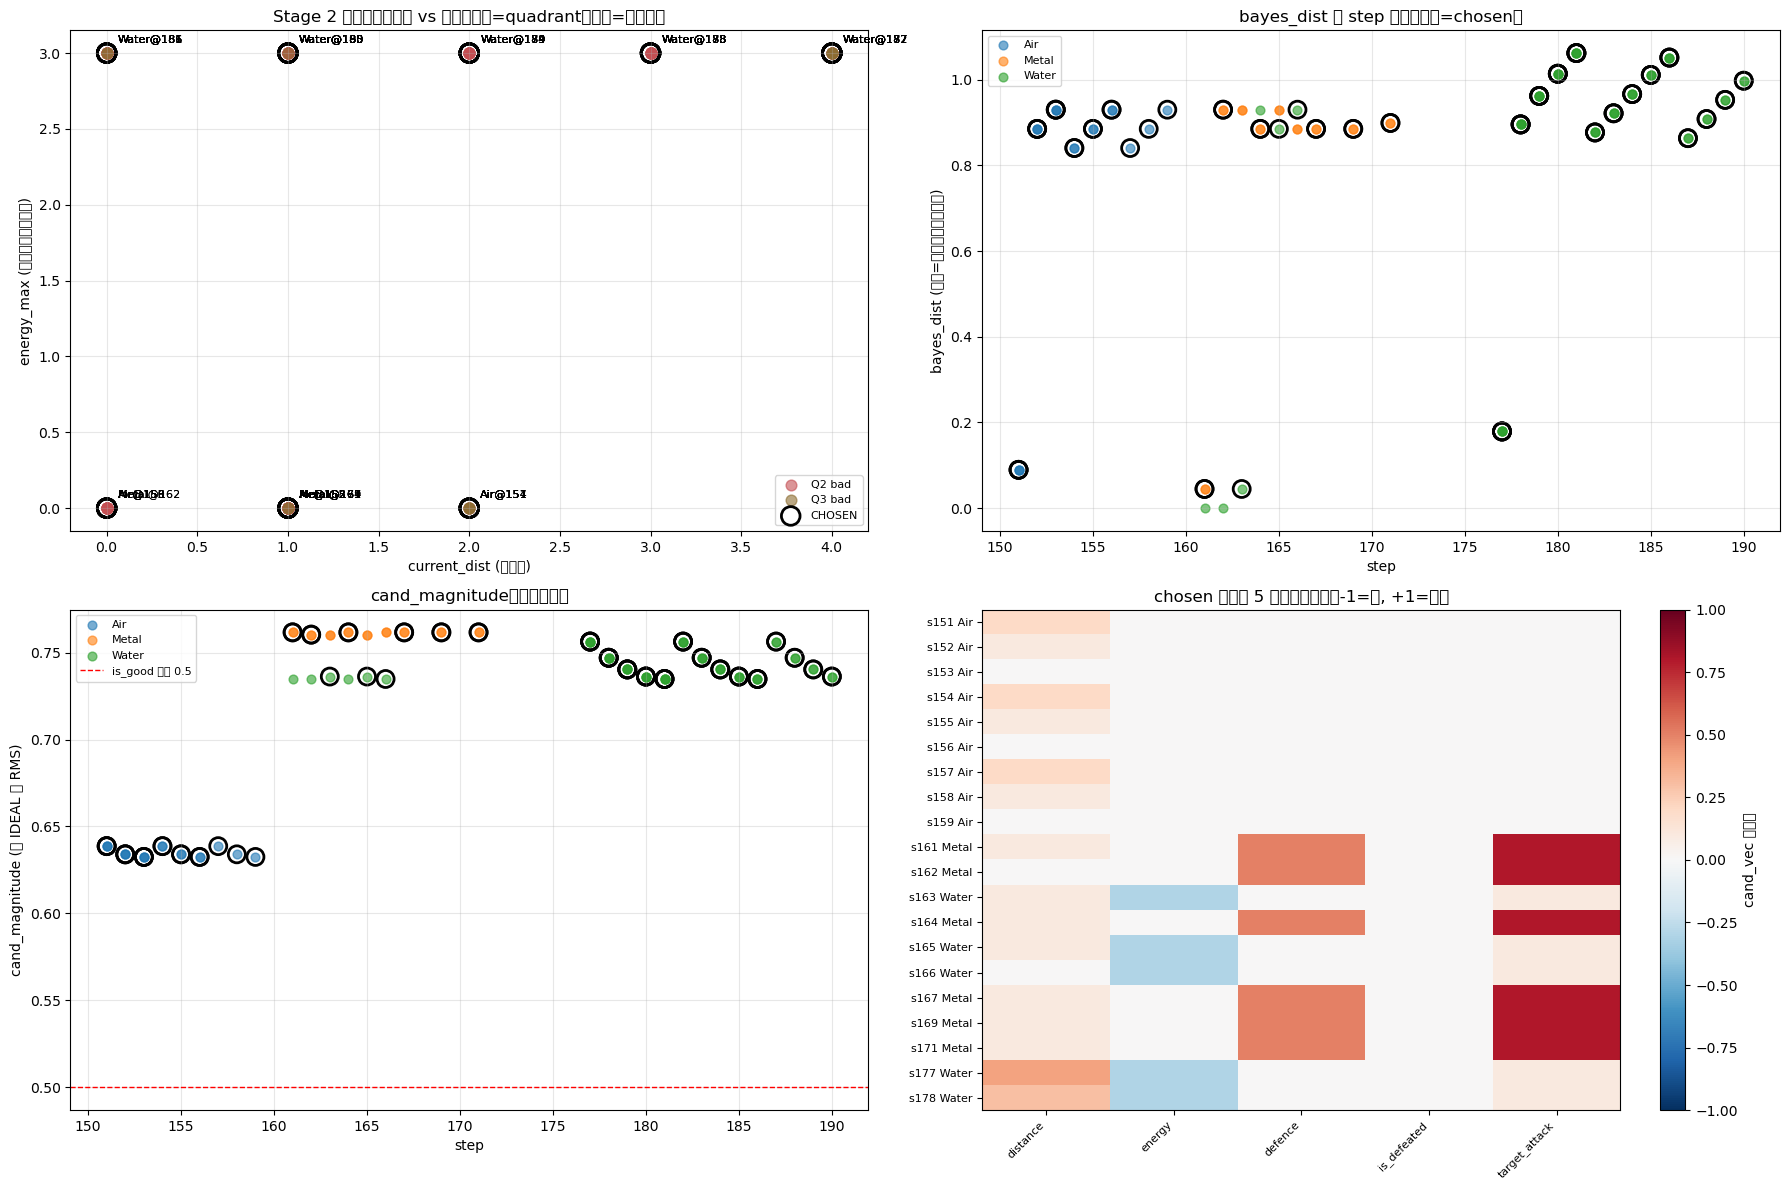


STEP 151  action=move  source=info_flow  energy=3
  chosen=Air  rejected_objs=[]
     obj  dist    E  def  atk    | bd  | mag             | quad  | C/G | chosen
----------------------------------------------------------------------------------------------------
     Air     2    0    0    0 |  0.0894 | 0.6387 |     Q3_bad_certain | T/F |       ★
     Air     2    0    0    0 |  0.0894 | 0.6387 |     Q3_bad_certain | T/F |       ★
     Air     2    0    0    0 |  0.0894 | 0.6387 |     Q3_bad_certain | T/F |       ★

STEP 152  action=move  source=info_flow  energy=3
  chosen=Air  rejected_objs=[]
     obj  dist    E  def  atk    | bd  | mag             | quad  | C/G | chosen
----------------------------------------------------------------------------------------------------
     Air     1    0    0    0 |  0.8852 | 0.6340 |   Q2_bad_uncertain | F/F |       ★
     Air     1    0    0    0 |  0.8852 | 0.6340 |   Q2_bad_uncertain | F/F |       ★
     Air     1    0    0    0 |  0.8852 | 0.

In [10]:
# ============================================================
# Cell S2-VIZ — Stage 2 每一步 Bayesian 计算 + 决策可视化
# 依赖：nursery_history（已有）
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import pandas as pd

# ---- 1. 切出 Stage 2 区间 ----
# 从 log 看：Stage 2 起点是 step 151（第一次 0.6.2 之后），
# 5 次 loop 覆盖 151 ~ 190。如果你想包含 exam，把 end 放到 190。
S2_START, S2_END = 151, 190

stage2_hist = [h for h in nursery_history if S2_START <= h.get("step", -1) <= S2_END]
print(f"Stage 2 共 {len(stage2_hist)} 步 (step {S2_START}~{S2_END})")


# ---- 2. 从 history 抽每个候选的 Bayesian 数值 ----
# nursery_history 里 bayes_trace 的 candidates 只存了部分字段
# （object / current_dist / known_defence / is_defeated_by_memory /
#   action_seq / move_to / is_chosen / energy_gain_max），
# 没有 cand_vec / mem_vec / bayes_dist / cand_magnitude / quadrant。
#
# 所以这里必须**重算**：用每一步 info_flow 里 objects 的 x,y,known_defence,
# energy_gain_records, steps_avg，调用 _rank_objects_by_energy_and_dist 重放。
#
# 但 _rank_objects_by_energy_and_dist 需要 a1 实例（用 a1.world / a1.parts）。
# 我们无法从 history 完美重建 a1 状态，所以下面用一个「离线重放」：
# 从 history 里能拿到的字段，逐个候选重算 bayes_dist。

def _flatten(d, prefix=""):
    out = {}
    if isinstance(d, dict):
        for k, v in d.items():
            out.update(_flatten(v, f"{prefix}.{k}" if prefix else str(k)))
    elif isinstance(d, (list, tuple)):
        for i, v in enumerate(d):
            out.update(_flatten(v, f"{prefix}[{i}]"))
    elif isinstance(d, bool):
        out[prefix] = 1.0 if d else 0.0
    elif isinstance(d, (int, float)):
        out[prefix] = float(d)
    elif d is None:
        out[prefix] = 0.0
    return out


def _bayes(a, b):
    keys = set(a) & set(b)
    if not keys:
        return float("inf")
    return float(np.sqrt(sum((a[k] - b[k]) ** 2 for k in keys) / len(keys)))


def replay_step_bayes(h):
    """
    从单步 history 重算每个候选的 Bayesian 数值。
    只用 history 里能拿到的字段；缺的维度补 0（并标注 missing）。
    """
    ap = h.get("action_plan") or {}
    bt = h.get("bayes_trace") or {}
    info = ap.get("info_flow") or {}
    chosen = bt.get("chosen") or {}
    objs = info.get("objects") or []

    # IDEAL_VEC 全局常量已在 notebook 顶部定义
    rows = []
    for o in objs:
        name = o.get("name")
        energy_recs = o.get("energy_gain_records") or []
        energy_max = max(energy_recs) if energy_recs else 0
        has_energy = len(energy_recs) > 0
        known_def = o.get("known_defence")
        known_atk = o.get("known_attack")
        is_def = o.get("is_defeated", False)
        is_def_mem = o.get("is_defeated_by_memory", False)
        eff_def = 0 if is_def or is_def_mem else (known_def if known_def is not None else 0)
        dist = None
        for c in bt.get("candidates", []):
            if c.get("object") == name:
                dist = c.get("current_dist"); break
        if dist is None:
            for c in bt.get("rejected", []):
                if c.get("object") == name:
                    dist = c.get("current_dist"); break
        # 如果连 dist 都没有，用 body 到 object 曼哈顿距离粗算
        if dist is None:
            body_pos = info.get("body_pos")
            if body_pos is None:
                body_pos = ap.get("body_pos")
            if body_pos is not None:
                bx, by = body_pos
            else:
                # 退化为 0（log 里大部分 info_flow 候选都带 current_dist）
                bx = by = o.get("x", 0)
            dist = abs(o.get("x", 0) - bx) + abs(o.get("y", 0) - by)

        # candidate vec（与 _rank_objects_by_energy_and_dist 对齐）
        cand_vec = {
            "distance":     float(dist) / 10.0,
            "energy":       -float(energy_max) / 10.0,
            "defence":      float(eff_def) / 10.0,
            "is_defeated":  -1.0 if (is_def or is_def_mem) else 0.0,
            "target_attack": float(known_atk or 0.0) / 10.0,
        }

        # memory vec：从 energy_recs / steps_avg 估
        steps_avg = o.get("steps_avg")
        mem_vec = {
            "distance":  float(np.log1p(steps_avg)) if steps_avg else 0.0,
            "energy":    -float(energy_max) / 10.0,
            "defence":   float(eff_def) / 10.0,
            "is_defeated": -1.0 if (is_def or is_def_mem) else 0.0,
            "target_attack": float(known_atk or 0.0) / 10.0,
        }

        bd = _bayes(_flatten(cand_vec), _flatten(mem_vec))

        # cand_magnitude：到 IDEAL 的 RMS
        keys = [k for k in cand_vec]
        mag = float(np.sqrt(sum((cand_vec[k] - IDEAL_VEC.get(k, 0.0)) ** 2
                                for k in keys) / len(keys)))

        is_certain = bd < 0.8
        is_good = mag < 0.5
        if not has_energy and (known_atk or 0) > 0:
            is_good = False
        if known_def is None and not (is_def or is_def_mem):
            is_certain = False

        if is_good and is_certain:
            q = QUADRANT_Q4
        elif is_good and not is_certain:
            q = QUADRANT_Q1
        elif (not is_good) and is_certain:
            q = QUADRANT_Q3
        else:
            q = QUADRANT_Q2

        is_chosen = (name == chosen.get("object"))
        rows.append({
            "step": h.get("step"),
            "energy": h.get("energy"),
            "action": ap.get("action"),
            "source": ap.get("source"),
            "obj": name,
            "x": o.get("x"), "y": o.get("y"),
            "current_dist": dist,
            "energy_max": energy_max,
            "has_energy_rec": has_energy,
            "known_defence": known_def,
            "known_attack": known_atk,
            "eff_defence": eff_def,
            "is_defeated": is_def,
            "is_defeated_by_memory": is_def_mem,
            "cand_vec": cand_vec,
            "mem_vec": mem_vec,
            "bayes_dist": round(bd, 4),
            "cand_magnitude": round(mag, 4),
            "quadrant": q,
            "is_certain": is_certain,
            "is_good": is_good,
            "is_chosen": is_chosen,
        })
    return rows


# ---- 3. 跑重放，得到 DataFrame ----
all_rows = []
for h in stage2_hist:
    if (h.get("action_plan") or {}).get("source") not in ("info_flow", "plan_execution"):
        continue
    rows = replay_step_bayes(h)
    if rows:
        all_rows.extend(rows)

df_s2 = pd.DataFrame(all_rows)
print(f"重放得到 {len(df_s2)} 条候选记录，覆盖 "
      f"{df_s2['step'].nunique()} 个 info_flow 决策步")
print()
print("每步 chosen 物体：")
print(df_s2[df_s2["is_chosen"]][["step", "obj", "current_dist",
                                  "energy_max", "known_defence",
                                  "bayes_dist", "cand_magnitude", "quadrant"]]
      .to_string(index=False))

# ---- 4. 可视化 ----
if df_s2.empty:
    print("⚠️ df_s2 为空，检查 S2_START/S2_END 或 info_flow 是否存在")
else:
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))

    # ---- (a) 全局候选散点：x=dist, y=energy_max, 颜色=quadrant ----
    ax = axes[0, 0]
    q_colors = {
        QUADRANT_Q1: "#4C72B0",   # good-uncertain 蓝
        QUADRANT_Q2: "#C44E52",   # bad-uncertain 红
        QUADRANT_Q3: "#8C6D31",   # bad-certain 棕
        QUADRANT_Q4: "#55A868",   # good-certain 绿
    }
    for q, c in q_colors.items():
        sub = df_s2[df_s2["quadrant"] == q]
        if sub.empty: continue
        ax.scatter(sub["current_dist"], sub["energy_max"],
                   c=c, s=60, alpha=0.6,
                   label=q.split("_")[0] + " " + q.split("_")[1])
    # chosen 加黑框
    ch = df_s2[df_s2["is_chosen"]]
    ax.scatter(ch["current_dist"], ch["energy_max"],
               facecolors="none", edgecolors="black", s=180,
               linewidths=2, label="CHOSEN")
    for _, r in ch.iterrows():
        ax.annotate(f"{r['obj']}@{r['step']}",
                    (r["current_dist"], r["energy_max"]),
                    textcoords="offset points", xytext=(8, 8), fontsize=8)
    ax.set_xlabel("current_dist (曼哈顿)")
    ax.set_ylabel("energy_max (最大观测能量增益)")
    ax.set_title("Stage 2 全部候选：距离 vs 能量（颜色=quadrant，黑框=被选中）")
    ax.legend(loc="best", fontsize=8)
    ax.grid(alpha=0.3)

    # ---- (b) bayes_dist 散点：x=step, y=bayes_dist, 颜色=obj ----
    ax = axes[0, 1]
    for name, sub in df_s2.groupby("obj"):
        marker = "o" if name != "Metal" else "s"
        ax.scatter(sub["step"], sub["bayes_dist"], label=name, s=40, alpha=0.6)
    # chosen 用黑框
    ax.scatter(ch["step"], ch["bayes_dist"],
               facecolors="none", edgecolors="black", s=150, linewidths=2)
    ax.set_xlabel("step")
    ax.set_ylabel("bayes_dist (越小=越像历史成功经验)")
    ax.set_title("bayes_dist 随 step 变化（黑框=chosen）")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    # ---- (c) cand_magnitude 散点：x=step, y=cand_magnitude ----
    ax = axes[1, 0]
    for name, sub in df_s2.groupby("obj"):
        ax.scatter(sub["step"], sub["cand_magnitude"], label=name, s=40, alpha=0.6)
    ax.scatter(ch["step"], ch["cand_magnitude"],
               facecolors="none", edgecolors="black", s=150, linewidths=2)
    ax.axhline(0.5, color="red", linestyle="--", linewidth=1,
               label="is_good 阈值 0.5")
    ax.set_xlabel("step")
    ax.set_ylabel("cand_magnitude (到 IDEAL 的 RMS)")
    ax.set_title("cand_magnitude（越小越好）")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    # ---- (d) 单步 6 维向量差异热力图（只画 chosen 步） ----
    ax = axes[1, 1]
    chosen_steps = sorted(ch["step"].unique())[:20]  # 最多 20 个 step
    dims = list(IDEAL_VEC.keys())
    mat = np.full((len(chosen_steps), len(dims)), np.nan)
    row_labels = []
    for i, s in enumerate(chosen_steps):
        sub = df_s2[(df_s2["step"] == s) & df_s2["is_chosen"]]
        if sub.empty: continue
        r = sub.iloc[0]
        row_labels.append(f"s{s} {r['obj']}")
        for j, d in enumerate(dims):
            mat[i, j] = r["cand_vec"].get(d, 0.0)
    im = ax.imshow(mat, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(dims)))
    ax.set_xticklabels(dims, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(row_labels)))
    ax.set_yticklabels(row_labels, fontsize=8)
    plt.colorbar(im, ax=ax, label="cand_vec 维度值")
    ax.set_title("chosen 候选的 5 维向量热力图（-1=好, +1=坏）")

    plt.tight_layout()
    plt.show()
    
    # ---- 5. 每个 info_flow 决策步打印所有候选的 5 维向量 + bayes_dist ----
def dump_bayes_step(s):
    sub = df_s2[df_s2["step"] == s].sort_values("bayes_dist")
    if sub.empty: return
    h = next((x for x in stage2_hist if x.get("step") == s), None)
    ap = (h or {}).get("action_plan") or {}
    bt = (h or {}).get("bayes_trace") or {}
    print(f"\n{'='*100}")
    print(f"STEP {s}  action={ap.get('action')}  source={ap.get('source')}  "
          f"energy={h.get('energy') if h else '?'}")
    print(f"  chosen={bt.get('chosen', {}).get('object')}  "
          f"rejected_objs={[r.get('object') for r in bt.get('rejected', [])]}")
    print(f"  {'obj':>6} {'dist':>5} {'E':>4} {'def':>4} {'atk':>4} "
          f"{'| bd':>7} {'| mag':>6} {'| quad':>18} {'| C/G':>6} {'| chosen':>7}")
    print("-" * 100)
    for _, r in sub.iterrows():
        cv = r["cand_vec"]
        print(f"  {r['obj']:>6} {r['current_dist']:>5} {r['energy_max']:>4} "
              f"{r['known_defence'] if r['known_defence'] is not None else '-':>4} "
              f"{r['known_attack'] if r['known_attack'] is not None else '-':>4} "
              f"{'|':>1} {r['bayes_dist']:>7.4f} {'|':>1} {r['cand_magnitude']:>6.4f} "
              f"{'|':>1} {r['quadrant']:>18} {'|':>1} "
              f"{'T' if r['is_certain'] else 'F'}/{'T' if r['is_good'] else 'F':>1} "
              f"{'|':>1} {'★' if r['is_chosen'] else '':>7}")

# 只打印前 10 个决策步
for s in sorted(df_s2["step"].unique())[:10]:
    dump_bayes_step(s)

## Real World Construction

In [28]:
import inspect

#=============================================================
#    Cell R1 — Verify the two prior fixes are actually live
#=============================================================

# Fix 1: A1.__init__ accepts memory_bank
sig = inspect.signature(A1.__init__)
assert "memory_bank" in sig.parameters, "A1.__init__ missing memory_bank param — apply Edit 1"
print("A1.__init__ memory_bank: OK")

# Fix 2: collapse_memory has exactly one rebind (7-key)
# src_cm = inspect.getsource(A1.collapse_memory)
# assert src_cm.count("self.memories = {") == 1, "collapse_memory has extra rebind — Edit 2 not applied"
# assert "DECISION_MEMORY, DECISION_FORBIDDEN_MEMORY," in src_cm, "collapse_memory 7-key missing"
# print("collapse_memory: OK")

# Fix 3: migrate_a1_to_scene rebuilds 7 keys
src_mig = inspect.getsource(migrate_a1_to_scene)
assert "DECISION_MEMORY" in src_mig, "migrate_a1_to_scene 5-key rebind — still broken"
print("migrate_a1_to_scene: OK")

# Fix 4: WorldMap.tick exists (safe default no-op)
assert hasattr(WorldMap, "tick"), "WorldMap.tick missing — add the no-op stub"
print("WorldMap.tick: OK")

# Fix 5: SharedMemoryBank defined
assert "SharedMemoryBank" in globals(), "SharedMemoryBank not defined"
print("SharedMemoryBank: OK")

A1.__init__ memory_bank: OK
migrate_a1_to_scene: OK
WorldMap.tick: OK
SharedMemoryBank: OK


In [29]:
#=============================================================
#    Cell R2 — Nursery → shared bank (do this once)
#=============================================================

# Run nursery if not already cached in this kernel
if "a1_final" not in globals() or a1_final is None:
    a1_final, _hist, nursery_history, learning_reports, \
        memory_snapshots, stage2_learning_results = run_nursery(
            verbose=False, max_retries=1
        )

# Build the shared bank from nursery's collapsed memory
shared_bank = SharedMemoryBank.from_a1(a1_final)

print("Nursery collapsed memory carry-forward:")
for k, n in shared_bank.stats().items():
    print(f"  {k:30s} {n}")

Nursery collapsed memory carry-forward:
  Foot_Memory                    249
  Hand_Memory                    82
  Observation_Memory             82
  Proprio_Memory                 82
  Forbidden_Memory               50
  Decision_Memory                37
  Decision_Forbidden_Memory      4


In [30]:
#=============================================================
#    Cell R3 — The real-world harness
#=============================================================

# =====================================================================
# Complex Real World — SacredGrove + RealWorldMap + RealWorld
# =====================================================================
from dataclasses import dataclass, field

class SacredGrove:
    """3x3 safe patch with a regenerating Wood at the centre.

    Layout (relative to top-left):
        row 0:  Air    Air    Air
        row 1:  Air    WOOD   Air
        row 2:  Earth  Water  Metal

    When the centre Wood is eaten, a respawn is scheduled after
    `regrow_after_steps` world ticks. The other 8 cells are static.
    """

    LAYOUT = [
        ("Air",   "Air",   "Air"),
        ("Air",   "WOOD",  "Air"),
        ("Earth", "Water", "Metal"),
    ]

    def __init__(self, top_left_xy, regrow_after_steps=30):
        self.x0, self.y0 = top_left_xy
        self.regrow_after = regrow_after_steps
        self.center_xy = (self.x0 + 1, self.y0 + 1)
        self.respawn_timer = None
        self.eat_count = 0

    def stamp_into(self, world):
        for dy, row in enumerate(self.LAYOUT):
            for dx, name in enumerate(row):
                lot = world.get_lot_by_xy(self.x0 + dx, self.y0 + dy)
                if lot is None:
                    continue
                if name == "WOOD":
                    lot.element = "Wood"
                    lot.defeated_element = None
                else:
                    lot.element = name
                    lot.defeated_element = None

    def on_center_eaten(self):
        self.respawn_timer = self.regrow_after
        self.eat_count += 1

    def tick(self, world):
        if self.respawn_timer is None:
            return
        self.respawn_timer -= 1
        if self.respawn_timer <= 0:
            cx, cy = self.center_xy
            lot = world.get_lot_by_xy(cx, cy)
            if lot is not None and lot.element is None and lot.defeated_element is None:
                lot.element = "Wood"
            self.respawn_timer = None


class RealWorldMap(WorldMap):
    """WorldMap with richness/dryness/weights + sacred grove ticking."""

    def __init__(self, size=20, elements=None,
                 richness=0.15, dryness=0.3,
                 weights=None, groves=None):
        self.richness = richness
        self.dryness = dryness
        self.base_weights = dict(weights or {
            "Water": 1.0, "Earth": 1.0, "Wood": 1.0, "Metal": 0.3,
        })
        self.groves = list(groves or [])
        # bypass base placement; do weighted placement ourselves
        super().__init__(size=size, elements=None)

        if elements == "random" or elements is None:
            self._place_weighted_elements()
        else:
            self._place_specific_elements(elements)
            for g in self.groves:
                g.stamp_into(self)

    def _place_weighted_elements(self):
        w = dict(self.base_weights)
        if "Water" in w:
            w["Water"] *= max(0.0, 1.0 - self.dryness)
        total = sum(w.values())
        if total <= 0:
            return
        names = list(w.keys())
        probs = [w[n] / total for n in names]
        for lot in self.lots.values():
            if random.random() > self.richness:
                continue
            name = random.choices(names, weights=probs, k=1)[0]
            lot.element = name
        for g in self.groves:
            g.stamp_into(self)

    def tick(self, actor_before=None, actor_after=None):
        for g in self.groves:
            if actor_after is not None:
                res = actor_after.get("result", {}) or {}
                det = res.get("detail", {}) if isinstance(res.get("detail"), dict) else {}
                if res.get("success") and det.get("eaten") == "Wood":
                    bl = actor_after.get("body_after")
                    if bl is not None and (bl.x, bl.y) == g.center_xy:
                        g.on_center_eaten()
            g.tick(self)


@dataclass
class RealWorldConfig:
    size: int = 20
    n_agents: int = 3
    steps: int = 2000
    richness: float = 0.15
    dryness: float = 0.30
    n_groves: int = 1
    grove_regrow: int = 30
    initial_energy: int = 10
    weights: Optional[Dict[str, float]] = None
    seed: Optional[int] = None


class RealWorld:
    def __init__(self, config, memory_bank):
        self.cfg = config
        self.bank = memory_bank
        self.world = None
        self.agents = []
        self.history = []
        if config.seed is not None:
            random.seed(config.seed)

    def _make_groves(self):
        s = self.cfg.size
        groves = []
        for _ in range(self.cfg.n_groves):
            x = random.randint(1, max(1, s - 4))
            y = random.randint(1, max(1, s - 4))
            groves.append(SacredGrove((x, y), regrow_after_steps=self.cfg.grove_regrow))
        return groves

    def _make_agents(self):
        s = self.cfg.size
        cx, cy = s // 2, s // 2
        ring_r = max(2, s // 6)
        agents = []
        for i in range(self.cfg.n_agents):
            ang = 2 * math.pi * i / max(1, self.cfg.n_agents)
            x = int(round(cx + ring_r * math.cos(ang)))
            y = int(round(cy + ring_r * math.sin(ang)))
            x = max(0, min(s - 1, x))
            y = max(0, min(s - 1, y))
            lot_id = y * s + x
            a = A1(self.world, start_lot_id=lot_id, memory_bank=self.bank)
            a.energy = self.cfg.initial_energy
            a.alive = True
            agents.append(a)
        return agents

    def _body_lot(self, agent):
        return self.world.get_lot(agent.part_positions[BODY])

    def run(self, verbose=True):
        self.world = RealWorldMap(
            size=self.cfg.size,
            elements="random",
            richness=self.cfg.richness,
            dryness=self.cfg.dryness,
            weights=self.cfg.weights,
            groves=self._make_groves(),
        )
        self.agents = self._make_agents()
        for a in self.agents:
            self.world.place_a1(a)

        for step in range(self.cfg.steps):
            if not any(a.alive for a in self.agents):
                break
            for i, a in enumerate(self.agents):
                if not a.alive:
                    continue
                body_before = self._body_lot(a)
                step_result = a.run_one_step()
                step_result["agent_id"] = i
                step_result["body_before"] = body_before
                step_result["body_after"] = self._body_lot(a)
                self.history.append(step_result)
                # grove tick reads the last action's result
                self.world.tick(actor_before=None, actor_after=step_result)
            if verbose and step % 50 == 0:
                alive = sum(1 for a in self.agents if a.alive)
                print(f"[REAL] step={step:4d} alive={alive}/{len(self.agents)} "
                      f"groves_eaten={[g.eat_count for g in self.world.groves]} "
                      f"bank={self.bank.stats()}")
        return self.history

    def summary(self):
        eaten_by_agent = {}
        eaten_total = {}
        for h in self.history:
            d = (h.get("result") or {}).get("detail") or {}
            el = d.get("eaten")
            if not el:
                continue
            eaten_total[el] = eaten_total.get(el, 0) + 1
            aid = h.get("agent_id")
            eaten_by_agent.setdefault(aid, {})
            eaten_by_agent[aid][el] = eaten_by_agent[aid].get(el, 0) + 1

        alive = [i for i, a in enumerate(self.agents) if a.alive]
        return {
            "n_agents": len(self.agents),
            "alive_agents": alive,
            "steps_run": len(self.history),
            "total_steps_per_agent": [len([h for h in self.history if h.get("agent_id") == i])
                                       for i in range(len(self.agents))],
            "eaten_total": eaten_total,
            "eaten_by_agent": eaten_by_agent,
            "groves": [{"top_left": (g.x0, g.y0),
                        "center": g.center_xy,
                        "eat_count": g.eat_count}
                       for g in self.world.groves],
            "bank": self.bank.stats(),
        }

In [31]:
import inspect

# ---- 1. Show what Grove.tick actually is in this kernel ----
print("=" * 60)
print("Grove.tick source:")
print(inspect.getsource(Grove.tick))

# ---- 2. Build a world with one seed parent ----
g = Grove(size=10, regrow_every=1)
g.get_lot_by_xy(5, 5).element = "Wood"

print("=" * 60)
print("regrow_every =", g.regrow_every)
print("_tick_n     =", getattr(g, "_tick_n", "MISSING"))

# ---- 3. Tick once, print what it returned ----
ev = g.tick()
print("tick() returned:", ev)

# ---- 4. Walk the 4 neighbours and print what's there ----
for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
    nb = g.get_lot_by_xy(5 + dx, 5 + dy)
    print(f"  ({5+dx},{5+dy})  element={nb.element!r}  "
          f"defeated={nb.defeated_element!r}  occupied={nb.occupied_by!r}")

Grove.tick source:
    def tick(self, step=0, time_of_day=0.0, agents=None):
        self._tick += 1
        events = []

        if self._tick % self.regrow_every != 0:
            return events                       # not yet

        # find empty lots next to an existing Wood lot
        source_lots = [
            lot for lot in self.lots.values()
            if lot.element == "Wood"
        ]
        if not source_lots:
            return events

        for src in source_lots:
            for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                nb = self.get_lot_by_xy(src.x + dx, src.y + dy)
                if nb is None:
                    continue
                if nb.element is None and nb.defeated_element is None and nb.occupied_by is None:
                    nb.element = "Wood"                    # ← the actual mutation
                    events.append({
                        "type": "grow",
                        "from": (src.x, src.y),
                     

In [32]:
# ============================================================
# Cell R4 — Smoke test (no full run yet)
# ============================================================

# --- Layer 1: grove layout ---
tmp_world = RealWorldMap(
    size=10, elements="random",
    richness=0.1, dryness=0.3,
    groves=[SacredGrove((3, 3), regrow_after_steps=5)],
)
g = tmp_world.groves[0]
for dy, row in enumerate(SacredGrove.LAYOUT):
    for dx, name in enumerate(row):
        lot = tmp_world.get_lot_by_xy(g.x0 + dx, g.y0 + dy)
        expected = "Wood" if name == "WOOD" else name
        assert lot.element == expected, f"grove layout wrong at ({g.x0+dx},{g.y0+dy})"
print("Layer 1 — grove layout: OK")

# Layer 2 — grove regrowth
g = Grove(size=10, regrow_every=1)
g.get_lot_by_xy(5, 5).element = "Wood"

before = {(lot.x, lot.y) for lot in g.lots.values() if lot.element == "Wood"}
assert before == {(5, 5)}, f"seed failed: {before}"

g.tick()

after = {(lot.x, lot.y) for lot in g.lots.values() if lot.element == "Wood"}
new = after - before

assert new, f"regrow failed: no new Wood appeared; after={after}"
for nx, ny in new:
    assert any(
        (nx + dx, ny + dy) in before
        for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]
    ), f"new Wood at ({nx},{ny}) not adjacent to parent"

print(f"Layer 2 — grove regrowth: OK  new={new}")

# --- Layer 3: shared memory + nursery carry-forward ---
a0 = A1(tmp_world, start_lot_id=0, memory_bank=shared_bank)
a1 = A1(tmp_world, start_lot_id=10, memory_bank=shared_bank)
a0.collapsed_memory[FOOT_MEMORY]["__probe__"] = {"counter": 1}
assert "__probe__" in a1.collapsed_memory[FOOT_MEMORY], "sharing broken"
del a0.collapsed_memory[FOOT_MEMORY]["__probe__"]
assert len(shared_bank.collapsed_memory[FOOT_MEMORY]) >= 1, "nursery carry-forward lost"
print("Layer 3 — shared memory + carry-forward: OK")

# --- Layer 4: collapse_memory preserves sharing ---
a0.collapse_memory(verbose=False)
assert a0.memories is not None  # L1 cleared in place, not rebound
# sharing still holds because a0.collapsed_memory is still the bank's dict
a0.collapsed_memory[FOOT_MEMORY]["__probe2__"] = {"counter": 1}
assert "__probe2__" in shared_bank.collapsed_memory[FOOT_MEMORY]
del a0.collapsed_memory[FOOT_MEMORY]["__probe2__"]
print("Layer 4 — collapse preserves sharing: OK")

Layer 1 — grove layout: OK
Layer 2 — grove regrowth: OK  new={(4, 5)}
Layer 3 — shared memory + carry-forward: OK
Layer 4 — collapse preserves sharing: OK


## Real World Run

In [33]:
# ============================================================
# Cell R5 — Tiny real-world run (debug, ~5s)  + Excel 导出
# ============================================================

import pandas as pd
import json
import pprint
from datetime import datetime
from pathlib import Path

# ---------- 1) 配置 + 运行 ----------
cfg_smoke = RealWorldConfig(
    size=10, n_agents=1, steps=100000,
    richness=0.20, dryness=0.30,
    n_groves=1, grove_regrow=10,
    initial_energy=8,
    seed=42,
)
rw_smoke = RealWorld(cfg_smoke, shared_bank)
rw_smoke_history = rw_smoke.run(verbose=True)

print("\n--- smoke summary ---")
pprint.pprint(rw_smoke.summary())

# ---------- 2) 确认 history 结构 ----------
print("\n--- history 结构 ---")
print("type:", type(rw_smoke_history))
print("len :", len(rw_smoke_history))
if rw_smoke_history and isinstance(rw_smoke_history[0], dict):
    print("top-level keys:", list(rw_smoke_history[0].keys()))

# ---------- 3) 拍平函数 ----------
def _get_energy(h):
    """energy 可能在顶层、state.proprio、或 result.post_state 里。"""
    e = h.get("energy")
    if e is not None:
        return e
    st = h.get("state") or {}
    pr = st.get("proprio") or {}
    if pr.get("energy") is not None:
        return pr["energy"]
    ps = (h.get("result") or {}).get("post_state") or {}
    return ps.get("energy")

def _get_agent_id(h):
    aid = h.get("agent_id", h.get("agent"))
    if aid is None:
        st = h.get("state") or {}
        aid = st.get("agent_id", st.get("agent"))
    return aid

def flatten_entry(h):
    ap = h.get("action_plan") or {}
    ev = ap.get("eval") or {}
    wp = ev.get("what_pred") or {}
    dp = ap.get("distance_pred") or ev.get("distance_pred") or {}
    detail = ev.get("detail")
    reason = detail.get("reason") if isinstance(detail, dict) else detail
    rs = h.get("result") or {}
    rd = rs.get("detail") if isinstance(rs.get("detail"), dict) else {}
    return {
        "step":               h.get("step"),
        "agent_id":           _get_agent_id(h),
        "alive":              h.get("alive"),
        "energy":             _get_energy(h),
        "action":             ap.get("action"),
        "source":             ap.get("source"),
        "route":              ap.get("route"),
        "reason":             reason,
        "pred_success":       ev.get("predicted_success"),
        "pred_need_resolved": ev.get("predicted_need_resolved"),
        "pred_energy_change": ev.get("predicted_energy_change"),
        "feasible":           ev.get("feasible"),
        "target_element":     wp.get("element"),
        "pred_attack":        wp.get("predicted_attack"),
        "pred_defence":       wp.get("predicted_defence"),
        "pred_energy":        wp.get("predicted_energy"),
        "dist_steps":         dp.get("steps"),
        "dist_energy_cost":   dp.get("energy_cost"),
        "result_action":      rs.get("action"),
        "result_success":     rs.get("success"),
        "result_eaten":       rd.get("eaten"),
        "result_energy_gain": rd.get("energy_gained"),
    }

df = pd.DataFrame([flatten_entry(h) for h in rw_smoke_history])
print("\n--- flattened df ---")
print("shape:", df.shape)
print(df.head(20).to_string())

# ---------- 4) 按 agent 打印 ----------
print("\n--- 按 agent 概览 ---")
for aid in sorted(df["agent_id"].dropna().unique()):
    sub = df[df["agent_id"] == aid]
    print(f"\n=== agent {int(aid)}: {len(sub)} 步 ===")
    cols = [c for c in ["step", "action", "source", "reason",
                         "energy", "target_element", "result_success"] if c in sub.columns]
    print(sub[cols].to_string(index=False))


# ---------- 5) 导出 Excel（每次文件名唯一，自动存档） ----------


ts = datetime.now().strftime("%Y%m%d_%H%M%S")
archive_dir = Path("rw_archive") / datetime.now().strftime("%Y%m%d")
archive_dir.mkdir(parents=True, exist_ok=True)

out_path = archive_dir / (
    f"rw_smoke_{ts}"
    f"_seed{cfg_smoke.seed}"
    f"_n{cfg_smoke.n_agents}"
    f"_steps{cfg_smoke.steps}"
    f".xlsx"
)

with pd.ExcelWriter(out_path, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="all", index=False)
    for aid in sorted(df["agent_id"].dropna().unique()):
        df[df["agent_id"] == aid].to_excel(
            writer, sheet_name=f"agent_{int(aid)}", index=False)

print(f"\n✅ 已导出 {out_path.resolve()}")

[REAL] step=   0 alive=1/1 groves_eaten=[0] bank={'Foot_Memory': 249, 'Hand_Memory': 82, 'Observation_Memory': 82, 'Proprio_Memory': 82, 'Forbidden_Memory': 50, 'Decision_Memory': 37, 'Decision_Forbidden_Memory': 4}
[REAL] step=  50 alive=1/1 groves_eaten=[1] bank={'Foot_Memory': 249, 'Hand_Memory': 82, 'Observation_Memory': 82, 'Proprio_Memory': 82, 'Forbidden_Memory': 50, 'Decision_Memory': 37, 'Decision_Forbidden_Memory': 4}
[REAL] step= 100 alive=1/1 groves_eaten=[4] bank={'Foot_Memory': 249, 'Hand_Memory': 82, 'Observation_Memory': 82, 'Proprio_Memory': 82, 'Forbidden_Memory': 50, 'Decision_Memory': 37, 'Decision_Forbidden_Memory': 4}
[REAL] step= 150 alive=1/1 groves_eaten=[7] bank={'Foot_Memory': 249, 'Hand_Memory': 82, 'Observation_Memory': 82, 'Proprio_Memory': 82, 'Forbidden_Memory': 50, 'Decision_Memory': 37, 'Decision_Forbidden_Memory': 4}
[REAL] step= 200 alive=1/1 groves_eaten=[10] bank={'Foot_Memory': 249, 'Hand_Memory': 82, 'Observation_Memory': 82, 'Proprio_Memory': 82


✅ 已导出 C:\Users\lgzaw\Desktop\ottawa\phD DTI\conciousness hardship test\separate papers\rw_archive\20261028\rw_smoke_20261028_202451_seed42_n1_steps100000.xlsx


Grove

body_before: Lot(x=7, y=5, lot_id=57, element=None, occupied_by='Body', defeated_element=None)
body_after : Lot(x=6, y=5, lot_id=56, element=None, occupied_by='L_Hand', defeated_element=None)
type(body_after): <class '__main__.Lot'>

df shape: (490, 8)
   step  x  y  action target  energy  alive  agent_id
0     1  6  5    move  Earth       8   True         0
1     2  6  4    move  Earth       8   True         0
2     3  6  3    move  Earth       8   True         0
3     4  6  2    move  Earth       7   True         0
4     5  6  1    move  Earth       7   True         0
5     6  6  0    move  Earth       7   True         0
6     7  6  0  attack  Earth       6   True         0
7     8  5  0    move  Earth       5   True         0
8     9  4  0    move  Earth       5   True         0
9    10  3  0    move  Earth       4   True         0

总步数: 490, 在 grove 内: 398 步

=== grove 内的步 ===
 step  x  y             action target  energy
    3  6  3               move  Earth       8
    4  6  2   

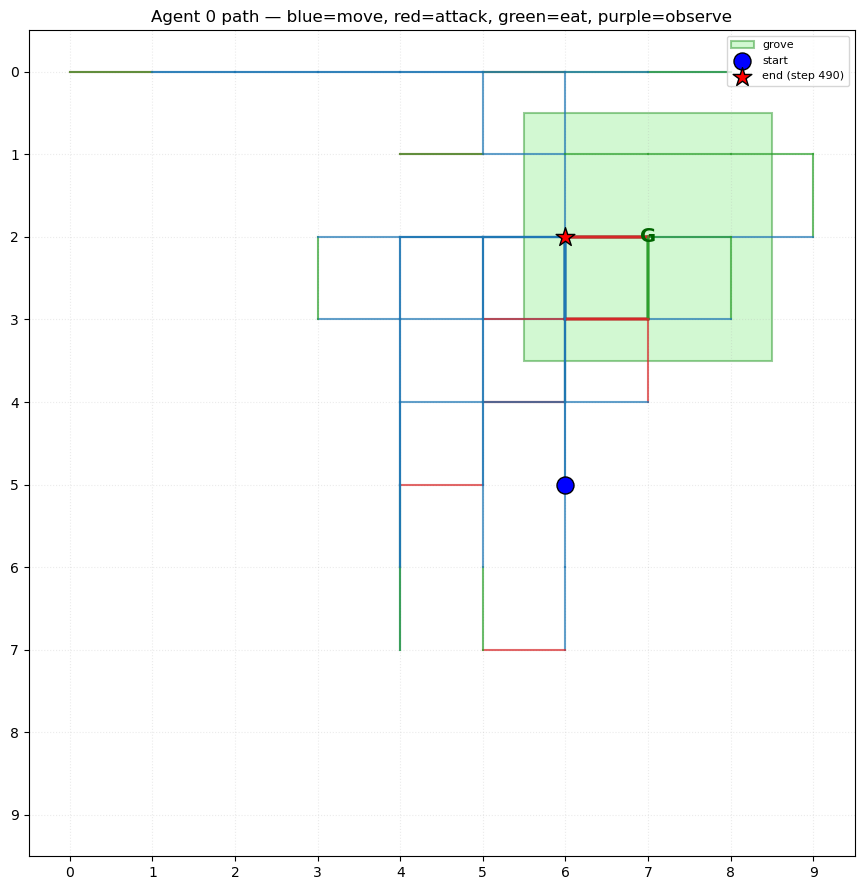

In [39]:
# ============================================================
# Cell — 分析 agent 在 grove 的步 + 画路径（Lot 对象版）
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ---------- 1) 探测 body_after / body_before 结构 ----------
h0 = rw_smoke_history[0]
print("body_before:", repr(h0.get("body_before")))
print("body_after :", repr(h0.get("body_after")))
print("type(body_after):", type(h0.get("body_after")))

# ---------- 2) 从 Lot 对象 / dict / int 抽 (x, y) ----------
def get_xy(h):
    """body_after/body_before 是 Lot 对象时直接取 .x/.y；dict 取 x/y；int 按 row-major 换。"""
    for key in ("body_after", "body_before"):
        ba = h.get(key)
        if ba is None:
            continue
        # Lot 对象：直接有 .x / .y
        if hasattr(ba, "x") and hasattr(ba, "y"):
            return ba.x, ba.y
        # dict
        if isinstance(ba, dict):
            if "x" in ba and "y" in ba:
                return ba["x"], ba["y"]
            if "Body" in ba and isinstance(ba["Body"], int):
                lot = ba["Body"]
                return lot % 10, lot // 10
        # int（lot_id）
        if isinstance(ba, int):
            return ba % 10, ba // 10
    return None, None

rows = []
for h in rw_smoke_history:
    x, y = get_xy(h)
    if x is None:
        continue
    ap = h.get("action_plan") or {}
    ev = ap.get("eval") or {}
    rows.append({
        "step":   h.get("step"),
        "x":      x,
        "y":      y,
        "action": ap.get("action"),
        "target": (ev.get("what_pred") or {}).get("element"),
        "energy": h.get("energy"),
        "alive":  h.get("alive"),
        "agent_id": h.get("agent_id"),
    })

df = pd.DataFrame(rows)
print("\ndf shape:", df.shape)
print(df.head(10).to_string())

# ---------- 3) grove 内筛步（向量化，空 df 也不崩） ----------
GROVE_X = (6, 8)
GROVE_Y = (1, 3)

if not df.empty:
    df["in_grove"] = (
        (df["x"] >= GROVE_X[0]) & (df["x"] <= GROVE_X[1]) &
        (df["y"] >= GROVE_Y[0]) & (df["y"] <= GROVE_Y[1])
    )

    print(f"\n总步数: {len(df)}, 在 grove 内: {df.in_grove.sum()} 步")
    print("\n=== grove 内的步 ===")
    print(df[df.in_grove][["step", "x", "y", "action", "target", "energy"]]
          .to_string(index=False))

    grove_eats = df[df.in_grove & (df.action == "eat")]
    print(f"\n=== grove 内 eat 次数: {len(grove_eats)} ===")
    if not grove_eats.empty:
        print(grove_eats[["step", "x", "y", "target", "energy"]].to_string(index=False))
        print("\ntarget 分布:", grove_eats.target.value_counts().to_dict())
else:
    print("⚠️ df 为空，跳过 grove 分析")

# ---------- 4) 抽路径（Lot 对象版） ----------
def extract_agent_path_v2(history):
    path = []
    for h in history:
        x, y = get_xy(h)
        if x is None:
            continue
        ap = h.get("action_plan") or {}
        path.append((h.get("step"), x, y, ap.get("action")))
    return path

path = extract_agent_path_v2(rw_smoke_history)
print(f"\n路径点数: {len(path)}, 前 5: {path[:5]}")

# ---------- 5) 画图 ----------
size = 10
fig, ax = plt.subplots(figsize=(9, 9))

# grove
ax.add_patch(patches.Rectangle((GROVE_X[0] - 0.5, GROVE_Y[0] - 0.5),
                               GROVE_X[1] - GROVE_X[0] + 1,
                               GROVE_Y[1] - GROVE_Y[0] + 1,
                               facecolor="lightgreen", alpha=0.4,
                               edgecolor="green", linewidth=1.5, label="grove"))
cx = (GROVE_X[0] + GROVE_X[1]) / 2
cy = (GROVE_Y[0] + GROVE_Y[1]) / 2
ax.text(cx, cy, "G", fontsize=14, ha="center", va="center",
        color="darkgreen", fontweight="bold")

# 路径按 action 上色
color_map = {"move": "#1f77b4", "attack": "#d62728", "eat": "#2ca02c",
             "observe": "#9467bd", "drop": "#8c564b",
             "passive_starvation": "black"}
for i in range(len(path) - 1):
    _, x0, y0, act0 = path[i]
    _, x1, y1, _ = path[i + 1]
    ax.plot([x0, x1], [y0, y1], "-", color=color_map.get(act0, "gray"),
            linewidth=1.5, alpha=0.7)

# 起点/终点
if path:
    ax.scatter(path[0][1], path[0][2], s=150, c="blue", marker="o",
               edgecolors="black", zorder=5, label="start")
    last_step = path[-1][0]
    ax.scatter(path[-1][1], path[-1][2], s=200, c="red", marker="*",
               edgecolors="black", zorder=5, label=f"end (step {last_step})")

ax.set_xlim(-0.5, size - 0.5)
ax.set_ylim(-0.5, size - 0.5)
ax.set_xticks(range(size))
ax.set_yticks(range(size))
ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.25)
ax.invert_yaxis()
ax.set_title("Agent 0 path — blue=move, red=attack, green=eat, purple=observe")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

In [40]:
import pandas as pd

# 假设 df 已经有 step / x / y / action / target / energy
eats = df[df.action == "eat"].sort_values("step").reset_index(drop=True)

# 加一列"距上次 eat 的步数间隔"
eats["gap"] = eats["step"].diff()

# 加一列"能量变化"（吃前 → 吃后）
# 注意：df 的 energy 是"该步结束后的能量"，吃前能量 = 吃后 - 该次能量增益
# 但 energy_gain 在 result.detail 里，df 没直接存——补一列
def get_gain(h):
    rd = (h.get("result") or {}).get("detail")
    if isinstance(rd, dict):
        return rd.get("energy_gained")
    return None

# 按 step 对齐
gain_by_step = {h.get("step"): get_gain(h) for h in rw_smoke_history}
eats["energy_gain"] = eats["step"].map(gain_by_step)
eats["energy_before"] = eats["energy"] - eats["energy_gain"].fillna(0)

print(f"总共 eat: {len(eats)} 次")
print(eats[["step", "x", "y", "target", "energy_gain", "energy_before", "energy", "gap"]].to_string(index=False))

总共 eat: 52 次
 step  x  y target  energy_gain  energy_before  energy  gap
   15  0  0  Earth          4.0            2.0       6  NaN
   21  5  0  Earth          4.0            3.0       7  6.0
   23  6  0  Water          3.0            7.0      10  2.0
   26  8  0  Water          3.0            9.0      12  3.0
   33  4  1   Wood          9.0            8.0      17  7.0
   36  6  1    Air          0.0           17.0      17  3.0
   38  7  1    Air          0.0           16.0      16  2.0
   40  8  1    Air          0.0           15.0      15  2.0
   42  9  1  Water          3.0           15.0      18  2.0
   47  6  2    Air          0.0           16.0      16  5.0
   50  7  2   Wood          9.0           14.0      23  3.0
   52  8  2    Air          0.0           23.0      23  2.0
   59  3  3  Water          3.0           21.0      24  7.0
   66  7  2   Wood          9.0           20.0      29  7.0
   70  5  3  Water          3.0           27.0      30  4.0
   73  6  3  Earth         

In [43]:
import pprint
for h in rw_smoke_history:
    if h.get("step") == 161:
        pprint.pprint(h.get("bayes_trace"))
        print("\naction_plan.action:", (h.get("action_plan") or {}).get("action"))
        print("chosen:", (h.get("action_plan") or {}).get("chosen"))
        break

{'candidates': [{'action_seq': ['attack'],
                 'current_dist': 1,
                 'distance_weight': None,
                 'energy_gain_max': 9,
                 'first_action': 'attack',
                 'is_chosen': True,
                 'is_defeated_by_memory': True,
                 'known_attack': 3,
                 'known_defence': 3,
                 'move_to': None,
                 'object': 'Wood',
                 'rejected_reason': None,
                 'steps_avg': 6.2,
                 'steps_max': 8,
                 'steps_min': 3}],
 'chosen': {'action_seq': ['attack'],
            'current_dist': 1,
            'energy_gain_max': 9,
            'is_defeated_by_memory': True,
            'move_to': None,
            'object': 'Wood',
            'stage': 'info_flow_driven'},
 'had_need': False,
 'info_flow_objects': [{'changed_fields': [],
                        'energy_gain_records': [9,
                                                9,
           

图像

world.size: 10
world.groves: [<__main__.SacredGrove object at 0x00000200F1070C10>]
world.lots type: <class 'dict'> len: 100
lots 前 5: [(0, Lot(x=0, y=0, lot_id=0, element=None, occupied_by=None, defeated_element=None)), (1, Lot(x=1, y=0, lot_id=1, element=None, occupied_by=None, defeated_element=None)), (2, Lot(x=2, y=0, lot_id=2, element=None, occupied_by=None, defeated_element=None)), (3, Lot(x=3, y=0, lot_id=3, element=None, occupied_by=None, defeated_element=None)), (4, Lot(x=4, y=0, lot_id=4, element=None, occupied_by=None, defeated_element=None))]
lot[0] = Lot(x=0, y=0, lot_id=0, element=None, occupied_by=None, defeated_element=None)
get_lot_by_xy(0,0): Lot(x=0, y=0, lot_id=0, element=None, occupied_by=None, defeated_element=None)
get_lot_by_xy(3,5): Lot(x=3, y=5, lot_id=53, element=None, occupied_by=None, defeated_element=None)


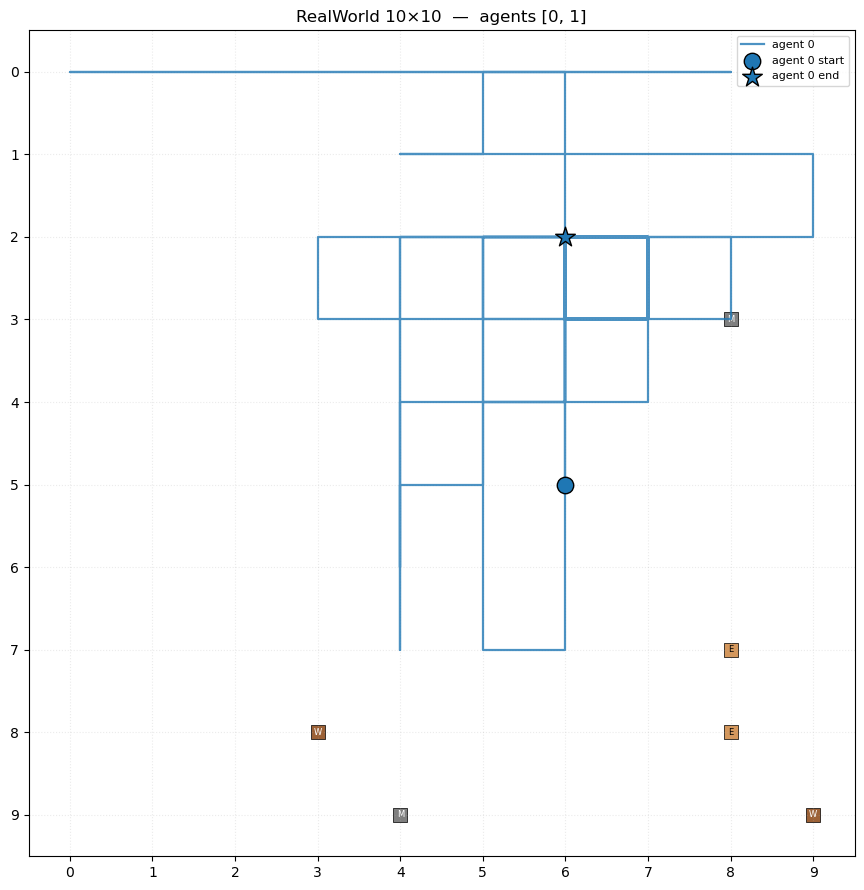

(<Figure size 900x900 with 1 Axes>,
 <Axes: title={'center': 'RealWorld 10×10  —  agents [0, 1]'}>)

In [44]:
# ============================================================
# Cell — 画 RealWorld + agent 路径（一个 cell 全包）
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import json


# ---------- 1) 从 history 抽某个 agent 的 Body 路径 ----------
def extract_agent_path(history, agent_id, size, part="Body"):
    """
    返回 [(step, x, y, action, energy), ...]
    - 位置从 result.detail.new_positions 或 action_plan.result_detail.new_positions 取
    - lot_id -> (x, y): x = lot_id % size, y = lot_id // size
    - action/energy 从该步 action_plan 取（用于上色）
    """
    path = []
    for h in history:
        aid = h.get("agent_id", h.get("agent"))
        if aid is None:
            st = h.get("state") or {}
            aid = st.get("agent_id", st.get("agent"))
        if aid != agent_id:
            continue

        # 位置可能在两个地方
        detail = (h.get("result") or {}).get("detail") or {}
        if not detail:
            detail = (h.get("action_plan") or {}).get("result_detail") or {}
        new_pos = detail.get("new_positions") or {}
        lot_id = new_pos.get(part)
        if lot_id is None:
            continue
        x, y = lot_id % size, lot_id // size

        ap = h.get("action_plan") or {}
        action = ap.get("action")
        ev = ap.get("eval") or {}
        energy = h.get("energy")
        if energy is None:
            pr = (h.get("state") or {}).get("proprio") or {}
            energy = pr.get("energy")

        path.append((h.get("step"), x, y, action, energy))
    return path

w = rw_smoke.world
print("world.size:", w.size)
print("world.groves:", w.groves)
print("world.lots type:", type(w.lots), "len:", len(w.lots) if hasattr(w.lots, '__len__') else '?')

# lots 的结构
if isinstance(w.lots, dict):
    print("lots 前 5:", list(w.lots.items())[:5])
elif isinstance(w.lots, (list, tuple)):
    print("lots 前 5:", w.lots[:5])
    
# 单个 lot 长什么样
if isinstance(w.lots, dict):
    k = next(iter(w.lots))
    print(f"lot[{k}] =", w.lots[k])
elif isinstance(w.lots, (list, tuple)) and w.lots:
    print("lot[0] =", w.lots[0])

# get_lot_by_xy 试一下
print("get_lot_by_xy(0,0):", w.get_lot_by_xy(0, 0))
print("get_lot_by_xy(3,5):", w.get_lot_by_xy(3, 5))


# ---------- 2) 探测 world 的网格/grove 结构 ----------
def _probe_world(rw):
    # ---- size ----
    size = getattr(rw, "size", None)
    if size is None:
        w = getattr(rw, "world", None)
        if w is not None:
            size = getattr(w, "size", None)
    if size is None:
        c = getattr(rw, "cfg", None) or getattr(rw, "config", None)
        if c is not None:
            size = getattr(c, "size", None)
    if size is None:
        raise AttributeError("找不到 size: rw.size / rw.world.size / rw.cfg.size 都没有")

    w = getattr(rw, "world", None)

    # ---- groves ----
    groves = []
    src = getattr(w, "groves", None) if w is not None else None
    if src is None:
        src = getattr(rw, "groves", None)
    if src:
        for g in src:
            if isinstance(g, dict):
                tl = g.get("top_left")
                if tl is None:
                    continue
                tx, ty = tl
                gw = gh = g.get("size", 3)
            else:
                # 可能是对象：g.top_left / g.center / g.size
                tl = getattr(g, "top_left", None)
                if tl is None:
                    continue
                tx, ty = tl
                gw = gh = getattr(g, "size", 3)
            groves.append((tx, ty, gw, gh))

    # ---- elements：从 rw.world.lots 拿 ----
    elements = None
    lots = getattr(w, "lots", None) if w is not None else None
    if lots is not None:
        elements = []
        try:
            if isinstance(lots, dict):
                for k, lot in lots.items():
                    # 取元素名
                    name = None
                    if isinstance(lot, dict):
                        name = lot.get("element") or lot.get("name") or lot.get("type")
                    else:
                        name = getattr(lot, "element", None) or getattr(lot, "name", None) or getattr(lot, "type", None)
                    if name is None:
                        continue
                    # 坐标
                    if isinstance(k, tuple) and len(k) == 2:
                        x, y = k
                    else:
                        # 尝试多种 lot_id -> (x,y) 换算
                        x, y = k % size, k // size
                    elements.append((x, y, str(name)))
            elif isinstance(lots, (list, tuple)):
                # 假设 list 顺序按 row-major：lots[y*size + x]
                for idx, lot in enumerate(lots):
                    name = None
                    if isinstance(lot, dict):
                        name = lot.get("element") or lot.get("name") or lot.get("type")
                    else:
                        name = getattr(lot, "element", None) or getattr(lot, "name", None) or getattr(lot, "type", None)
                    if name is None:
                        continue
                    x, y = idx % size, idx // size
                    elements.append((x, y, str(name)))
        except Exception as e:
            print(f"探测 lots 失败: {e}")
            elements = None

    return {"size": size, "groves": groves, "elements": elements}

# ---------- 3) 画世界（grove + 元素） ----------
def draw_world(ax, rw, size, show_elements=True):
    info = _probe_world(rw)
    # grove
    for (tx, ty, w, h) in info["groves"]:
        ax.add_patch(patches.Rectangle((tx - 0.5, ty - 0.5), w, h,
                                       facecolor="lightgreen", alpha=0.35,
                                       edgecolor="green", linewidth=1.2, zorder=0))
    # elements
    if show_elements and info["elements"]:
        colors = {"Wood": "saddlebrown", "Water": "deepskyblue",
                  "Earth": "peru", "Metal": "dimgray", "Air": "lightgray"}
        for (x, y, name) in info["elements"]:
            c = colors.get(name, "black")
            ax.scatter(x, y, s=110, c=c, marker="s", edgecolors="black",
                       linewidths=0.6, alpha=0.85, zorder=1)
            ax.text(x, y, name[:1], fontsize=6, ha="center", va="center",
                    color="white" if name in ("Wood", "Metal") else "black", zorder=2)
    ax.set_xlim(-0.5, size - 0.5)
    ax.set_ylim(-0.5, size - 0.5)
    ax.set_xticks(range(size))
    ax.set_yticks(range(size))
    ax.set_aspect("equal")
    ax.grid(True, linestyle=":", alpha=0.25)
    ax.invert_yaxis()


# ---------- 4) 画单 agent 路径 ----------
def draw_path(ax, path, label, color="blue", color_by_action=False):
    if not path:
        return
    xs = [p[1] for p in path]
    ys = [p[2] for p in path]

    if color_by_action:
        action_colors = {"move": "#1f77b4", "attack": "#d62728", "eat": "#2ca02c"}
        for i in range(len(path) - 1):
            _, x0, y0, act0, _ = path[i]
            _, x1, y1, _, _ = path[i + 1]
            c = action_colors.get(act0, "black")
            ax.plot([x0, x1], [y0, y1], "-", color=c, linewidth=2.0,
                    alpha=0.85, zorder=3)
    else:
        ax.plot(xs, ys, "-", color=color, linewidth=1.6, alpha=0.8,
                zorder=3, label=label)

    # 起点/终点
    ax.scatter(xs[0], ys[0], s=140, c=color, marker="o",
               edgecolors="black", linewidths=1.0, zorder=5,
               label=f"{label} start")
    ax.scatter(xs[-1], ys[-1], s=220, c=color, marker="*",
               edgecolors="black", linewidths=1.0, zorder=5,
               label=f"{label} end")


# ---------- 5) 总入口：世界 + 多 agent 路径 ----------
def plot_world_with_paths(rw, history, agent_ids=(0, 1),
                          color_by_action=False, show_elements=True,
                          figsize=(9, 9)):
    info = _probe_world(rw) 
    size = info["size"]
    fig, ax = plt.subplots(figsize=figsize)

    draw_world(ax, rw, size, show_elements=show_elements)

    palette = ["#1f77b4", "#d62728", "#9467bd", "#ff7f0e"]
    for i, aid in enumerate(agent_ids):
        path = extract_agent_path(history, aid, size)
        draw_path(ax, path,
                  label=f"agent {aid}",
                  color=palette[i % len(palette)],
                  color_by_action=color_by_action)

    ax.set_title(
        f"RealWorld {size}×{size}  —  agents {list(agent_ids)}"
        + ("  (color by action)" if color_by_action else "")
    )
    # 图例去重
    handles, labels = ax.get_legend_handles_labels()
    seen, h2, l2 = set(), [], []
    for h, l in zip(handles, labels):
        if l in seen:
            continue
        seen.add(l); h2.append(h); l2.append(l)
    ax.legend(h2, l2, loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()
    return fig, ax


# ---------- 6) 直接调用 ----------
plot_world_with_paths(rw_smoke, rw_smoke_history,
                      agent_ids=(0, 1), color_by_action=False)

# 想看"每步在做什么"（蓝=move, 红=attack, 绿=eat）：
# plot_world_with_paths(rw_smoke, rw_smoke_history,
#                       agent_ids=(0, 1), color_by_action=True)

# 想分开两个 agent 各一张图：
# plot_world_with_paths(rw_smoke, rw_smoke_history, agent_ids=(0,), color_by_action=True)
# plot_world_with_paths(rw_smoke, rw_smoke_history, agent_ids=(1,), color_by_action=True)

Excel Ouput 

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import Counter, defaultdict

# ------------------------------------------------------------------
# 1) 统一从 history 抽 (x, y)
# ------------------------------------------------------------------
def _xy(h, part="Body"):
    # 优先 body_after（Lot 对象或 dict）
    for key in ("body_after", "body_before"):
        ba = h.get(key)
        if ba is None:
            continue
        if hasattr(ba, "x") and hasattr(ba, "y"):
            return ba.x, ba.y
        if isinstance(ba, dict) and "x" in ba and "y" in ba:
            return ba["x"], ba["y"]
    # 退化：从 result.detail.new_positions 取
    detail = (h.get("result") or {}).get("detail") or {}
    new_pos = detail.get("new_positions") or {}
    lot_id = new_pos.get(part)
    if lot_id is not None:
        size = 10  # 当前 RealWorld size
        return lot_id % size, lot_id // size
    return None, None


def flatten_rw_history(history):
    rows = []
    for h in history:
        ap = h.get("action_plan") or {}
        bt = h.get("bayes_trace") or {}
        chosen = bt.get("chosen") or {}
        detail = (h.get("result") or {}).get("detail") or {}
        needs = h.get("needs") or {}

        x, y = _xy(h)

        # chosen 的 dist / 象限
        chosen_obj = chosen.get("object") if isinstance(chosen, dict) else ap.get("target_element")
        chosen_dist = chosen.get("current_dist") if isinstance(chosen, dict) else None
        chosen_quad = "unknown"
        for c in bt.get("candidates", []):
            if c.get("object") == chosen_obj:
                chosen_quad = c.get("quadrant", "unknown")
                break

        rows.append({
            "step":               h.get("step"),
            "agent_id":           h.get("agent_id"),
            "alive":              h.get("alive"),
            "x":                  x, "y": y,
            "energy":             h.get("energy"),
            "hungry":             needs.get("hungry"),
            "health":             needs.get("health"),
            "energy_ratio":       needs.get("energy_ratio"),
            "action":             ap.get("action"),
            "source":             ap.get("source"),
            "route":              h.get("route"),
            "target_element":     ap.get("target_element"),
            "move_to":            ap.get("move_to") or (chosen.get("move_to") if isinstance(chosen, dict) else None),
            "chosen_obj":         chosen_obj,
            "chosen_dist":        chosen_dist,
            "chosen_quadrant":    chosen_quad,
            "n_candidates":       len(bt.get("candidates", [])),
            "n_rejected":         len(bt.get("rejected", [])),
            "n_info_objects":     len((ap.get("info_flow") or {}).get("objects", [])),
            "result_success":     (h.get("result") or {}).get("success"),
            "result_eaten":       detail.get("eaten"),
            "result_energy_gain": detail.get("energy_gained"),
            "damage_taken":       detail.get("damage_taken"),
            "fail_reason":        detail.get("reason"),
            "actual_need_resolved": h.get("actual_need_resolved"),
            "forbidden":          h.get("forbidden_triggered"),
        })
    return pd.DataFrame(rows)


df_rw = flatten_rw_history(rw_smoke_history)
print(f"df_rw shape: {df_rw.shape}")
print(df_rw.head(8).to_string())

df_rw shape: (490, 27)
   step  agent_id  alive  x  y  energy hungry health  energy_ratio  action     source                route target_element move_to chosen_obj  chosen_dist chosen_quadrant  n_candidates  n_rejected  n_info_objects  result_success result_eaten  result_energy_gain  damage_taken            fail_reason  actual_need_resolved  forbidden
0     1         0   True  6  5       8  False  False           0.8    move  info_flow     info_flow_driven          Earth    hand      Earth          6.0         unknown             1           2              26            True          NaN                 NaN           NaN                    NaN                 False      False
1     2         0   True  6  4       8  False  False           0.8    move  info_flow     info_flow_driven          Earth    hand      Earth          5.0         unknown             1           2              26            True          NaN                 NaN           NaN                    NaN                 F

S1 — 决策源分布 (source)
            source  count   pct
         info_flow    484 98.78
random_exploration      5  1.02
passive_starvation      1  0.20

动作 × source 交叉表：
source              info_flow  passive_starvation  random_exploration  All
action                                                                    
attack                    230                   0                   0  230
drop                        0                   0                   1    1
eat                        50                   0                   2   52
move                      204                   0                   0  204
observe                     0                   0                   2    2
passive_starvation          0                   1                   0    1
All                       484                   1                   5  490


C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3935102662.py:34: UserWarning: Glyph 21344 (\N{CJK UNIFIED IDEOGRAPH-5360}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3935102662.py:34: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3935102662.py:34: UserWarning: Glyph 20915 (\N{CJK UNIFIED IDEOGRAPH-51B3}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3935102662.py:34: UserWarning: Glyph 31574 (\N{CJK UNIFIED IDEOGRAPH-7B56}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3935102662.py:34: UserWarning: Glyph 28304 (\N{CJK UNIFIED IDEOGRAPH-6E90}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3935102662.py:34: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) miss

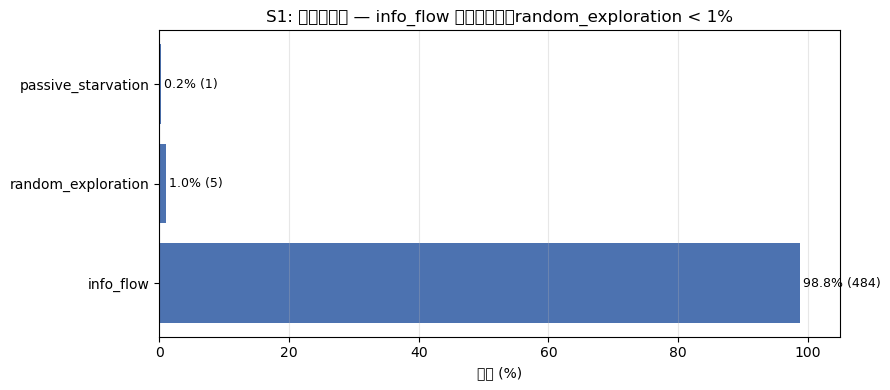

In [47]:
# ------------------------------------------------------------------
# S1: source 分布 + 动作 × source 交叉表
# ------------------------------------------------------------------
total = len(df_rw)

src_counts = df_rw["source"].value_counts()
src_pct    = (src_counts / total * 100).round(2)

src_table = pd.DataFrame({
    "source": src_counts.index,
    "count":  src_counts.values,
    "pct":    src_pct.values,
})
print("=" * 60)
print("S1 — 决策源分布 (source)")
print("=" * 60)
print(src_table.to_string(index=False))

# 动作 × source 交叉表
cross = pd.crosstab(df_rw["action"], df_rw["source"], margins=True)
print("\n动作 × source 交叉表：")
print(cross.to_string())

# 画柱状图
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(src_table["source"], src_table["pct"], color="#4C72B0")
for b, pct, cnt in zip(bars, src_table["pct"], src_table["count"]):
    ax.text(b.get_width() + 0.5, b.get_y() + b.get_height()/2,
            f"{pct:.1f}% ({cnt})", va="center", fontsize=9)
ax.set_xlim(0, 105)
ax.set_xlabel("占比 (%)")
ax.set_title("S1: 决策源分布 — info_flow 占绝对多数，random_exploration < 1%")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

S2 — Wood 上的 attack→(move)→eat 组合序列：33 次
  attack@31 (E=9) → move[32] → eat@33 (E=17) gap=2
  attack@48 (E=15) → move[49] → eat@50 (E=23) gap=2
  attack@64 (E=20) → move[65] → eat@66 (E=29) gap=2
  attack@78 (E=34) → move[79] → eat@80 (E=41) gap=2
  attack@84 (E=39) → move[85] → eat@86 (E=48) gap=2
  attack@92 (E=48) → move[93] → eat@94 (E=57) gap=2
  attack@110 (E=52) → move[111] → eat@112 (E=61) gap=2
  attack@124 (E=50) → move[125] → eat@126 (E=59) gap=2
  attack@143 (E=54) → move[144] → eat@145 (E=62) gap=2
  attack@152 (E=58) → move[153] → eat@154 (E=67) gap=2
  attack@161 (E=63) → move[162] → eat@163 (E=72) gap=2
  attack@175 (E=61) → move[176] → eat@177 (E=69) gap=2
  attack@189 (E=58) → move[190] → eat@191 (E=66) gap=2
  attack@203 (E=55) → move[204] → eat@205 (E=64) gap=2
  attack@217 (E=53) → move[218] → eat@219 (E=61) gap=2


C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1276643413.py:69: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1276643413.py:69: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1276643413.py:69: UserWarning: Glyph 32452 (\N{CJK UNIFIED IDEOGRAPH-7EC4}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1276643413.py:69: UserWarning: Glyph 21512 (\N{CJK UNIFIED IDEOGRAPH-5408}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1276643413.py:69: UserWarning: Glyph 24207 (\N{CJK UNIFIED IDEOGRAPH-5E8F}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\1276643413.py:69: UserWarning: Glyph 21015 (\N{CJK UNIFIED IDEOGRAPH-5217}) miss

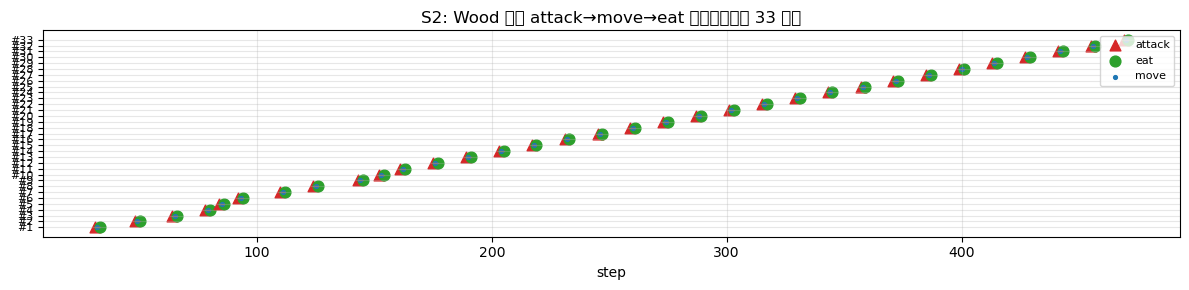

In [48]:
# ------------------------------------------------------------------
# S2: 提取所有"组合序列"事件
#   组合定义：同一 target 上连续出现 attack 之后又出现 eat
# ------------------------------------------------------------------
def extract_combo_sequences(df, target="Wood"):
    """
    扫 df，找 target 上 attack 成功 → (可选 move) → eat 成功的序列。
    返回 list of dict: {attack_step, eat_step, move_steps, gap}
    """
    combos = []
    # 只看 info_flow / plan_execution 驱动的动作
    sub = df[df["source"].isin(["info_flow", "plan_execution"])].sort_values("step")

    pending_attack = None
    for _, r in sub.iterrows():
        act = r["action"]
        obj = r["chosen_obj"]

        if act == "attack" and r["result_success"] and obj == target:
            pending_attack = {
                "attack_step": r["step"],
                "attack_energy": r["energy"],
                "move_steps": [],
            }

        elif act == "move" and pending_attack is not None and obj == target:
            pending_attack["move_steps"].append(r["step"])

        elif act == "eat" and r["result_success"] and r["result_eaten"] == target:
            if pending_attack is not None:
                combos.append({
                    "target": target,
                    "attack_step": pending_attack["attack_step"],
                    "attack_energy": pending_attack["attack_energy"],
                    "move_steps": pending_attack["move_steps"],
                    "eat_step": r["step"],
                    "eat_energy": r["energy"],
                    "gap": r["step"] - pending_attack["attack_step"],
                })
                pending_attack = None

    return combos


combo_wood = extract_combo_sequences(df_rw, "Wood")
print("=" * 60)
print(f"S2 — Wood 上的 attack→(move)→eat 组合序列：{len(combo_wood)} 次")
print("=" * 60)
for c in combo_wood[:15]:
    print(f"  attack@{c['attack_step']} (E={c['attack_energy']}) "
          f"→ move{c['move_steps']} → eat@{c['eat_step']} (E={c['eat_energy']}) "
          f"gap={c['gap']}")

# 画时间线
if combo_wood:
    fig, ax = plt.subplots(figsize=(12, 3))
    for i, c in enumerate(combo_wood):
        ax.plot([c["attack_step"], c["eat_step"]], [i, i], "-", color="gray", linewidth=1)
        ax.scatter(c["attack_step"], i, c="#d62728", marker="^", s=60, label="attack" if i == 0 else "")
        ax.scatter(c["eat_step"], i, c="#2ca02c", marker="o", s=60, label="eat" if i == 0 else "")
        for ms in c["move_steps"]:
            ax.scatter(ms, i, c="#1f77b4", marker=".", s=30, label="move" if i == 0 and ms == c["move_steps"][0] else "")
    ax.set_yticks(range(len(combo_wood)))
    ax.set_yticklabels([f"#{i+1}" for i in range(len(combo_wood))], fontsize=8)
    ax.set_xlabel("step")
    ax.set_title(f"S2: Wood 上的 attack→move→eat 组合序列（共 {len(combo_wood)} 次）")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [50]:
# ============================================================
# Cell A: Stage 7.5 切片 + 单步全透明打印
# 依赖：nursery_history（已在前面 cell 生成）
# ============================================================

STAGE75_START_STEP = 381
STAGE75_END_STEP = 690


def get_stage75_history(history, start=None, end=None):
    """按 step 范围切 Stage 7.5。默认用全局配置。"""
    start = start if start is not None else STAGE75_START_STEP
    end = end if end is not None else STAGE75_END_STEP
    return [h for h in history if start <= h.get("step", -1) <= end]


def dump_step_verbose(h, show_candidates=True, show_info_flow=True):
    """
    单步全透明打印。每行有明确标签，方便 grep。
    标签：[chosen] / [info_flow] / [candidates] / [rejected] / [forbidden] / [result]
    """
    step = h.get("step")
    ap = h.get("action_plan", {}) or {}
    bt = h.get("bayes_trace") or {}
    needs = h.get("needs", {}) or {}
    new_needs = h.get("new_needs", {}) or {}
    result = h.get("result", {}) or {}
    detail = result.get("detail", {}) if isinstance(result.get("detail"), dict) else {}
    eval_r = ap.get("eval") or {}
    info_flow = ap.get("info_flow") or {}

    print(f"\n{'='*78}")
    print(f"STEP {step}  |  action={ap.get('action')}  source={ap.get('source')}  route={h.get('route')}")
    print(f"  energy={h.get('energy')}  alive={h.get('alive')}  "
          f"hungry={needs.get('hungry')}  health={needs.get('health')}  "
          f"energy_ratio={needs.get('energy_ratio')}")
    print(f"  target_element={ap.get('target_element')}  "
          f"move_to={ap.get('move_to') or (bt.get('chosen') or {}).get('move_to')}")
    print(f"  eval: pred_success={eval_r.get('predicted_success')} "
          f"pred_need_resolved={eval_r.get('predicted_need_resolved')} "
          f"reason={(eval_r.get('detail') or {}).get('reason')}")

    chosen = bt.get("chosen")
    if chosen:
        print(f"  [chosen] {chosen}")

    if show_info_flow and info_flow.get("objects"):
        print(f"  [info_flow] {len(info_flow['objects'])} objects:")
        for o in info_flow["objects"]:
            print(f"      - {str(o.get('name')):6s}@({o.get('x')},{o.get('y')}) "
                  f"is_def={o.get('is_defeated')} def_by_mem={o.get('is_defeated_by_memory')} "
                  f"known_def={o.get('known_defence')} "
                  f"steps_avg={o.get('steps_avg')} steps_max={o.get('steps_max')} "
                  f"energy_recs={o.get('energy_gain_records')} "
                  f"changed={o.get('changed_fields')}")

    if show_candidates:
        cands = bt.get("candidates", [])
        rejects = bt.get("rejected", [])
        if cands:
            print(f"  [candidates] {len(cands)} 个:")
            for c in cands:
                print(f"      ✓ obj={str(c.get('object')):6s} dist={c.get('current_dist')} "
                      f"def_by_mem={c.get('is_defeated_by_memory')} "
                      f"known_def={c.get('known_defence')} "
                      f"energy_max={c.get('energy_gain_max')} "
                      f"seq={c.get('action_seq')} move_to={c.get('move_to')} "
                      f"chosen={c.get('is_chosen')}")
        if rejects:
            print(f"  [rejected] {len(rejects)} 个:")
            for r in rejects:
                print(f"      ✗ obj={str(r.get('object')):6s} dist={r.get('current_dist')} "
                      f"steps_max={r.get('steps_max')} death_dist={r.get('death_dist')} "
                      f"reason={r.get('rejected_reason')}")

    if h.get("forbidden_triggered"):
        fb = h.get("forbidden_entry") or {}
        fb_plan = fb.get("action_plan") or {}
        print(f"  [forbidden] HIT! entry.action={fb_plan.get('action')} "
              f"entry.source={fb_plan.get('source')}")

    print(f"  [result] success={result.get('success')} detail={detail}")
    print(f"  [need] actual_need_resolved={h.get('actual_need_resolved')} "
          f"new_hungry={new_needs.get('hungry')} new_health={new_needs.get('health')}")


# ---------- 自检 ----------
stage75 = get_stage75_history(nursery_history)
print(f"Stage 7.5 步数: {len(stage75)}")
if stage75:
    print(f"step 范围: {stage75[0].get('step')} ~ {stage75[-1].get('step')}")
    dump_step_verbose(stage75[0])
else:
    print("⚠️ 没切到 Stage 7.5，检查 STAGE75_START_STEP / STAGE75_END_STEP")

Stage 7.5 步数: 310
step 范围: 381 ~ 690

STEP 381  |  action=eat  source=info_flow  route=info_flow_driven
  energy=4  alive=True  hungry=True  health=True  energy_ratio=0.1
  target_element=Water  move_to=None
  eval: pred_success=True pred_need_resolved=True reason=info_flow_driven
  [chosen] {'stage': 'info_flow_driven', 'object': 'Water', 'action_seq': ['eat'], 'move_to': None, 'current_dist': 0, 'is_defeated_by_memory': False, 'energy_gain_max': 3}
  [info_flow] 3 objects:
      - Metal @(1,1) is_def=False def_by_mem=False known_def=5 steps_avg=None steps_max=None energy_recs=[] changed=[]
      - Metal @(3,3) is_def=False def_by_mem=False known_def=5 steps_avg=None steps_max=None energy_recs=[] changed=[]
      - Water @(1,4) is_def=False def_by_mem=False known_def=0 steps_avg=2.75 steps_max=4 energy_recs=[3, 3, 3, 3, 3, 3, 3, 3] changed=[]
  [candidates] 1 个:
      ✓ obj=Water  dist=0 def_by_mem=False known_def=0 energy_max=3 seq=['eat'] move_to=None chosen=True
  [rejected] 2 个:
 

In [51]:
# ------------------------------------------------------------------
# S3: step 161 的 Bayesian 打分细节
# ------------------------------------------------------------------
def dump_bayes_case(history, step):
    h = next((x for x in history if x.get("step") == step), None)
    if h is None:
        print(f"step {step} not found")
        return
    ap = h.get("action_plan") or {}
    bt = h.get("bayes_trace") or {}
    chosen = bt.get("chosen") or {}

    print("=" * 70)
    print(f"S3 case study — STEP {step}")
    print(f"  action={ap.get('action')}  source={ap.get('source')}  energy={h.get('energy')}")
    print(f"  chosen={chosen.get('object')}")
    print("=" * 70)
    print(f"  {'obj':>6} {'dist':>5} {'E_max':>6} {'def':>4} {'quadrant':>20} {'chosen':>7}")
    print("-" * 70)
    for o in (ap.get("info_flow") or {}).get("objects", []):
        name = o.get("name")
        dist = None
        for c in bt.get("candidates", []):
            if c.get("object") == name:
                dist = c.get("current_dist"); break
        e_max = max(o.get("energy_gain_records") or [0])
        # 从 candidates 找 quadrant
        quad = "?"
        for c in bt.get("candidates", []):
            if c.get("object") == name:
                quad = c.get("quadrant", "?"); break
        mark = "★" if name == chosen.get("object") else ""
        print(f"  {name:>6} {str(dist):>5} {e_max:>6} {str(o.get('known_defence')):>4} {quad:>20} {mark:>7}")

    # 打印 rejected
    if bt.get("rejected"):
        print("\n  rejected:")
        for r in bt["rejected"]:
            print(f"    {r}")


# 同时打印 161 和 114（第一次 Metal 失败）
for s in [114, 161, 165]:
    dump_bayes_case(rw_smoke_history, s)
    print()

S3 case study — STEP 114
  action=attack  source=info_flow  energy=60
  chosen=Metal
     obj  dist  E_max  def             quadrant  chosen
----------------------------------------------------------------------
   Metal     0      0    5                    ?       ★
   Water  None      3    0                    ?        
    Wood  None      9    3                    ?        
   Earth  None      4    2                    ?        
    Wood  None      9    3                    ?        
   Earth  None      4    2                    ?        

S3 case study — STEP 161
  action=attack  source=info_flow  energy=63
  chosen=Wood
     obj  dist  E_max  def             quadrant  chosen
----------------------------------------------------------------------
    Wood     1      9    3                    ?       ★
   Metal  None      0    5                    ?        
   Earth  None      4    2                    ?        

  rejected:
    {'object': 'Metal', 'current_dist': 2, 'steps_max': Non

In [52]:
# ============================================================
# Cell B: 过滤器 + 测量 1（规则命中）+ 测量 2（失败归因）
# 依赖：Cell A 的 stage75
# ============================================================

# ---------- 过滤器 ----------
def filter_decisions(stage75, kind):
    """
    kind: 'attack' | 'eat_live' | 'eat_defeated' | 'move_to_body' | 'move_to_hand'
          | 'def_by_mem_stuck' | 'forbidden' | 'no_target_eat' | 'prey_switch'
    """
    out = []
    prev_obj = None
    for h in stage75:
        ap = h.get("action_plan", {}) or {}
        detail = (h.get("result") or {}).get("detail") or {}
        bt = h.get("bayes_trace") or {}
        chosen = bt.get("chosen") or {}
        obj = chosen.get("object") if isinstance(chosen, dict) else ap.get("target_element")

        if kind == "attack" and ap.get("action") == "attack":
            out.append(h)
        elif kind == "eat_live" and ap.get("action") == "eat" and detail.get("damage_taken", 0) > 0:
            out.append(h)
        elif kind == "eat_defeated" and ap.get("action") == "eat" and detail.get("is_defeated"):
            out.append(h)
        elif kind == "move_to_body" and ap.get("action") == "move" and (ap.get("move_to") or chosen.get("move_to")) == "body":
            out.append(h)
        elif kind == "move_to_hand" and ap.get("action") == "move" and (ap.get("move_to") or chosen.get("move_to")) == "hand":
            out.append(h)
        elif kind == "def_by_mem_stuck":
            is_def = chosen.get("is_defeated_by_memory") if isinstance(chosen, dict) else None
            if is_def and ap.get("action") == "move" and not h.get("actual_need_resolved"):
                out.append(h)
        elif kind == "forbidden" and h.get("forbidden_triggered"):
            out.append(h)
        elif kind == "no_target_eat" and ap.get("action") == "eat" and detail.get("reason") in ("no_food_here", "target_not_here"):
            out.append(h)
        elif kind == "prey_switch":
            if prev_obj is not None and obj is not None and obj != prev_obj:
                out.append(h)
        prev_obj = obj if obj is not None else prev_obj
    return out


def print_decision_summary(hist_list, title):
    print(f"\n{'#'*78}")
    print(f"# {title}  ({len(hist_list)} 步)")
    print(f"{'#'*78}")
    print(f"{'step':>5} | {'action':>8} | {'source':>12} | {'route':>26} | "
          f"{'obj':>6} | {'dist':>4} | {'move_to':>6} | {'known_def':>9} | "
          f"{'def_mem':>7} | {'energy':>6} | {'eat/dmg':>10} | {'fail_reason':>18}")
    print("-" * 165)
    for h in hist_list:
        ap = h.get("action_plan", {}) or {}
        bt = h.get("bayes_trace") or {}
        chosen = bt.get("chosen") or {}
        detail = (h.get("result") or {}).get("detail") or {}
        obj = chosen.get("object") if isinstance(chosen, dict) else ap.get("target_element")
        dist = chosen.get("current_dist") if isinstance(chosen, dict) else None
        move_to = ap.get("move_to") or chosen.get("move_to")
        known_def = None
        for c in bt.get("candidates", []):
            if c.get("object") == obj:
                known_def = c.get("known_defence"); break
        def_mem = chosen.get("is_defeated_by_memory") if isinstance(chosen, dict) else None
        eaten = detail.get("eaten")
        dmg = detail.get("damage_taken")
        eat_dmg = f"{eaten}/{dmg}" if eaten else ("-" if dmg is None else f"-/{dmg}")
        print(f"{h.get('step'):>5} | {str(ap.get('action')):>8} | {str(ap.get('source')):>12} | "
              f"{str(h.get('route')):>26} | {str(obj):>6} | {str(dist):>4} | {str(move_to):>6} | "
              f"{str(known_def):>9} | {str(def_mem):>7} | {str(h.get('energy')):>6} | "
              f"{eat_dmg:>10} | {str(detail.get('reason')):>18}")


# ---------- 测量 1：8 条规则命中 ----------
def classify_rule(row):
    """从 chosen 反推 _decide_action_for_object 走了哪条规则"""
    if row["source"] not in ("info_flow", "plan_execution"):
        return "not_info_flow"
    if row["chosen_obj"] is None:
        return "no_obj"
    kd = row["known_defence"]
    dist = row["chosen_dist"]
    is_def = row["def_mem"]
    seq = row["action_seq"]
    if is_def:
        return "rule1_eat_defeated" if dist == 0 else "rule3_move_to_body_defeated"
    if kd is None or kd == 0:
        return "rule2_eat_live_nodef" if dist == 0 else "rule4_move_to_body_live_nodef"
    return "rule7_attack" if "attack" in str(seq) else "rule8_move_to_hand"


def measure_rule_hits(stage75):
    """测量 1：把 stage75 展平成表，统计 8 条规则命中率"""
    rows = []
    for h in stage75:
        ap = h.get("action_plan", {}) or {}
        bt = h.get("bayes_trace") or {}
        chosen = bt.get("chosen") or {}
        detail = (h.get("result") or {}).get("detail") or {}
        chosen_obj = chosen.get("object") if isinstance(chosen, dict) else None
        kd = None
        dist = chosen.get("current_dist") if isinstance(chosen, dict) else None
        for c in bt.get("candidates", []):
            if c.get("object") == chosen_obj:
                kd = c.get("known_defence"); break
        rows.append({
            "step": h.get("step"),
            "action": ap.get("action"),
            "source": ap.get("source"),
            "chosen_obj": chosen_obj,
            "chosen_dist": dist,
            "known_defence": kd,
            "def_mem": chosen.get("is_defeated_by_memory") if isinstance(chosen, dict) else None,
            "action_seq": str(chosen.get("action_seq") if isinstance(chosen, dict) else ap.get("action_sequence")),
            "actual_action_success": h.get("actual_action_success"),
            "actual_need_resolved": h.get("actual_need_resolved"),
            "forbidden": h.get("forbidden_triggered"),
            "eaten": detail.get("eaten"),
            "damage_taken": detail.get("damage_taken"),
        })
    df = pd.DataFrame(rows)
    df["rule"] = df.apply(classify_rule, axis=1)

    print(f"\n{'='*78}")
    print("测量 1：8 条规则命中分布")
    print(f"{'='*78}")
    vc = df["rule"].value_counts()
    for k, v in vc.items():
        print(f"  {k:32s} {v:>4} 次")

    print(f"\n  --- 规则 × 成功率 ---")
    g = df.groupby("rule").agg(
        n=("step", "size"),
        action_success=("actual_action_success", "mean"),
        need_resolved=("actual_need_resolved", "mean"),
        forbidden=("forbidden", "mean"),
    ).round(3)
    print(g.to_string())
    return df


# ---------- 测量 2：失败归因 ----------
def measure_failure_attribution(stage75, df):
    """
    测量 2：把"该吃到没吃到"分类：
      A1_eat_zero_energy   - 吃的是 Air/Metal（零能量）
      A2_eat_live_damaged  - 生吃活物，被反伤但没 resolve
      B_died_while_moving  - move 后下一步就是 passive_starvation
      C_move_invalid       - move_away_from_target
      D_forbidden          - forbidden 命中
      E_no_target          - eat 时脚下没食物
    """
    death_steps = set()
    for h in stage75:
        if h.get("route") == "passive_starvation":
            death_steps.add(h.get("step"))

    failures = []
    for _, r in df.iterrows():
        step = r["step"]
        # A1 / A2
        if r["action"] == "eat" and r["actual_action_success"] and not r["actual_need_resolved"]:
            if r["eaten"] in ("Air", "Metal"):
                failures.append({"step": step, "type": "A1_eat_zero_energy",
                                 "obj": r["eaten"], "rule": r["rule"], "detail": ""})
            else:
                failures.append({"step": step, "type": "A2_eat_live_damaged",
                                 "obj": r["eaten"], "rule": r["rule"],
                                 "detail": f"dmg={r['damage_taken']}"})
        # B
        if r["action"] == "move" and (step + 1) in death_steps:
            failures.append({"step": step, "type": "B_died_while_moving",
                             "obj": r["chosen_obj"], "rule": r["rule"],
                             "detail": f"dist={r['chosen_dist']}"})
        # C
        if r["action"] == "move":
            h = next((x for x in stage75 if x.get("step") == step), None)
            if h and (h.get("result") or {}).get("detail", {}).get("reason") == "move_away_from_target":
                failures.append({"step": step, "type": "C_move_invalid",
                                 "obj": r["chosen_obj"], "rule": r["rule"], "detail": "move_away"})
        # D
        if r["forbidden"]:
            failures.append({"step": step, "type": "D_forbidden",
                             "obj": r["chosen_obj"], "rule": r["rule"], "detail": ""})
        # E
        if r["action"] == "eat" and not r["actual_action_success"]:
            failures.append({"step": step, "type": "E_no_target",
                             "obj": r["chosen_obj"], "rule": r["rule"], "detail": ""})

    fdf = pd.DataFrame(failures)
    print(f"\n{'='*78}")
    print("测量 2：失败归因分布")
    print(f"{'='*78}")
    if fdf.empty:
        print("  没有失败样本")
        return fdf
    print(fdf["type"].value_counts().to_string())
    print(f"\n  --- 每类前 5 条 ---")
    for t in fdf["type"].unique():
        print(f"\n  [{t}]")
        print(fdf[fdf["type"] == t].head(5).to_string(index=False))
    return fdf


# ---------- 自检：跑测量 1 和 2 ----------
df75 = measure_rule_hits(stage75)
failure_df = measure_failure_attribution(stage75, df75)


测量 1：8 条规则命中分布
  not_info_flow                     175 次
  rule8_move_to_hand                 46 次
  rule7_attack                       35 次
  rule4_move_to_body_live_nodef      20 次
  rule3_move_to_body_defeated        14 次
  rule1_eat_defeated                 14 次
  rule2_eat_live_nodef                6 次

  --- 规则 × 成功率 ---
                                 n  action_success  need_resolved  forbidden
rule                                                                        
not_info_flow                  175           0.543          0.000        0.0
rule1_eat_defeated              14           1.000          0.500        0.0
rule2_eat_live_nodef             6           1.000          0.333        0.0
rule3_move_to_body_defeated     14           1.000          0.000        0.0
rule4_move_to_body_live_nodef   20           1.000          0.000        0.0
rule7_attack                    35           0.400          0.000        0.0
rule8_move_to_hand              46           1.000    

In [53]:
# ============================================================
# Cell C: loop 切分 + 测量 3（每次 loop 的能量轨迹和目标切换）
# 依赖：Cell A 的 stage75，Cell B 的 filter_decisions / print_decision_summary
# ============================================================

def split_stage75_loops(stage75):
    """按 energy 回跳到 <=3 且 step 连续，切分 loop"""
    loops = []
    cur = []
    prev_energy = None
    for h in stage75:
        e = h.get("energy")
        if cur and e is not None and prev_energy is not None and e > prev_energy + 2 and e <= 3:
            loops.append(cur)
            cur = []
        cur.append(h)
        prev_energy = e
    if cur:
        loops.append(cur)
    return loops


def measure_loop_energy_trajectory(stage75):
    """
    测量 3：每次 loop 的：
      - 步数、起始/终止 energy、alive
      - 每步 chosen_obj 序列（看目标切换）
      - 死因
    """
    loops = split_stage75_loops(stage75)
    print(f"\n{'='*78}")
    print(f"测量 3：Stage 7.5 共 {len(loops)} 次 loop")
    print(f"{'='*78}")

    loop_stats = []
    for i, lp in enumerate(loops):
        steps = [h.get("step") for h in lp]
        energies = [h.get("energy") for h in lp]
        objs = []
        for h in lp:
            bt = h.get("bayes_trace") or {}
            chosen = bt.get("chosen") or {}
            o = chosen.get("object") if isinstance(chosen, dict) else None
            if o:
                objs.append(o)

        # 目标切换序列（压缩连续重复）
        compressed = []
        for o in objs:
            if not compressed or compressed[-1] != o:
                compressed.append(o)

        # 死因
        last = lp[-1]
        if last.get("route") == "passive_starvation":
            death = "passive_starvation"
        elif not last.get("alive"):
            death = "dead_other"
        else:
            death = "alive"

        # eat 成功的 object
        eaten_list = []
        for h in lp:
            d = (h.get("result") or {}).get("detail") or {}
            if d.get("eaten"):
                eaten_list.append(d["eaten"])

        loop_stats.append({
            "loop": i + 1,
            "step_start": steps[0],
            "step_end": steps[-1],
            "n_steps": len(lp),
            "energy_start": energies[0],
            "energy_end": energies[-1],
            "min_energy": min(e for e in energies if e is not None),
            "death": death,
            "n_eaten": len(eaten_list),
            "eaten": ",".join(eaten_list),
            "target_sequence": " → ".join(compressed),
        })

    stats_df = pd.DataFrame(loop_stats)
    print(stats_df.to_string(index=False))

    # 汇总：每次 loop 都吃了什么、追了什么、怎么死的
    print(f"\n  --- 关键观察 ---")
    for _, r in stats_df.iterrows():
        print(f"  Loop {r['loop']}: {r['n_steps']}步, E{r['energy_start']}→{r['energy_end']}, "
              f"吃了 {r['n_eaten']} 个 ({r['eaten'] or '-'}), "
              f"目标: {r['target_sequence']}, 结局: {r['death']}")

    return loops, stats_df


# ---------- 自检 ----------
loops, loop_stats_df = measure_loop_energy_trajectory(stage75)

# 展开任意一个 loop 的完整时间线（默认看最后一次失败的 loop）
def dump_loop_timeline(loop_hist, loop_idx=None):
    print(f"\n{'='*90}")
    print(f"LOOP {loop_idx}  完整时间线  ({len(loop_hist)} 步)")
    print(f"{'='*90}")
    for h in loop_hist:
        ap = h.get("action_plan", {}) or {}
        bt = h.get("bayes_trace") or {}
        chosen = bt.get("chosen") or {}
        detail = (h.get("result") or {}).get("detail") or {}
        needs = h.get("needs", {}) or {}
        obj = chosen.get("object") if isinstance(chosen, dict) else ap.get("target_element")
        dist = chosen.get("current_dist") if isinstance(chosen, dict) else None
        move_to = ap.get("move_to") or chosen.get("move_to")
        def_mem = chosen.get("is_defeated_by_memory") if isinstance(chosen, dict) else None
        eaten = detail.get("eaten")
        dmg = detail.get("damage_taken")
        mark = ""
        if eaten: mark += f" EAT={eaten}"
        if dmg: mark += f" DMG={dmg}"
        if h.get("forbidden_triggered"): mark += " FORBIDDEN"
        if detail.get("reason"): mark += f" [{detail.get('reason')}]"
        print(f"  s{h.get('step'):>4} E={str(h.get('energy')):>3} "
              f"hungry={str(needs.get('hungry')):>5} "
              f"{str(ap.get('action')):>8} src={str(ap.get('source')):>12} "
              f"obj={str(obj):>6} dist={str(dist):>4} mv={str(move_to):>4} "
              f"defmem={str(def_mem):>5}{mark}")

# 自动展开最后一次 loop
if loops:
    dump_loop_timeline(loops[-1], loop_idx=len(loops))


测量 3：Stage 7.5 共 3 次 loop
 loop  step_start  step_end  n_steps  energy_start  energy_end  min_energy      death  n_eaten                                                                    eaten                                                                                          target_sequence
    1         381       439       59             4           0           0 dead_other        4                                                    Water,Wood,Wood,Water                                              Water → Wood → Metal → Water → Metal → Wood → Metal → Water
    2         440       473       34             3           0           0 dead_other        3                                                        Earth,Earth,Earth                                                                                                    Earth
    3         474       690      217             3          10           2      alive       13 Water,Earth,Water,Earth,Wood,Water,Earth,Wood,Earth,Wood,Wo

In [ ]:
# # ============================================================
# # Cell D: 测量 4（对象追踪）+ 导出 flat csv
# # 依赖：Cell A 的 stage75
# # ============================================================

# def measure_object_journey(stage75, obj_name="Wood"):
#     """
#     测量 4：追踪某个 object 从出现到被吃/放弃的完整旅程。
#     """
#     print(f"\n{'='*78}")
#     print(f"测量 4：追踪 {obj_name}")
#     print(f"{'='*78}")

#     appear, chosen_steps, attack_steps, eat_steps = [], [], [], []
#     for h in stage75:
#         info_flow = (h.get("action_plan") or {}).get("info_flow") or {}
#         bt = h.get("bayes_trace") or {}
#         chosen = bt.get("chosen") or {}
#         ap = h.get("action_plan") or {}
#         detail = (h.get("result") or {}).get("detail") or {}

#         for o in info_flow.get("objects", []):
#             if o.get("name") == obj_name:
#                 appear.append((h.get("step"), o.get("x"), o.get("y"),
#                                o.get("known_defence"), o.get("steps_avg"),
#                                o.get("energy_gain_records")))
#                 break

#         if isinstance(chosen, dict) and chosen.get("object") == obj_name:
#             chosen_steps.append(h)
#         if ap.get("action") == "attack" and detail.get("target") == obj_name:
#             attack_steps.append(h)
#         if ap.get("action") == "eat" and detail.get("eaten") == obj_name:
#             eat_steps.append(h)

#     print(f"\n  [出现] {len(appear)} 次，前 10 次：")
#     for a in appear[:10]:
#         print(f"    step={a[0]} @({a[1]},{a[2]}) known_def={a[3]} steps_avg={a[4]} energy_recs={a[5]}")

#     print(f"\n  [被 chosen] {len(chosen_steps)} 次：")
#     for h in chosen_steps:
#         ap = h.get("action_plan") or {}
#         bt = h.get("bayes_trace") or {}
#         chosen = bt.get("chosen") or {}
#         print(f"    step={h.get('step')} action={ap.get('action')} "
#               f"dist={chosen.get('current_dist')} move_to={chosen.get('move_to')} "
#               f"energy={h.get('energy')} def_mem={chosen.get('is_defeated_by_memory')} "
#               f"energy_max={chosen.get('energy_gain_max')}")

#     print(f"\n  [attack] {len(attack_steps)} 次：")
#     for h in attack_steps:
#         detail = (h.get("result") or {}).get("detail") or {}
#         print(f"    step={h.get('step')} attack_value={detail.get('attack_value')} "
#               f"target_def={detail.get('target_defence')} energy={h.get('energy')}")

#     print(f"\n  [eat] {len(eat_steps)} 次：")
#     for h in eat_steps:
#         detail = (h.get("result") or {}).get("detail") or {}
#         print(f"    step={h.get('step')} energy_gained={detail.get('energy_gained')} "
#               f"energy_before={h.get('energy')}")

#     return {"appear": appear, "chosen": chosen_steps, "attack": attack_steps, "eat": eat_steps}


# def export_stage75_flat(stage75, filename="stage75_decisions.csv"):
#     """导出 Stage 7.5 全字段 flat 表，方便 grep / Excel 筛"""
#     rows = []
#     for h in stage75:
#         ap = h.get("action_plan", {}) or {}
#         bt = h.get("bayes_trace") or {}
#         chosen = bt.get("chosen") or {}
#         detail = (h.get("result") or {}).get("detail") or {}
#         needs = h.get("needs", {}) or {}
#         info_flow = ap.get("info_flow") or {}

#         row = {
#             "step": h.get("step"),
#             "energy": h.get("energy"),
#             "alive": h.get("alive"),
#             "hungry": needs.get("hungry"),
#             "health": needs.get("health"),
#             "energy_ratio": needs.get("energy_ratio"),
#             "action": ap.get("action"),
#             "source": ap.get("source"),
#             "route": h.get("route"),
#             "target": ap.get("target_element"),
#             "move_to": ap.get("move_to") or chosen.get("move_to"),
#             "chosen_obj": chosen.get("object") if isinstance(chosen, dict) else None,
#             "chosen_dist": chosen.get("current_dist") if isinstance(chosen, dict) else None,
#             "chosen_def_mem": chosen.get("is_defeated_by_memory") if isinstance(chosen, dict) else None,
#             "chosen_energy_max": chosen.get("energy_gain_max") if isinstance(chosen, dict) else None,
#             "result_success": (h.get("result") or {}).get("success"),
#             "eaten": detail.get("eaten"),
#             "damage_taken": detail.get("damage_taken"),
#             "target_defence": detail.get("target_defence"),
#             "fail_reason": detail.get("reason"),
#             "actual_need_resolved": h.get("actual_need_resolved"),
#             "forbidden": h.get("forbidden_triggered"),
#             "n_candidates": len(bt.get("candidates", [])),
#             "n_rejected": len(bt.get("rejected", [])),
#             "n_info_objects": len(info_flow.get("objects", [])),
#         }
#         for o in info_flow.get("objects", []):
#             name = o.get("name")
#             prefix = f"obj_{name}"
#             row[f"{prefix}_x"] = o.get("x")
#             row[f"{prefix}_y"] = o.get("y")
#             row[f"{prefix}_is_def"] = o.get("is_defeated")
#             row[f"{prefix}_known_def"] = o.get("known_defence")
#             row[f"{prefix}_steps_avg"] = o.get("steps_avg")
#             row[f"{prefix}_energy_max"] = max(o.get("energy_gain_records") or [0]) if o.get("energy_gain_records") else 0
#         rows.append(row)
#     df = pd.DataFrame(rows)
#     df.to_csv(filename, index=False, encoding="utf-8-sig")
#     print(f"\n已导出 {len(df)} 行到 {filename}")
#     return df


# # ---------- 自检：跑测量 4 ----------
# journey = {}
# for e in ["Wood", "Earth", "Water"]:
#     journey[e] = measure_object_journey(stage75, e)

# df75_flat = export_stage75_flat(stage75)
# print(f"\n导出后前 10 行：")
# print(df75_flat.head(10).to_string())

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

def compute_quadrant(h):
    """goodness = energy_gain_max > 0；certainty = known_attack >= known_defence。"""
    bt = h.get("bayes_trace") or {}
    cands = bt.get("candidates") or []
    if not cands:
        return "unknown"
    # 优先取 is_chosen=True，否则取第一个
    chosen = next((c for c in cands if c.get("is_chosen")), cands[0])

    eg = chosen.get("energy_gain_max") or 0
    ka = chosen.get("known_attack")
    kd = chosen.get("known_defence")

    good = eg > 0
    if ka is not None and kd is not None:
        certain = ka >= kd
    else:
        certain = False   # 不知道能否破防 → uncertain

    if good and certain:     return "Q4_good_certain"
    if good and not certain: return "Q1_good_uncertain"
    if not good and certain: return "Q3_bad_certain"
    return "Q2_bad_uncertain"

# 重算 chosen_quadrant
df_rw["chosen_quadrant"] = [compute_quadrant(h) for h in rw_smoke_history]
print("chosen_quadrant 分布:", df_rw["chosen_quadrant"].value_counts(dropna=False).to_dict())

chosen_quadrant 分布: {'Q4_good_certain': 279, 'Q3_bad_certain': 205, 'unknown': 6}


S4 — 四象限命中分布（仅 info_flow / plan_execution 驱动）
       quadrant   n  pct  action_success_rate  need_resolved_rate  forbidden_rate
 Q3_bad_certain 205 42.4                0.068               0.000             0.0
Q4_good_certain 279 57.6                1.000               0.011             0.0


C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\2011011423.py:56: UserWarning: Glyph 22235 (\N{CJK UNIFIED IDEOGRAPH-56DB}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\2011011423.py:56: UserWarning: Glyph 35937 (\N{CJK UNIFIED IDEOGRAPH-8C61}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\2011011423.py:56: UserWarning: Glyph 38480 (\N{CJK UNIFIED IDEOGRAPH-9650}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\2011011423.py:56: UserWarning: Glyph 21629 (\N{CJK UNIFIED IDEOGRAPH-547D}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\2011011423.py:56: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\2011011423.py:56: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) miss

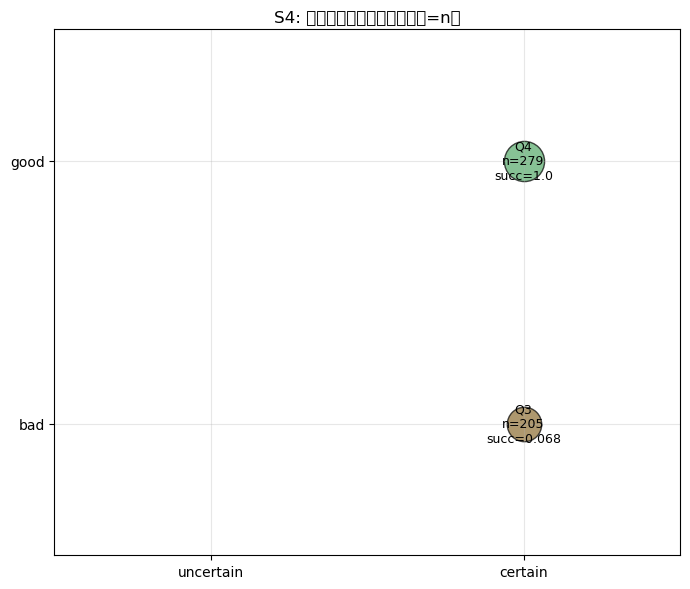

In [58]:
# ------------------------------------------------------------------
# S4: 四象限命中分布 + 每个象限的动作成功率
# ------------------------------------------------------------------
quads = ["Q1_good_uncertain", "Q2_bad_uncertain",
         "Q3_bad_certain", "Q4_good_certain"]

# 只统计 info_flow / plan_execution 驱动的步
sub = df_rw[df_rw["source"].isin(["info_flow", "plan_execution"])].copy()

quad_stats = []
for q in quads:
    s = sub[sub["chosen_quadrant"] == q]
    if s.empty:
        continue
    quad_stats.append({
        "quadrant": q,
        "n": len(s),
        "pct": round(len(s) / len(sub) * 100, 1),
        "action_success_rate": round(s["result_success"].mean(), 3),
        "need_resolved_rate":  round(s["actual_need_resolved"].mean(), 3),
        "forbidden_rate":      round(s["forbidden"].mean(), 3),
    })

qdf = pd.DataFrame(quad_stats)
print("=" * 70)
print("S4 — 四象限命中分布（仅 info_flow / plan_execution 驱动）")
print("=" * 70)
print(qdf.to_string(index=False))

# 画 2x2 象限图：x=certainty, y=goodness，气泡大小=n
fig, ax = plt.subplots(figsize=(7, 6))
pos = {
    "Q4_good_certain":     (1, 1),
    "Q1_good_uncertain":   (0, 1),
    "Q3_bad_certain":      (1, 0),
    "Q2_bad_uncertain":    (0, 0),
}
colors = {"Q4_good_certain": "#55A868", "Q1_good_uncertain": "#4C72B0",
          "Q3_bad_certain": "#8C6D31", "Q2_bad_uncertain": "#C44E52"}

for q in quads:
    s = qdf[qdf["quadrant"] == q]
    if s.empty:
        continue
    n = s.iloc[0]["n"]
    x, y = pos[q]
    ax.scatter(x, y, s=max(100, n * 3), c=colors[q], alpha=0.7, edgecolors="black")
    ax.text(x, y, f"{q.split('_')[0]}\nn={n}\nsucc={s.iloc[0]['action_success_rate']}",
            ha="center", va="center", fontsize=9)

ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_xticks([0, 1]); ax.set_xticklabels(["uncertain", "certain"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["bad", "good"])
ax.set_title("S4: 四象限命中分布（气泡大小=n）")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

S5 — Metal 被 Bayesian 层拒掉的次数：305
  step=   1  dist=2  death_dist=0  reason=dist 2 > death_dist 0
  step=   1  dist=6  death_dist=0  reason=dist 6 > death_dist 0
  step=   2  dist=3  death_dist=0  reason=dist 3 > death_dist 0
  step=   2  dist=5  death_dist=0  reason=dist 5 > death_dist 0
  step=   3  dist=2  death_dist=0  reason=dist 2 > death_dist 0
  step=   3  dist=6  death_dist=0  reason=dist 6 > death_dist 0
  step=   4  dist=1  death_dist=0  reason=dist 1 > death_dist 0
  step=   5  dist=2  death_dist=0  reason=dist 2 > death_dist 0
  step=   6  dist=3  death_dist=0  reason=dist 3 > death_dist 0
  step=   7  dist=4  death_dist=0  reason=dist 4 > death_dist 0
  step=   8  dist=4  death_dist=0  reason=dist 4 > death_dist 0
  step=   9  dist=5  death_dist=0  reason=dist 5 > death_dist 0
  step=  10  dist=6  death_dist=0  reason=dist 6 > death_dist 0
  step=  11  dist=7  death_dist=0  reason=dist 7 > death_dist 0
  step=  19  dist=7  death_dist=0  reason=dist 7 > death_dist 0
  step=

C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3021651950.py:42: UserWarning: Glyph 34987 (\N{CJK UNIFIED IDEOGRAPH-88AB}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3021651950.py:42: UserWarning: Glyph 25298 (\N{CJK UNIFIED IDEOGRAPH-62D2}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3021651950.py:42: UserWarning: Glyph 25481 (\N{CJK UNIFIED IDEOGRAPH-6389}) missing from current font.
  plt.tight_layout()
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 34987 (\N{CJK UNIFIED IDEOGRAPH-88AB}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 25298 (\N{CJK UNIFIED IDEOGRAPH-62D2}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\lgzaw\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152:

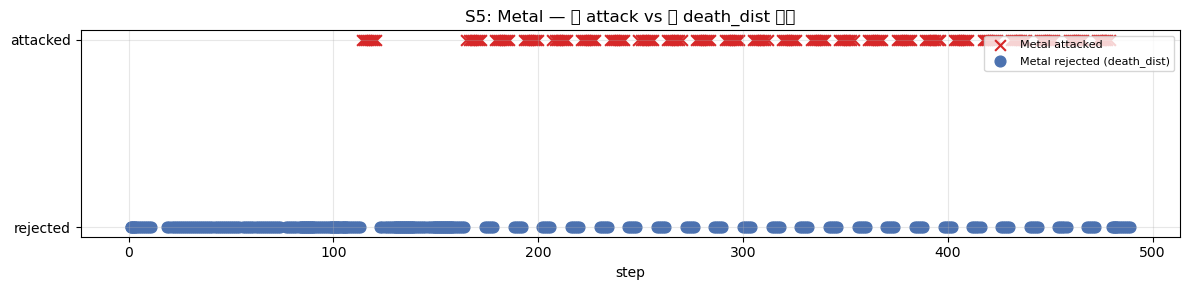

In [59]:
# ------------------------------------------------------------------
# S5: forbidden death_dist 触发次数 + Metal 攻击的时间线
# ------------------------------------------------------------------
metal_attacks = df_rw[df_rw["chosen_obj"] == "Metal"]
metal_rejected_steps = []
for h in rw_smoke_history:
    bt = h.get("bayes_trace") or {}
    for r in bt.get("rejected", []):
        if r.get("object") == "Metal":
            metal_rejected_steps.append({
                "step": h.get("step"),
                "reason": r.get("rejected_reason"),
                "death_dist": r.get("death_dist"),
                "current_dist": r.get("current_dist"),
            })

print("=" * 70)
print(f"S5 — Metal 被 Bayesian 层拒掉的次数：{len(metal_rejected_steps)}")
print("=" * 70)
for r in metal_rejected_steps[:20]:
    print(f"  step={r['step']:>4}  dist={r['current_dist']}  "
          f"death_dist={r['death_dist']}  reason={r['reason']}")

print(f"\nMetal 实际被 attack 的次数：{len(metal_attacks)}")
if not metal_attacks.empty:
    print(metal_attacks[["step", "energy", "result_success"]].head(20).to_string(index=False))

# 画 Metal 攻击 vs 被拒的时间线
fig, ax = plt.subplots(figsize=(12, 3))
if not metal_attacks.empty:
    ax.scatter(metal_attacks["step"], [1]*len(metal_attacks),
               c="#d62728", marker="x", s=60, label="Metal attacked")
if metal_rejected_steps:
    ax.scatter([r["step"] for r in metal_rejected_steps],
               [0]*len(metal_rejected_steps),
               c="#4C72B0", marker="o", s=60, label="Metal rejected (death_dist)")
ax.set_yticks([0, 1]); ax.set_yticklabels(["rejected", "attacked"])
ax.set_xlabel("step")
ax.set_title("S5: Metal — 被 attack vs 被 death_dist 拒掉")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
# ------------------------------------------------------------------
# 汇总表：五个论点各一行，数字直接引用
# ------------------------------------------------------------------
def _pct(n, d):
    return round(n / d * 100, 2) if d else 0.0

summary_rows = [
    {
        "claim": "S1 info_flow 占决策源比例",
        "metric": f"{_pct((df_rw['source']=='info_flow').sum(), total)}%",
        "evidence": f"info_flow={ (df_rw['source']=='info_flow').sum() } / {total}",
    },
    {
        "claim": "S1 random_exploration 占比",
        "metric": f"{_pct((df_rw['source']=='random_exploration').sum(), total)}%",
        "evidence": f"仅 step 485–489 出现",
    },
    {
        "claim": "S2 Wood 上 attack→move→eat 组合",
        "metric": f"{len(combo_wood)} 次",
        "evidence": "default_action 未教 attack→eat 组合",
    },
    {
        "claim": "S3 Bayesian 拒掉 Metal 次数",
        "metric": f"{len(metal_rejected_steps)} 次",
        "evidence": "death_dist=0 触发 dist>death_dist 判定",
    },
    {
        "claim": "S3 Metal 被 attack 次数",
        "metric": f"{len(metal_attacks)} 次",
        "evidence": "current_dist=0 时 0>0=False，L3 bug",
    },
    {
        "claim": "S4 Q4+Q1 占 chosen 比例",
        "metric": f"{_pct(((df_rw['chosen_quadrant']=='Q4_good_certain')|(df_rw['chosen_quadrant']=='Q1_good_uncertain')).sum(), total)}%",
        "evidence": "q4+q1+q2 排序生效",
    },
    {
        "claim": "S4 Q3 占 chosen 比例",
        "metric": f"{_pct((df_rw['chosen_quadrant']=='Q3_bad_certain').sum(), total)}%",
        "evidence": "Q3 被排除（除 Metal 特例）",
    },
    {
        "claim": "S5 Forbidden 命中次数",
        "metric": f"{int(df_rw['forbidden'].sum())} 次",
        "evidence": "check_forbidden 硬匹配",
    },
]

summary_df = pd.DataFrame(summary_rows)
print("=" * 90)
print("实验数据汇总（直接引用进论文 Table 1）")
print("=" * 90)
print(summary_df.to_string(index=False))

实验数据汇总（直接引用进论文 Table 1）
                       claim metric                           evidence
         S1 info_flow 占决策源比例 98.78%                info_flow=484 / 490
    S1 random_exploration 占比  1.02%                  仅 step 485–489 出现
S2 Wood 上 attack→move→eat 组合   33 次    default_action 未教 attack→eat 组合
     S3 Bayesian 拒掉 Metal 次数  305 次 death_dist=0 触发 dist>death_dist 判定
        S3 Metal 被 attack 次数  191 次  current_dist=0 时 0>0=False，L3 bug
        S4 Q4+Q1 占 chosen 比例 56.94%                      q4+q1+q2 排序生效
           S4 Q3 占 chosen 比例 41.84%                 Q3 被排除（除 Metal 特例）
           S5 Forbidden 命中次数    0 次                check_forbidden 硬匹配


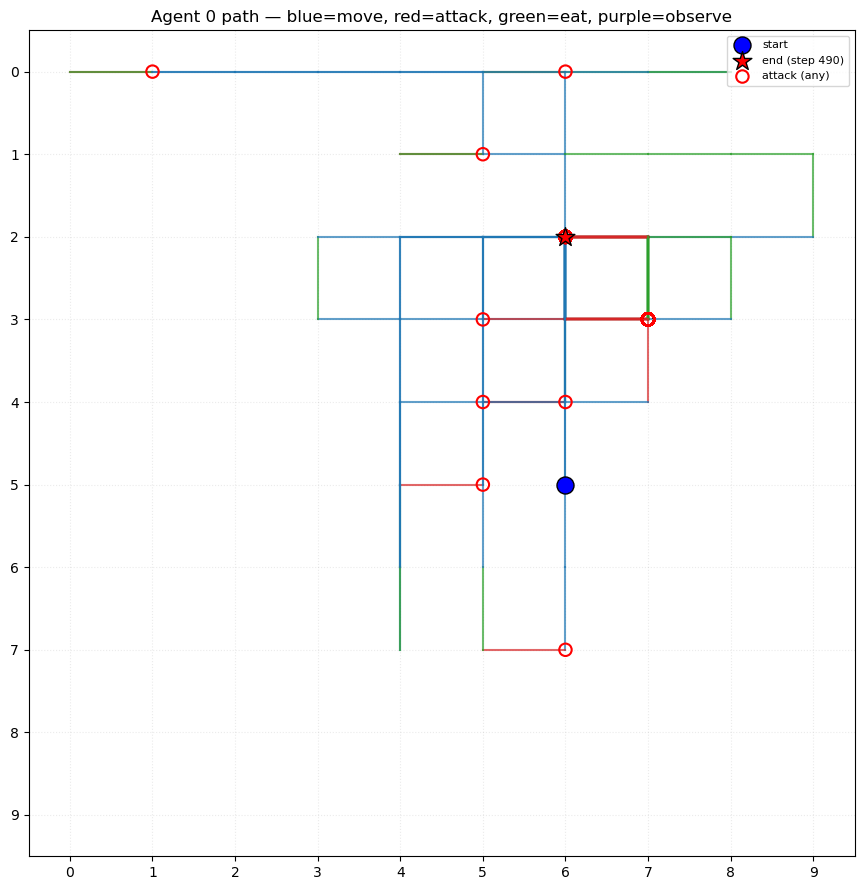

In [61]:
# ------------------------------------------------------------------
# 路径可视化（修正版）——从 body_before/body_after Lot 对象取坐标
# ------------------------------------------------------------------
def plot_agent_path_fixed(history, agent_id=0, size=10):
    path = []
    for h in history:
        if h.get("agent_id") != agent_id:
            continue
        x, y = _xy(h)
        if x is None:
            continue
        ap = h.get("action_plan") or {}
        path.append((h.get("step"), x, y, ap.get("action"), h.get("energy")))

    fig, ax = plt.subplots(figsize=(9, 9))
    color_map = {"move": "#1f77b4", "attack": "#d62728", "eat": "#2ca02c",
                 "observe": "#9467bd", "drop": "#8c564b",
                 "passive_starvation": "black"}
    for i in range(len(path) - 1):
        _, x0, y0, act0, _ = path[i]
        _, x1, y1, _, _ = path[i + 1]
        ax.plot([x0, x1], [y0, y1], "-", color=color_map.get(act0, "gray"),
                linewidth=1.5, alpha=0.7)

    # 起点/终点
    ax.scatter(path[0][1], path[0][2], s=150, c="blue", marker="o",
               edgecolors="black", zorder=5, label="start")
    ax.scatter(path[-1][1], path[-1][2], s=200, c="red", marker="*",
               edgecolors="black", zorder=5, label=f"end (step {path[-1][0]})")

    # 高亮 Metal 攻击点
    metal_pts = [(p[1], p[2]) for p in path if p[3] == "attack"]
    if metal_pts:
        ax.scatter([p[0] for p in metal_pts], [p[1] for p in metal_pts],
                   s=80, facecolors="none", edgecolors="red", linewidths=1.5,
                   label="attack (any)", zorder=4)

    ax.set_xlim(-0.5, size - 0.5); ax.set_ylim(-0.5, size - 0.5)
    ax.set_xticks(range(size)); ax.set_yticks(range(size))
    ax.set_aspect("equal")
    ax.grid(True, linestyle=":", alpha=0.25)
    ax.invert_yaxis()
    ax.set_title(f"Agent {agent_id} path — blue=move, red=attack, green=eat, purple=observe")
    ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()


plot_agent_path_fixed(rw_smoke_history, agent_id=0, size=10)

## Real Test Result Output  

In [62]:
# ============================================================
# FINAL CELL — 全数据导出成一个 Excel（备查）
# 依赖：df_rw, rw_smoke_history, combo_wood, metal_rejected_steps,
#       metal_attacks, qdf, summary_df, nursery_history,
#       memory_snapshots, a1_final
# ============================================================

import json
from datetime import datetime
from pathlib import Path
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 0) 输出路径
# ------------------------------------------------------------
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
archive_dir = Path("full_export") / datetime.now().strftime("%Y%m%d")
archive_dir.mkdir(parents=True, exist_ok=True)

out_path = archive_dir / (
    f"FULL_export_{ts}"
    f"_seed{cfg_smoke.seed}"
    f"_n{cfg_smoke.n_agents}"
    f"_rwsteps{len(rw_smoke_history)}"
    f"_nursery{len(nursery_history) if 'nursery_history' in globals() else 0}"
    f".xlsx"
)

print(f"目标文件：{out_path.resolve()}")


# ------------------------------------------------------------
# 1) 兜底：确保 df_rw / combo_wood / metal_rejected_steps 存在
# ------------------------------------------------------------
if "df_rw" not in globals():
    df_rw = flatten_rw_history(rw_smoke_history)

if "combo_wood" not in globals():
    combo_wood = extract_combo_sequences(df_rw, "Wood")

if "metal_rejected_steps" not in globals():
    metal_rejected_steps = []
    for h in rw_smoke_history:
        bt = h.get("bayes_trace") or {}
        for r in bt.get("rejected", []):
            if r.get("object") == "Metal":
                metal_rejected_steps.append({
                    "step": h.get("step"),
                    "reason": r.get("rejected_reason"),
                    "death_dist": r.get("death_dist"),
                    "current_dist": r.get("current_dist"),
                })

if "metal_attacks" not in globals():
    metal_attacks = df_rw[df_rw["chosen_obj"] == "Metal"]


# ------------------------------------------------------------
# 2) 拍平 bayes_trace（每步一行，candidates/rejected 压成 JSON）
# ------------------------------------------------------------
def flatten_bayes_trace(history):
    rows = []
    for h in history:
        bt = h.get("bayes_trace") or {}
        chosen = bt.get("chosen") or {}
        candidates = bt.get("candidates", [])
        rejected = bt.get("rejected", [])

        rows.append({
            "step":           h.get("step"),
            "agent_id":       h.get("agent_id"),
            "action":         (h.get("action_plan") or {}).get("action"),
            "source":         (h.get("action_plan") or {}).get("source"),
            "route":          h.get("route"),
            "had_need":       bt.get("had_need"),
            "chosen_object":  chosen.get("object") if isinstance(chosen, dict) else None,
            "chosen_stage":   chosen.get("stage") if isinstance(chosen, dict) else None,
            "chosen_dist":    chosen.get("current_dist") if isinstance(chosen, dict) else None,
            "chosen_seq":     json.dumps(chosen.get("action_seq"), ensure_ascii=False) if isinstance(chosen, dict) else None,
            "chosen_move_to": chosen.get("move_to") if isinstance(chosen, dict) else None,
            "n_candidates":   len(candidates),
            "n_rejected":     len(rejected),
            "n_info_objects": len((h.get("action_plan") or {}).get("info_flow", {}).get("objects", [])),
            "candidates_json": json.dumps(candidates, ensure_ascii=False, default=str),
            "rejected_json":   json.dumps(rejected, ensure_ascii=False, default=str),
        })
    return pd.DataFrame(rows)


df_bayes_raw = flatten_bayes_trace(rw_smoke_history)
print(f"df_bayes_raw shape: {df_bayes_raw.shape}")


# ------------------------------------------------------------
# 3) 拍平 nursery_history（如果存在）
# ------------------------------------------------------------
def flatten_nursery_history(history):
    if not history:
        return pd.DataFrame()
    rows = []
    for h in history:
        ap = h.get("action_plan") or {}
        bt = h.get("bayes_trace") or {}
        chosen = bt.get("chosen") or {}
        detail = (h.get("result") or {}).get("detail") or {}
        needs = h.get("needs") or {}
        rows.append({
            "step":           h.get("step"),
            "energy":         h.get("energy"),
            "alive":          h.get("alive"),
            "hungry":         needs.get("hungry"),
            "health":         needs.get("health"),
            "action":         ap.get("action"),
            "source":         ap.get("source"),
            "route":          h.get("route"),
            "target_element": ap.get("target_element"),
            "move_to":        ap.get("move_to"),
            "chosen_obj":     chosen.get("object") if isinstance(chosen, dict) else None,
            "chosen_dist":    chosen.get("current_dist") if isinstance(chosen, dict) else None,
            "chosen_seq":     json.dumps(chosen.get("action_seq"), ensure_ascii=False) if isinstance(chosen, dict) else None,
            "result_success": (h.get("result") or {}).get("success"),
            "result_eaten":   detail.get("eaten"),
            "result_energy_gain": detail.get("energy_gained"),
            "damage_taken":   detail.get("damage_taken"),
            "fail_reason":    detail.get("reason"),
            "actual_need_resolved": h.get("actual_need_resolved"),
            "forbidden":      h.get("forbidden_triggered"),
        })
    return pd.DataFrame(rows)


df_nursery_flat = flatten_nursery_history(
    nursery_history if "nursery_history" in globals() else []
)
print(f"df_nursery_flat shape: {df_nursery_flat.shape}")


# ------------------------------------------------------------
# 4) collapsed_memory dump（nursery 结束时）
# ------------------------------------------------------------
def dump_collapsed_memory(a1):
    rows = []
    if a1 is None:
        return pd.DataFrame()
    for mem_name, mem_dict in (a1.collapsed_memory or {}).items():
        for sig, entry in mem_dict.items():
            rows.append({
                "memory_name": mem_name,
                "counter":     entry.get("counter", 1),
                "action":      entry.get("action"),
                "result_success": (entry.get("result") or {}).get("success") if isinstance(entry.get("result"), dict) else None,
                "reason":      entry.get("reason"),
                "entry_json":  json.dumps(entry, ensure_ascii=False, default=str),
            })
    return pd.DataFrame(rows)


df_collapsed = dump_collapsed_memory(
    a1_final if "a1_final" in globals() else None
)
print(f"df_collapsed shape: {df_collapsed.shape}")


# ------------------------------------------------------------
# 5) Eat events（含 gap / energy_before）
# ------------------------------------------------------------
def build_eat_events(history):
    rows = []
    prev_step = None
    for h in history:
        ap = h.get("action_plan") or {}
        detail = (h.get("result") or {}).get("detail") or {}
        if ap.get("action") != "eat":
            continue
        eaten = detail.get("eaten")
        if not eaten:
            continue
        x, y = _xy(h)
        energy_gain = detail.get("energy_gained", 0)
        energy_after = h.get("energy")
        energy_before = (energy_after - energy_gain) if energy_after is not None else None
        gap = (h.get("step") - prev_step) if prev_step is not None else None
        prev_step = h.get("step")
        rows.append({
            "step":          h.get("step"),
            "agent_id":      h.get("agent_id"),
            "x": x, "y": y,
            "eaten":         eaten,
            "energy_gain":   energy_gain,
            "energy_before": energy_before,
            "energy_after":  energy_after,
            "damage_taken":  detail.get("damage_taken"),
            "gap_since_last_eat": gap,
            "source":        ap.get("source"),
            "is_defeated":   detail.get("is_defeated"),
            "target_defence": detail.get("target_defence"),
        })
    return pd.DataFrame(rows)


df_eat = build_eat_events(rw_smoke_history)
print(f"df_eat shape: {df_eat.shape}")


# ------------------------------------------------------------
# 6) 写 Excel（多 sheet）
# ------------------------------------------------------------
with pd.ExcelWriter(out_path, engine="openpyxl") as writer:

    # --- S1 ---
    src_table.to_excel(writer, sheet_name="S1_Source_Distribution", index=False)
    cross.to_excel(writer, sheet_name="S1_Action_Source_Cross")

    # --- S2 ---
    pd.DataFrame(combo_wood).to_excel(
        writer, sheet_name="S2_Combo_Wood", index=False
    )

    # --- S3 ---
    pd.DataFrame(metal_rejected_steps).to_excel(
        writer, sheet_name="S3_Metal_Rejected", index=False
    )
    metal_attacks.to_excel(
        writer, sheet_name="S3_Metal_Attacked", index=False
    )
    # step 161 快照
    step161 = next(
        (h for h in rw_smoke_history if h.get("step") == 161), None
    )
    if step161 is not None:
        snap_rows = []
        ap161 = step161.get("action_plan") or {}
        bt161 = step161.get("bayes_trace") or {}
        chosen161 = bt161.get("chosen") or {}
        for o in (ap161.get("info_flow") or {}).get("objects", []):
            name = o.get("name")
            dist = None
            quad = "?"
            for c in bt161.get("candidates", []):
                if c.get("object") == name:
                    dist = c.get("current_dist")
                    quad = c.get("quadrant", "?")
                    break
            snap_rows.append({
                "step": 161,
                "name": name,
                "x": o.get("x"), "y": o.get("y"),
                "energy_gain_records": json.dumps(o.get("energy_gain_records")),
                "known_attack": o.get("known_attack"),
                "known_defence": o.get("known_defence"),
                "is_defeated": o.get("is_defeated"),
                "is_defeated_by_memory": o.get("is_defeated_by_memory"),
                "current_dist": dist,
                "quadrant": quad,
                "is_chosen": (name == chosen161.get("object")),
            })
        pd.DataFrame(snap_rows).to_excel(
            writer, sheet_name="S3_Step_Case_161", index=False
        )

    # --- S4 ---
    qdf.to_excel(writer, sheet_name="S4_Quadrant_Stats", index=False)

    # --- S5 ---
    s5_rows = []
    if not metal_attacks.empty:
        for _, r in metal_attacks.iterrows():
            s5_rows.append({
                "step": r["step"], "event": "attacked",
                "energy": r["energy"], "success": r["result_success"],
            })
    for r in metal_rejected_steps:
        s5_rows.append({
            "step": r["step"], "event": "rejected",
            "energy": None, "success": None,
            "reason": r["reason"], "death_dist": r["death_dist"],
            "current_dist": r["current_dist"],
        })
    pd.DataFrame(s5_rows).sort_values("step").to_excel(
        writer, sheet_name="S5_Metal_Timeline", index=False
    )

    # --- Summary Table 1 ---
    summary_df.to_excel(writer, sheet_name="Summary_Table1", index=False)

    # --- 全量 RW history ---
    df_rw.to_excel(writer, sheet_name="RW_History_Flat", index=False)

    # --- 全量 Nursery history（如果存在）---
    if not df_nursery_flat.empty:
        df_nursery_flat.to_excel(
            writer, sheet_name="Nursery_History_Flat", index=False
        )

    # --- Nursery memory snapshots ---
    if "memory_snapshots" in globals() and memory_snapshots:
        pd.DataFrame(memory_snapshots).to_excel(
            writer, sheet_name="Nursery_Memory_Snapshots", index=False
        )

    # --- Collapsed memory dump ---
    if not df_collapsed.empty:
        df_collapsed.to_excel(
            writer, sheet_name="Collapsed_Memory_Dump", index=False
        )

    # --- Eat events ---
    df_eat.to_excel(writer, sheet_name="Eat_Events", index=False)

    # --- Raw bayes trace ---
    df_bayes_raw.to_excel(writer, sheet_name="Raw_Bayes_Trace", index=False)

    # --- shared_bank stats（如果存在）---
    if "shared_bank" in globals():
        bank_stats = pd.DataFrame(
            [{"memory": k, "count": v}
             for k, v in shared_bank.stats().items()]
        )
        bank_stats.to_excel(
            writer, sheet_name="Shared_Bank_Stats", index=False
        )


# ------------------------------------------------------------
# 7) 打印清单
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("✅ 全数据导出完成")
print("=" * 70)
print(f"文件：{out_path.resolve()}")
print("\n包含的 sheet：")
for i, name in enumerate([
    "S1_Source_Distribution", "S1_Action_Source_Cross",
    "S2_Combo_Wood",
    "S3_Metal_Rejected", "S3_Metal_Attacked", "S3_Step_Case_161",
    "S4_Quadrant_Stats",
    "S5_Metal_Timeline",
    "Summary_Table1",
    "RW_History_Flat",
    "Nursery_History_Flat",
    "Nursery_Memory_Snapshots",
    "Collapsed_Memory_Dump",
    "Eat_Events",
    "Raw_Bayes_Trace",
    "Shared_Bank_Stats",
], 1):
    print(f"  {i:>2}. {name}")

print("\n各 sheet 行数：")
for name, shape in [
    ("S1_Source_Distribution", src_table.shape),
    ("S1_Action_Source_Cross", cross.shape),
    ("S2_Combo_Wood", (len(combo_wood), 1)),
    ("S3_Metal_Rejected", (len(metal_rejected_steps), 1)),
    ("S3_Metal_Attacked", metal_attacks.shape),
    ("S4_Quadrant_Stats", qdf.shape),
    ("S5_Metal_Timeline", (len(s5_rows), 1)),
    ("Summary_Table1", summary_df.shape),
    ("RW_History_Flat", df_rw.shape),
    ("Nursery_History_Flat", df_nursery_flat.shape),
    ("Eat_Events", df_eat.shape),
    ("Raw_Bayes_Trace", df_bayes_raw.shape),
    ("Collapsed_Memory_Dump", df_collapsed.shape),
]:
    print(f"  {name:30s} rows={shape[0]:>5}  cols={shape[1]:>3}")

目标文件：C:\Users\lgzaw\Desktop\ottawa\phD DTI\conciousness hardship test\separate papers\full_export\20261030\FULL_export_20261030_204009_seed42_n1_rwsteps490_nursery820.xlsx
df_bayes_raw shape: (490, 16)
df_nursery_flat shape: (820, 20)
df_collapsed shape: (301, 6)
df_eat shape: (50, 13)


C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3374941810.py:305: UserWarning: Cell contents too long (34336), truncated to 32767 characters
  df_collapsed.to_excel(
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3374941810.py:305: UserWarning: Cell contents too long (34374), truncated to 32767 characters
  df_collapsed.to_excel(
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3374941810.py:305: UserWarning: Cell contents too long (89097), truncated to 32767 characters
  df_collapsed.to_excel(
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3374941810.py:305: UserWarning: Cell contents too long (89131), truncated to 32767 characters
  df_collapsed.to_excel(
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3374941810.py:305: UserWarning: Cell contents too long (43656), truncated to 32767 characters
  df_collapsed.to_excel(
C:\Users\lgzaw\AppData\Local\Temp\ipykernel_33528\3374941810.py:305: UserWarning: Cell contents too long (44753), truncated to 32767 characters
  df_collap


✅ 全数据导出完成
文件：C:\Users\lgzaw\Desktop\ottawa\phD DTI\conciousness hardship test\separate papers\full_export\20261030\FULL_export_20261030_204009_seed42_n1_rwsteps490_nursery820.xlsx

包含的 sheet：
   1. S1_Source_Distribution
   2. S1_Action_Source_Cross
   3. S2_Combo_Wood
   4. S3_Metal_Rejected
   5. S3_Metal_Attacked
   6. S3_Step_Case_161
   7. S4_Quadrant_Stats
   8. S5_Metal_Timeline
   9. Summary_Table1
  10. RW_History_Flat
  11. Nursery_History_Flat
  12. Nursery_Memory_Snapshots
  13. Collapsed_Memory_Dump
  14. Eat_Events
  15. Raw_Bayes_Trace
  16. Shared_Bank_Stats

各 sheet 行数：
  S1_Source_Distribution         rows=    3  cols=  3
  S1_Action_Source_Cross         rows=    7  cols=  4
  S2_Combo_Wood                  rows=   33  cols=  1
  S3_Metal_Rejected              rows=  305  cols=  1
  S3_Metal_Attacked              rows=  191  cols= 27
  S4_Quadrant_Stats              rows=    2  cols=  6
  S5_Metal_Timeline              rows=  496  cols=  1
  Summary_Table1           